<h1 align="center" style="color:#1E3A5F; border-bottom: 3px solid #2196F3; padding-bottom: 10px;">🚛 FreightIQ – Unified Data Science Pipeline</h1>
<h3 align="center" style="color:#546E7A;">AWL Logistics – Freight Price Intelligence & Prediction</h3>
<h4 align="center" style="color:#78909C;">SS2026 AIM – Data Science and AI Business Project | Hochschule Furtwangen University</h4>

## 📋 Table of Contents

| Phase | Section | Description |
|:---:|:---|:---|
| <span style="color:#1565C0;">**1**</span> | [1. Setup & Data Loading](#1-Setup--Data-Loading) | Import libraries, configure paths, load CSV |
| <span style="color:#2E7D32;">**2**</span> | [2. Data Understanding](#2-Data-Understanding) | Shape, statistics, quality checks, outliers |
| <span style="color:#E65100;">**3**</span> | [3. Data Cleaning & Preparation](#3-Data-Cleaning--Preparation) | Source/destination/vehicle corrections |
| <span style="color:#6A1B9A;">**4**</span> | [4. FreightIQ Enrichment Pipeline](#4-FreightIQ-Enrichment-Pipeline) | State mapping + distance + before/after viz |
| <span style="color:#C62828;">**5**</span> | [5. Exploratory Data Analysis](#5-Exploratory-Data-Analysis) | All EDA visualizations |


---
<a id="1-Setup--Data-Loading"></a>
# <span style="color:#1565C0;">1. Setup & Data Loading</span>
> **CRISP-DM Phase 1 — Business Understanding & Data Access**

This section imports all required libraries and loads the freight dataset.
All file paths are parameterized at the top for easy configuration.

### 1.1 Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import json
import gzip
import base64
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", context="notebook")

print("✅ All libraries loaded successfully.")

✅ All libraries loaded successfully.


### 1.2 Configuration — File Paths
> ⚠️ **Update the CSV path** to match your local environment before running.
> Destination state and pair distance mappings are embedded as compact horizontal dicts in §4 and §4.9.

In [5]:
# ============================================================
# CONFIGURATION — UPDATE THIS PATH TO YOUR LOCAL ENVIRONMENT
# ============================================================

# FINAL_DATA_PATH = r"C:\Users\HP\Downloads\FINAL_enriched_logistics_data_FIXED.csv"

RAW_DATA_PATH = r"Transport_Market_Price.csv"



print("✅ Configuration set. Update RAW_DATA_PATH above if needed.")

✅ Configuration set. Update RAW_DATA_PATH above if needed.


### 1.3 Load Dataset

In [6]:
df = pd.read_csv(RAW_DATA_PATH)
# df = df.iloc[:1000]
df['Date'] = pd.to_datetime(df['Date'], format='mixed', utc=True)
df = df.sort_values("Date").reset_index(drop=True)

print(f"✅ Dataset loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"   Date range: {df['Date'].min().date()} → {df['Date'].max().date()}")
df.head()

✅ Dataset loaded: 423,311 rows × 21 columns
   Date range: 2022-01-01 → 2025-12-31


,Date,Contract_type,New_contract_type,Route_name,Source,Source_State,Destination,Destination_State,Distance,Vehicle_Type,...,Pricing_Type,Cost,Price_per_KM,Vehicle_Load,Product,week,month,Month,Year,Financial_year
0,2022-01-01 00:00:00+00:00,SHORT,NORMAL,HALDIA - CHHIBRAMAU,HALDIA,WEST BENGAL,chhibramau,UP,1243.0,20 MT,...,Rate/MT,2890.0,2.539908,NaN,Edible Oil,0,1,January,2022,21-22
1,2022-01-01 00:00:00+00:00,SHORT,NORMAL,JAIPUR - BANGALORE,Jaipur,Rajasthan,bangalore,Karnataka,2016.0,Any Vehicle,...,Rate/MT,5910.0,3.176587,NaN,Edible Oil,0,1,January,2022,21-22
2,2022-01-01 00:00:00+00:00,SHORT,NORMAL,BUNDI - GORAKHPUR,BUNDI,Rajasthan,gorakhpur,Uttar Pradesh,1025.0,Any Vehicle,...,Rate/MT,3030.0,3.196341,NaN,Edible Oil,0,1,January,2022,21-22
3,2022-01-01 00:00:00+00:00,SHORT,NORMAL,BUNDI - BARMER,BUNDI,Rajasthan,barmer,Rajasthan,567.0,Any Vehicle,...,Rate/MT,1350.0,2.477588,NaN,Edible Oil,0,1,January,2022,21-22
4,2022-01-01 00:00:00+00:00,SHORT,NORMAL,HALDIA - SHAHJAHANPUR,HALDIA,WEST BENGAL,shahjahanpur,UP,1257.0,20 MT,...,Rate/MT,3250.0,2.202962,NaN,Edible Oil,0,1,January,2022,21-22


In [7]:
# df_new = pd.read_csv(FINAL_DATA_PATH, parse_dates=["Date"])


---
<a id="2-Data-Understanding"></a>
# <span style="color:#2E7D32;">2. Data Understanding</span>
> **CRISP-DM Phase 2 — Explore, describe, and assess data quality**

<a id="2.1-Initial-Data-Report"></a>
## <span style="color:#388E3C;">2.1 Initial Data Report</span>

In [8]:
print("Shape:", df.shape)
print()
df.head()

Shape: (423311, 21)



,Date,Contract_type,New_contract_type,Route_name,Source,Source_State,Destination,Destination_State,Distance,Vehicle_Type,...,Pricing_Type,Cost,Price_per_KM,Vehicle_Load,Product,week,month,Month,Year,Financial_year
0,2022-01-01 00:00:00+00:00,SHORT,NORMAL,HALDIA - CHHIBRAMAU,HALDIA,WEST BENGAL,chhibramau,UP,1243.0,20 MT,...,Rate/MT,2890.0,2.539908,NaN,Edible Oil,0,1,January,2022,21-22
1,2022-01-01 00:00:00+00:00,SHORT,NORMAL,JAIPUR - BANGALORE,Jaipur,Rajasthan,bangalore,Karnataka,2016.0,Any Vehicle,...,Rate/MT,5910.0,3.176587,NaN,Edible Oil,0,1,January,2022,21-22
2,2022-01-01 00:00:00+00:00,SHORT,NORMAL,BUNDI - GORAKHPUR,BUNDI,Rajasthan,gorakhpur,Uttar Pradesh,1025.0,Any Vehicle,...,Rate/MT,3030.0,3.196341,NaN,Edible Oil,0,1,January,2022,21-22
3,2022-01-01 00:00:00+00:00,SHORT,NORMAL,BUNDI - BARMER,BUNDI,Rajasthan,barmer,Rajasthan,567.0,Any Vehicle,...,Rate/MT,1350.0,2.477588,NaN,Edible Oil,0,1,January,2022,21-22
4,2022-01-01 00:00:00+00:00,SHORT,NORMAL,HALDIA - SHAHJAHANPUR,HALDIA,WEST BENGAL,shahjahanpur,UP,1257.0,20 MT,...,Rate/MT,3250.0,2.202962,NaN,Edible Oil,0,1,January,2022,21-22


In [9]:
df.tail()

,Date,Contract_type,New_contract_type,Route_name,Source,Source_State,Destination,Destination_State,Distance,Vehicle_Type,...,Pricing_Type,Cost,Price_per_KM,Vehicle_Load,Product,week,month,Month,Year,Financial_year
423306,2025-12-31 10:14:48.994000+00:00,SPOT,NORMAL,VIDISHA - REWARI,Vidisha,Madhya Pradesh,rewari,Haryana,724.000000,SINGLE AXLE CONTAINER 6 MT 20 FT,...,Rate/Trip,24960.0,34.711326,6.5,Nuggets,52,12,December,2025,25-26
423307,2025-12-31 10:37:22.395000+00:00,SPOT,NORMAL,MANGALURU - TERDAL,Mangaluru,KARNATAKA,terdal,Karnataka,536.000000,TAURUS 25 MT (12 TYRE),...,Rate/MT,1550.0,3.123134,25.5,Edible Oil,52,12,December,2025,25-26
423308,2025-12-31 10:50:37.710000+00:00,DAILY,NORMAL,GOHANA - SURAT,GOHANA,Haryana,surat,Gujarat,1246.666667,TRAILER 34 MT 40 FT,...,Rate/MT,2610.0,2.335561,36.0,Edible Oil,52,12,December,2025,25-26
423309,2025-12-31 11:10:07.172000+00:00,DAILY,NORMAL,NEEMUCH - DELHI,NEEMUCH,Madhya Pradesh,delhi,Delhi,641.000000,TRAILER 40 MT 40 FT,...,Rate/MT,2470.0,4.087754,42.5,Edible Oil,52,12,December,2025,25-26
423310,2025-12-31 11:11:36.616000+00:00,DAILY,NORMAL,BHATAPARA - LUCKNOW,Bhatapara,Chhattisgarh,lucknow,Uttar Pradesh,743.000000,MULTI AXLE CONTAINER 18 MT 32 FT,...,Rate/Trip,59910.0,80.869112,19.5,Food,52,12,December,2025,25-26


In [10]:
df.sample(5)

,Date,Contract_type,New_contract_type,Route_name,Source,Source_State,Destination,Destination_State,Distance,Vehicle_Type,...,Pricing_Type,Cost,Price_per_KM,Vehicle_Load,Product,week,month,Month,Year,Financial_year
417160,2025-11-25 11:23:49.202000+00:00,SHORT,NORMAL,CHANDAULI - AZAMNAGAR,Chandauli,Uttar Pradesh,azamnagar,Bihar,610.0,TAURUS 25 MT (12 TYRE),...,Rate/MT,1900.0,3.348361,25.5,Flour,47,11,November,2025,25-26
194276,2023-11-08 00:00:00+00:00,MONTHLY,NORMAL,HALDIA - MURARI,Haldia,West Bengal,murari,West Bengal,208.0,TAURUS 21-22 MT (12 TYRE),...,Rate/MT,1620.0,7.990385,23.5,Edible Oil,45,11,November,2023,23-24
245772,2024-04-01 00:00:00+00:00,SHORT,NORMAL,HOSKOTE - KUNIGAL,HOSKOTE,KARNATAKA,kunigal,KARNATAKA,98.0,BADA DOST 03 MT 9 FT,...,Rate/MT,2290.0,23.515306,4.0,Food,13,4,April,2024,24-25
384832,2025-06-12 11:56:48.243000+00:00,LONG,NORMAL,BARDHAMAN - AMTA,BARDHAMAN,West Bengal,amta,West Bengal,121.0,BADA DOST 03 MT 9 FT,...,Rate/MT,1410.0,11.820248,4.0,Flour,23,6,June,2025,INFORM DAAI TEAM
170235,2023-09-04 00:00:00+00:00,SHORT,NORMAL,HAZIRA - KORBA,HAZIRA,Gujarat,korba,Chhattisgarh,1316.0,TAURUS 30 MT (14 TYRE),...,Rate/MT,4343.0,3.542553,30.5,Edible Oil,36,9,September,2023,23-24


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 423311 entries, 0 to 423310
Data columns (total 21 columns):
 #   Column             Non-Null Count   Dtype              
---  ------             --------------   -----              
 0   Date               423311 non-null  datetime64[us, UTC]
 1   Contract_type      423309 non-null  str                
 2   New_contract_type  423311 non-null  str                
 3   Route_name         423311 non-null  str                
 4   Source             423311 non-null  str                
 5   Source_State       423311 non-null  str                
 6   Destination        423311 non-null  str                
 7   Destination_State  423307 non-null  str                
 8   Distance           423311 non-null  float64            
 9   Vehicle_Type       423307 non-null  str                
 10  Vehicle_body_type  422957 non-null  str                
 11  Pricing_Type       423293 non-null  str                
 12  Cost               423311 non-null  float

In [12]:
print("Columns:")
print(df.columns.tolist())

Columns:
['Date', 'Contract_type', 'New_contract_type', 'Route_name', 'Source', 'Source_State', 'Destination', 'Destination_State', 'Distance', 'Vehicle_Type', 'Vehicle_body_type', 'Pricing_Type', 'Cost', 'Price_per_KM', 'Vehicle_Load', 'Product', 'week', 'month', 'Month', 'Year', 'Financial_year']


<a id="2.2-Describing-Data"></a>
## <span style="color:#388E3C;">2.2 Describing Data</span>

#### 2.2.1 Feature Categorization

In [13]:
df['Date'] = (pd.to_datetime(df['Date'], utc=True, errors='coerce').dt.tz_localize(None))
print(df['Date'].dtype)

# Numerical columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Categorical columns
cat_cols = df.select_dtypes(include=['object']).columns

# Datetime columns
date_cols = df.select_dtypes(include=['datetime']).columns

print("Numerical Columns:")
print(num_cols)

print("\nCategorical Columns:")
print(cat_cols)

print("\nDatetime Columns:")
print(date_cols)

datetime64[us]
Numerical Columns:
Index(['Distance', 'Cost', 'Price_per_KM', 'Vehicle_Load', 'week', 'month',
       'Year'],
      dtype='str')

Categorical Columns:
Index(['Contract_type', 'New_contract_type', 'Route_name', 'Source',
       'Source_State', 'Destination', 'Destination_State', 'Vehicle_Type',
       'Vehicle_body_type', 'Pricing_Type', 'Product', 'Month',
       'Financial_year'],
      dtype='str')

Datetime Columns:
Index(['Date'], dtype='str')


In [14]:
import pandas as pd
import numpy as np

# -----------------------------
# 1. Convert Date properly
# -----------------------------
df['Date'] = pd.to_datetime(df['Date'], utc=True, errors='coerce').dt.tz_localize(None)

# -----------------------------
# 2. Basic type detection
# -----------------------------
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
date_cols = df.select_dtypes(include=['datetime64[ns]']).columns.tolist()

print("Numerical Columns:")
print(num_cols)

print("\nCategorical Columns:")
print(cat_cols)

print("\nDatetime Columns:")
print(date_cols)

Numerical Columns:
['Distance', 'Cost', 'Price_per_KM', 'Vehicle_Load', 'week', 'month', 'Year']

Categorical Columns:
['Contract_type', 'New_contract_type', 'Route_name', 'Source', 'Source_State', 'Destination', 'Destination_State', 'Vehicle_Type', 'Vehicle_body_type', 'Pricing_Type', 'Product', 'Month', 'Financial_year']

Datetime Columns:
['Date']


In [15]:
# -----------------------------
# 3. Detailed column classification
# -----------------------------

column_classification = {
    # Temporal
    "Date": {
        "main_type": "Temporal",
        "detailed_type": "Datetime / Interval",
        "role": "Transaction date"
    },

    # Ratio numerical variables
    "Distance": {
        "main_type": "Numerical",
        "detailed_type": "Continuous Ratio",
        "role": "Input feature"
    },
    "Cost": {
        "main_type": "Numerical",
        "detailed_type": "Continuous Ratio",
        "role": "Target variable"
    },
    "Price_per_KM": {
        "main_type": "Numerical",
        "detailed_type": "Continuous Ratio / Derived",
        "role": "Derived analytical feature"
    },
    "Vehicle_Load": {
        "main_type": "Numerical",
        "detailed_type": "Continuous Ratio",
        "role": "Input feature"
    },

    # Temporal ordinal numerical variables
    "week": {
        "main_type": "Numerical",
        "detailed_type": "Discrete Ordinal Temporal",
        "role": "Time feature"
    },
    "month": {
        "main_type": "Numerical",
        "detailed_type": "Discrete Ordinal Temporal",
        "role": "Time feature"
    },
    "Year": {
        "main_type": "Numerical",
        "detailed_type": "Discrete Ordinal Temporal",
        "role": "Time feature"
    },

    # Nominal categorical variables
    "Contract_type": {
        "main_type": "Categorical",
        "detailed_type": "Nominal",
        "role": "Contract category"
    },
    "Route_name": {
        "main_type": "Categorical",
        "detailed_type": "Nominal / Identifier-like",
        "role": "Route identifier"
    },
    "Source": {
        "main_type": "Categorical",
        "detailed_type": "Nominal Geographic",
        "role": "Origin city"
    },
    "Source_State": {
        "main_type": "Categorical",
        "detailed_type": "Nominal Geographic",
        "role": "Origin state"
    },
    "Destination": {
        "main_type": "Categorical",
        "detailed_type": "Nominal Geographic",
        "role": "Destination city"
    },
    "Destination_State": {
        "main_type": "Categorical",
        "detailed_type": "Nominal Geographic",
        "role": "Destination state"
    },
    "Vehicle_Type": {
        "main_type": "Categorical",
        "detailed_type": "Nominal / Semi-structured",
        "role": "Vehicle category"
    },
    "Vehicle_body_type": {
        "main_type": "Categorical",
        "detailed_type": "Nominal",
        "role": "Vehicle body category"
    },
    "Pricing_Type": {
        "main_type": "Categorical",
        "detailed_type": "Nominal / Binary",
        "role": "Pricing method"
    },
    "Product": {
        "main_type": "Categorical",
        "detailed_type": "Nominal",
        "role": "Product type"
    },

    # Ordinal categorical temporal variables
    "Month": {
        "main_type": "Categorical",
        "detailed_type": "Ordinal Temporal",
        "role": "Month name"
    },
    "Financial_year": {
        "main_type": "Categorical",
        "detailed_type": "Ordinal Temporal",
        "role": "Financial year"
    }
}

classification_df = pd.DataFrame.from_dict(column_classification, orient="index").reset_index()
classification_df = classification_df.rename(columns={"index": "column_name"})

classification_df

,column_name,main_type,detailed_type,role
0,Date,Temporal,Datetime / Interval,Transaction date
1,Distance,Numerical,Continuous Ratio,Input feature
2,Cost,Numerical,Continuous Ratio,Target variable
3,Price_per_KM,Numerical,Continuous Ratio / Derived,Derived analytical feature
4,Vehicle_Load,Numerical,Continuous Ratio,Input feature
5,week,Numerical,Discrete Ordinal Temporal,Time feature
6,month,Numerical,Discrete Ordinal Temporal,Time feature
7,Year,Numerical,Discrete Ordinal Temporal,Time feature
8,Contract_type,Categorical,Nominal,Contract category
9,Route_name,Categorical,Nominal / Identifier-like,Route identifier


##### Observations

- The dataset contains numerical, categorical, and temporal features.
- Numerical features mainly represent shipment distance, freight cost, pricing metrics, and vehicle load information.
- Categorical features describe contract types, logistics routes, vehicle categories, product types, and pricing strategies.
- The `Date` column was successfully converted into datetime format to support temporal and seasonal analysis.

#### 2.2.2 Numerical Features Summary

In [23]:
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Distance,423311.0,847.685143,547.809873,1.00,402.000000,770.000000,1234.000000,9164.00
Cost,423311.0,5913.891737,14475.477991,15.00,1740.000000,2710.000000,3700.000000,1009910.00
Price_per_KM,423311.0,9.317539,33.754400,0.25,2.988095,3.783333,5.401954,9490.25
Vehicle_Load,395877.0,24.576788,8.164366,3.00,20.000000,25.500000,30.500000,60.50
week,423311.0,25.547033,15.172403,0.00,13.000000,26.000000,39.000000,53.00
month,423311.0,6.476307,3.463156,1.00,4.000000,7.000000,10.000000,12.00
Year,423311.0,2023.470864,1.048360,2022.00,2023.000000,2023.000000,2024.000000,2025.00


##### Observations

- The dataset contains a wide range of shipment distances and freight costs, indicating both short-haul and long-haul logistics operations.
- Freight cost exhibits very high variability, with a maximum value significantly larger than the median, suggesting the presence of extreme high-cost shipments and potential outliers.
- `Price_per_KM` also shows substantial dispersion and extreme maximum values, indicating possible pricing anomalies or premium freight movements.
- Vehicle load values vary across shipments, reflecting diverse cargo capacities and transportation requirements.
- Temporal features such as week, month, and year indicate that the dataset spans multiple years and supports seasonal trend analysis.

#### 2.2.3 Categorical Features Summary

In [24]:
df[cat_cols].describe().T

,count,unique,top,freq
Contract_type,423309,5,SHORT,337844
Route_name,423311,13172,FEROZEPUR - SHAMBHU,539
Source,423311,305,HALDIA,53228
Source_State,423311,247,Gujarat,79452
Destination,423311,3502,bhiwandi,4088
Destination_State,423307,1240,Uttar Pradesh,36825
Vehicle_Type,423307,219,TAURUS 30 MT (14 TYRE),76877
Vehicle_body_type,422957,89,Full Punjab Body,274002
Pricing_Type,423293,2,Rate/MT,394354
Product,423311,19,Edible Oil,296156


##### Observations

- The dataset contains high-cardinality route and destination features, indicating extensive geographic coverage across freight operations.
- `SHORT` contracts dominate the dataset, suggesting that short-term freight agreements are more common than long-term contracts.
- The majority of shipments are priced using the `Rate/MT` pricing strategy.
- `Edible Oil` is the most frequently transported product category in the dataset.
- `TAURUS 30 MT (14 TYRE)` is the most commonly used vehicle type, reflecting heavy commercial freight movement.
- The `Vehicle_body_type` feature is dominated by `Full Punjab Body`, indicating a strong preference for this body configuration in freight transportation.

#### 2.2.4 Unique Value Analysis

In [25]:
unique_values = pd.DataFrame({
    'Unique_Values': df.nunique()
})

unique_values.sort_values(by='Unique_Values', ascending=False)

,Unique_Values
Price_per_KM,164249
Route_name,13172
Date,11704
Cost,10784
Destination,3502
Distance,3372
Destination_State,1240
Source,305
Source_State,247
Vehicle_Type,219


##### Observations

- The dataset contains several high-cardinality features such as `Route_name`, `Destination`, and `Price_per_KM`, indicating significant variability in logistics operations and freight pricing patterns.
- `Route_name` contains more than 13,000 unique transportation routes, reflecting extensive geographic coverage across shipment corridors.
- `Destination_State` exhibits unusually high cardinality, which may indicate inconsistent formatting or data quality issues requiring further validation.
- Numerical pricing-related features such as `Cost` and `Price_per_KM` contain a large number of distinct values, suggesting diverse pricing behaviors across shipments.
- Features such as `Pricing_Type`, `Contract_type`, and `Financial_year` contain relatively few categories and are suitable for grouped comparative analysis.

#### 2.2.5 Statistical Description

In [26]:
num_cols = ['Cost', 'Price_per_KM', 'Distance', 'Distance',
            'Vehicle_Load', 'month', 'week', 'Year']
num_cols = [c for c in num_cols if c in df.columns]
df[num_cols].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
Cost,423311.0,5913.89,14475.48,15.00,1740.00,2710.00,3700.0,1009910.00
Price_per_KM,423311.0,9.32,33.75,0.25,2.99,3.78,5.4,9490.25
Distance,423311.0,847.69,547.81,1.00,402.00,770.00,1234.0,9164.00
Distance,423311.0,847.69,547.81,1.00,402.00,770.00,1234.0,9164.00
Vehicle_Load,395877.0,24.58,8.16,3.00,20.00,25.50,30.5,60.50
month,423311.0,6.48,3.46,1.00,4.00,7.00,10.0,12.00
week,423311.0,25.55,15.17,0.00,13.00,26.00,39.0,53.00
Year,423311.0,2023.47,1.05,2022.00,2023.00,2023.00,2024.0,2025.00


In [27]:
# Top 5 largest and smallest Cost rows
print("Top 5 Largest Cost:")
display(df.nlargest(5, 'Cost'))
print("\nTop 5 Smallest Cost:")
display(df.nsmallest(5, 'Cost'))

Top 5 Largest Cost:


,Date,Contract_type,Route_name,Source,Source_State,Destination,Destination_State,Distance,Vehicle_Type,Vehicle_body_type,Pricing_Type,Cost,Price_per_KM,Vehicle_Load,Product,week,month,Month,Year,Financial_year
386547,2025-06-19 12:44:23.988,SHORT,SAONER - MURLIGANJ,SAONER,MAHARASHTRA,murliganj,Bihar,1340.0,MULTI AXLE CONTAINER 18 MT 32 FT,Container Body,Rate/Trip,1009910.0,753.906716,19.5,Nuggets,24,6,June,2025,INFORM DAAI TEAM
412832,2025-11-03 11:01:42.564,SHORT,FARAH - VARANASI,Farah,Uttar Pradesh,varanasi,Uttar Pradesh,600.0,EICHER 12 MT (06 TYRE),Full Punjab Body,Rate/Trip,350010.0,583.583333,14.5,Edible Oil,44,11,November,2025,25-26
211865,2023-12-28 00:00:00.000,LONG,BUNDI - LIKABALI,BUNDI,Rajasthan,likabali,Arunachal Pradesh,2486.0,TAURUS 30 MT (14 TYRE),Full Punjab Body,Rate/Trip,249510.0,100.612027,30.5,Edible Oil,52,12,December,2023,23-24
211904,2023-12-28 00:00:00.000,LONG,BUNDI - TEZU,BUNDI,Rajasthan,tezu,Arunachal Pradesh,2679.0,TAURUS 30 MT (14 TYRE),Full Punjab Body,Rate/Trip,248450.0,92.986096,30.5,Edible Oil,52,12,December,2023,23-24
252292,2024-04-13 00:00:00.000,SHORT,BUNDI - LIKABALI,BUNDI,Rajasthan,likabali,Arunachal Pradesh,2486.0,TAURUS 30 MT (14 TYRE),Full Punjab Body,Rate/Trip,244460.0,98.580652,30.5,Edible Oil,14,4,April,2024,24-25



Top 5 Smallest Cost:


,Date,Contract_type,Route_name,Source,Source_State,Destination,Destination_State,Distance,Vehicle_Type,Vehicle_body_type,Pricing_Type,Cost,Price_per_KM,Vehicle_Load,Product,week,month,Month,Year,Financial_year
317663,2024-10-15 00:00:00.000,LONG,MUNDRA - NAGPUR,Mundra,Gujarat,nagpur,Maharashtra,1208.0,TAURUS 30 MT (14 TYRE),Tanker,Rate/MT,15.0,0.254139,30.5,Edible Oil,41,10,October,2024,24-25
312239,2024-10-01 00:00:00.000,SHORT,BHIMASAR - KAITHAL,Bhimasar,Gujarat,kaithal,HARYANA,1222.0,TRAILER 40 MT 40 FT,Dala Body,Rate/MT,44.0,0.277823,42.5,Edible Oil,39,10,October,2024,24-25
311192,2024-09-30 00:00:00.000,SHORT,MUNDRA - REWARI,MUNDRA,GUJARAT,rewari,HARYANA,1072.0,TRAILER 40 MT 40 FT,Dala Body,Rate/MT,45.0,0.282649,42.5,Edible Oil,39,9,September,2024,24-25
401503,2025-09-01 17:48:49.396,SHORT,CHANDRAPUR - NAGPUR,CHANDRAPUR,MAHARASHTRA,nagpur,MAHARASHTRA,200.0,EICHER 9-10 MT 19-22 FT,Full Punjab Body,Rate/Trip,60.0,0.500000,13.0,Food,35,9,September,2025,INFORM DAAI TEAM
89553,2022-12-11 00:00:00.000,DAILY,NIMRANI - VADODARA,Nimrani,Madhya Pradesh,vadodara,Gujarat,350.0,TAURUS 25 MT (12 TYRE),Container Body,Rate/MT,70.0,0.421429,25.5,Flour,50,12,December,2022,22-23


#### 2.2.6 Skewness & Kurtosis

In [28]:
# Compute the skewness of Cost column
# Positive value → right-skewed distribution
# Negative value → left-skewed distribution
# Zero → symmetric (approximately)
print("Skewness of Cost:", df['Cost'].skew())

Skewness of Cost: 6.090536669676896


In [29]:
# Measures kurtosis of the Cost column
# Kurtosis value | Interpretation    | What it looks like
# ~0             | Normal-like       | Moderate tails
# > 0            | Heavy tails       | More extreme outliers
# < 0            | Light tails       | Fewer extreme values
print("Kurtosis of Cost:", df['Cost'].kurt())

Kurtosis of Cost: 88.82328501717885


In [30]:
# Skewness and Kurtosis for all numeric columns
print("Skewness:")
print(df[num_cols].skew().round(4))
print()
print("Kurtosis:")
print(df[num_cols].kurt().round(4))

Skewness:
Cost              6.0905
Price_per_KM    121.0242
Distance          0.7103
Distance          0.7103
Vehicle_Load     -0.0334
month            -0.0094
week              0.0024
Year              0.0038
dtype: float64

Kurtosis:
Cost               88.8233
Price_per_KM    27538.2637
Distance            0.6714
Distance            0.6714
Vehicle_Load        0.3070
month              -1.2170
week               -1.2117
Year               -1.1935
dtype: float64


<a id="2.2.7-Additional-Data-Understanding-Results"></a>
#### 2.2.7 Additional Data Understanding Results

> Inserted from `Data_understanding _to_be_Psted_new_Final_FreightIQ_Unified_Pipeline_v5.ipynb` and reorganized so each result block follows its matching topic header.


<a id="2-2-7-1-Plotting-Theme-Column-Overview"></a>
##### 2.2.7.1 Plotting Theme & Column Overview


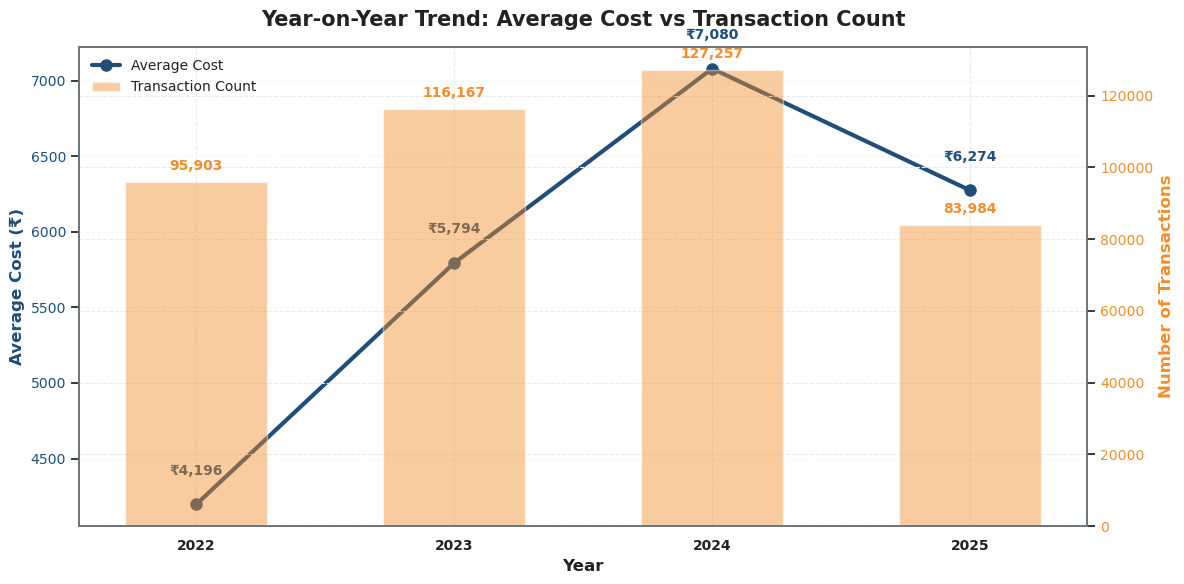

YEARLY SUMMARY: AVERAGE COST AND TRANSACTION COUNT


,Year,avg_cost,median_cost,transaction_count
0,2022,4196.0,2819.0,95903
1,2023,5794.0,2820.0,116167
2,2024,7080.0,2610.0,127257
3,2025,6274.0,2570.0,83984


YEAR-ON-YEAR CHANGE SUMMARY


,Year,avg_cost,median_cost,transaction_count,avg_cost_yoy_change_%,transaction_count_yoy_change_%
0,2022,4196.0,2819.0,95903,NaN,NaN
1,2023,5794.0,2820.0,116167,38.08,21.13
2,2024,7080.0,2610.0,127257,22.20,9.55
3,2025,6274.0,2570.0,83984,-11.38,-34.00


In [93]:
# ============================================================
# Common PPT Color Theme for All Graphs
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

# Main PPT-inspired color palette
PPT_COLORS = {
    "primary": "#1F4E79",      # deep blue
    "secondary": "#F28E2B",    # orange
    "accent": "#6A4C93",       # purple
    "green": "#59A14F",        # green
    "red": "#E15759",          # red
    "grey": "#6C757D",         # neutral grey
    "light_grey": "#EAEAEA",   # grid/background
    "dark": "#222222"          # text
}

# Ordered palette for categorical charts
PPT_PALETTE = [
    PPT_COLORS["primary"],
    PPT_COLORS["secondary"],
    PPT_COLORS["accent"],
    PPT_COLORS["green"],
    PPT_COLORS["red"],
    PPT_COLORS["grey"]
]

# Apply global plot style
sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": PPT_COLORS["grey"],
    "axes.labelcolor": PPT_COLORS["dark"],
    "xtick.color": PPT_COLORS["dark"],
    "ytick.color": PPT_COLORS["dark"],
    "text.color": PPT_COLORS["dark"],
    "axes.titleweight": "bold",
    "axes.titlesize": 15,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.frameon": False,
    "grid.color": PPT_COLORS["light_grey"],
    "grid.linestyle": "--",
    "grid.linewidth": 0.8,
    "font.family": "DejaVu Sans"
})





# ============================================================
# Bivariate Analysis: Year-on-Year Trend – Average Cost & Transaction Count
# Variables:
# 1. Year
# 2. Average Cost
# 3. Transaction Count
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Use cleaned dataframe if available, otherwise use df
plot_df = df_n.copy() if 'df_n' in globals() else df.copy()

# Ensure correct data types
plot_df['Year'] = pd.to_numeric(plot_df['Year'], errors='coerce')
plot_df['Cost'] = pd.to_numeric(plot_df['Cost'], errors='coerce')

# Remove missing values
plot_df = plot_df.dropna(subset=['Year', 'Cost'])

# Convert Year to integer
plot_df['Year'] = plot_df['Year'].astype(int)

# Group by Year
yearly_stats = (
    plot_df.groupby('Year')
    .agg(
        avg_cost=('Cost', 'mean'),
        median_cost=('Cost', 'median'),
        transaction_count=('Cost', 'count')
    )
    .reset_index()
)

# Sort by year
yearly_stats = yearly_stats.sort_values('Year')

# Round summary values
yearly_stats['avg_cost'] = yearly_stats['avg_cost'].round(0)
yearly_stats['median_cost'] = yearly_stats['median_cost'].round(0)

# Create figure and primary axis
fig, ax1 = plt.subplots(figsize=(12, 6))

# Colors from common PPT theme
color_line = PPT_COLORS["primary"]
color_bar = PPT_COLORS["secondary"]

# ------------------------------------------------------------
# Primary Y-axis: Average Cost Line
# ------------------------------------------------------------
ax1.plot(
    yearly_stats['Year'],
    yearly_stats['avg_cost'],
    marker='o',
    linestyle='-',
    linewidth=3,
    markersize=8,
    color=color_line,
    label='Average Cost'
)

ax1.set_xlabel('Year', fontsize=12, fontweight='bold')
ax1.set_ylabel('Average Cost (₹)', fontsize=12, color=color_line, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color_line)
ax1.grid(axis='y', linestyle='--', alpha=0.35)

# Add average cost labels
cost_offset = yearly_stats['avg_cost'].max() * 0.025

for _, row in yearly_stats.iterrows():
    ax1.text(
        row['Year'],
        row['avg_cost'] + cost_offset,
        f'₹{row["avg_cost"]:,.0f}',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
        color=color_line
    )

# ------------------------------------------------------------
# Secondary Y-axis: Transaction Count Bars
# ------------------------------------------------------------
ax2 = ax1.twinx()

bars = ax2.bar(
    yearly_stats['Year'],
    yearly_stats['transaction_count'],
    alpha=0.45,
    color=color_bar,
    width=0.55,
    label='Transaction Count'
)

ax2.set_ylabel('Number of Transactions', fontsize=12, color=color_bar, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_bar)

# Add transaction count labels on bars
count_offset = yearly_stats['transaction_count'].max() * 0.02

for bar, count in zip(bars, yearly_stats['transaction_count']):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + count_offset,
        f'{count:,}',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
        color=color_bar
    )

# ------------------------------------------------------------
# X-axis formatting
# ------------------------------------------------------------
ax1.set_xticks(yearly_stats['Year'])
ax1.set_xticklabels(yearly_stats['Year'], fontweight='bold')

# Title
plt.title(
    'Year-on-Year Trend: Average Cost vs Transaction Count',
    fontsize=15,
    fontweight='bold',
    pad=15
)

# Combined legend
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines_1 + lines_2,
    labels_1 + labels_2,
    loc='upper left',
    fontsize=10
)

# Clean layout
fig.tight_layout()

# Save image for PPT
plt.savefig(
    "yoy_average_cost_transaction_count.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# Numerical Summary
# ============================================================

print("=" * 75)
print("YEARLY SUMMARY: AVERAGE COST AND TRANSACTION COUNT")
print("=" * 75)

display(yearly_stats)

# Optional: Year-on-year percentage change
yearly_stats['avg_cost_yoy_change_%'] = yearly_stats['avg_cost'].pct_change() * 100
yearly_stats['transaction_count_yoy_change_%'] = yearly_stats['transaction_count'].pct_change() * 100

yearly_stats['avg_cost_yoy_change_%'] = yearly_stats['avg_cost_yoy_change_%'].round(2)
yearly_stats['transaction_count_yoy_change_%'] = yearly_stats['transaction_count_yoy_change_%'].round(2)

print("=" * 75)
print("YEAR-ON-YEAR CHANGE SUMMARY")
print("=" * 75)

display(yearly_stats)

In [47]:
df.columns

Index(['Date', 'Contract_type', 'New_contract_type', 'Route_name', 'Source',
       'Source_State', 'Destination', 'Destination_State', 'Distance',
       'Vehicle_Type', 'Vehicle_body_type', 'Pricing_Type', 'Cost',
       'Price_per_KM', 'Vehicle_Load', 'Product', 'week', 'month', 'Month',
       'Year', 'Financial_year'],
      dtype='str')

<a id="2-2-7-2-Contract-Type-Distribution"></a>
##### 2.2.7.2 Contract Type Distribution


In [49]:
# Assuming your DataFrame is named 'df'
dist = df['Contract_type'].value_counts(dropna=False)
print(dist)

# With percentages
dist_pct = df['Contract_type'].value_counts(normalize=True, dropna=False) * 100
print(dist_pct.round(1))

Contract_type
SHORT      337844
LONG        36904
MONTHLY     32998
DAILY       11330
SPOT         4233
NaN             2
Name: count, dtype: int64
Contract_type
SHORT      79.8
LONG        8.7
MONTHLY     7.8
DAILY       2.7
SPOT        1.0
NaN         0.0
Name: proportion, dtype: float64


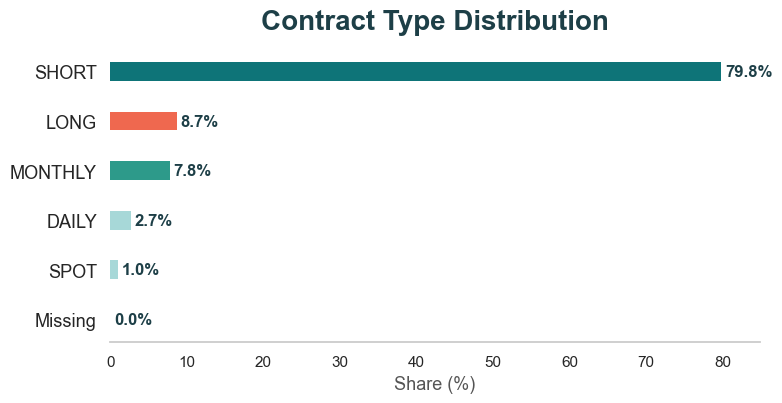

In [124]:
import matplotlib.pyplot as plt
import pandas as pd

# -----------------------------
# Contract Type Distribution
# -----------------------------

dist = df['Contract_type'].value_counts(dropna=False)

# Convert NaN to readable label
dist.index = ['Missing' if pd.isna(x) else x for x in dist.index]

# Calculate percentage
dist_pct = dist / dist.sum() * 100

# Color palette based on your reference graph
dark_teal = "#0E7478"
coral = "#EF684F"
green_teal = "#2D9A8A"
light_aqua = "#A7D8D8"
text_color = "#1D3F47"

colors = [
    dark_teal,
    coral,
    green_teal,
    light_aqua,
    light_aqua,
    light_aqua
]

# Smaller width makes the chart less wide
plt.figure(figsize=(8, 4.2))

bars = plt.barh(
    dist.index,
    dist_pct.values,
    color=colors[:len(dist)],
    edgecolor="none",
    height=0.38
)

plt.gca().invert_yaxis()

# Add percentage labels
for bar, pct in zip(bars, dist_pct.values):
    plt.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.1f}%",
        va="center",
        ha="left",
        fontsize=12,
        fontweight="bold",
        color=text_color
    )

plt.title(
    "Contract Type Distribution",
    fontsize=20,
    fontweight="bold",
    color=text_color,
    pad=14
)

plt.xlabel(
    "Share (%)",
    fontsize=13,
    color="#555555"
)

plt.ylabel("")

plt.xticks(fontsize=11)
plt.yticks(fontsize=13)

# Less empty space after the longest bar
plt.xlim(0, max(dist_pct.values) + 5)

for spine in ["top", "right", "left"]:
    plt.gca().spines[spine].set_visible(False)

plt.gca().spines["bottom"].set_linewidth(1.3)

plt.grid(False)
plt.tight_layout()
plt.show()

<a id="2-2-7-3-Pricing-Type-Distribution"></a>
##### 2.2.7.3 Pricing Type Distribution


In [125]:
import pandas as pd

# Load raw data
df_raw = pd.read_csv("Transport_Market_Price.csv")

# Compute distribution
counts = df_raw['Pricing_Type'].value_counts(dropna=False)
pct = df_raw['Pricing_Type'].value_counts(normalize=True, dropna=False) * 100

# Create and print summary table
summary = pd.DataFrame({'Count': counts, 'Percentage (%)': pct.round(2)}).reset_index()
summary.columns = ['Pricing_Type', 'Count', 'Percentage (%)']
print("="*50)
print("PRICING TYPE DISTRIBUTION (Raw Data)")
print("="*50)
print(summary.to_string(index=False))

PRICING TYPE DISTRIBUTION (Raw Data)
Pricing_Type  Count  Percentage (%)
     Rate/MT 394354           93.16
   Rate/Trip  28939            6.84
         NaN     18            0.00


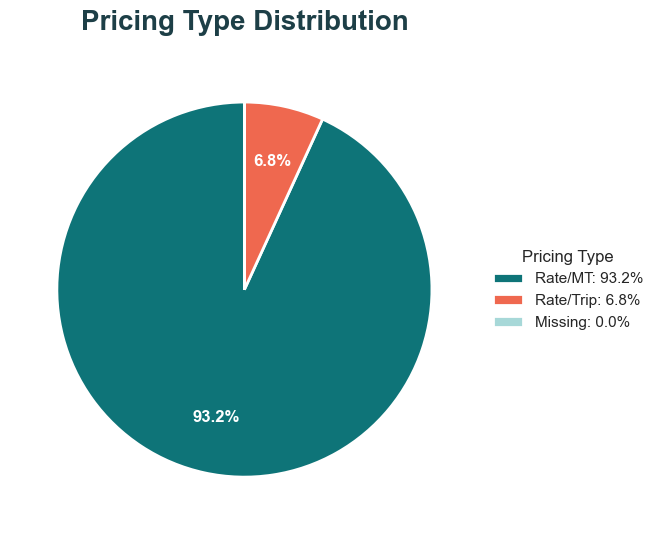

In [127]:
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Pricing Type Distribution
# -----------------------------

# Compute distribution
counts = df_raw['Pricing_Type'].value_counts(dropna=False)

# Convert NaN to readable label
counts.index = ['Missing' if pd.isna(x) else x for x in counts.index]

# Percentages
pct = counts / counts.sum() * 100

# Color palette based on your reference graph
dark_teal = "#0E7478"
coral = "#EF684F"
green_teal = "#2D9A8A"
light_aqua = "#A7D8D8"
text_color = "#1D3F47"

colors = [
    dark_teal,
    coral,
    light_aqua
]

# Create legend labels with percentages
legend_labels = [
    f"{label}: {value:.1f}%"
    for label, value in zip(counts.index, pct.values)
]

# Create figure
plt.figure(figsize=(7.5, 5.5))

# Pie chart without direct labels to avoid overlap
wedges, texts, autotexts = plt.pie(
    counts,
    labels=None,
    autopct=lambda p: f'{p:.1f}%' if p >= 1 else '',
    startangle=90,
    colors=colors[:len(counts)],
    pctdistance=0.7,
    wedgeprops={
        "edgecolor": "white",
        "linewidth": 2
    }
)

# Style percentage labels inside pie
for autotext in autotexts:
    autotext.set_color("white")
    autotext.set_fontsize(12)
    autotext.set_fontweight("bold")

# Title
plt.title(
    "Pricing Type Distribution",
    fontsize=20,
    fontweight="bold",
    color=text_color,
    pad=18
)

# Legend on the right
plt.legend(
    wedges,
    legend_labels,
    title="Pricing Type",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    fontsize=11,
    title_fontsize=12,
    frameon=False
)

plt.tight_layout()
plt.show()

<a id="2-2-7-4-Source-Destination-State-Distribution"></a>
##### 2.2.7.4 Source & Destination State Distribution


In [128]:
# ============================================================
# TOP 10 SOURCE STATES 
# ============================================================

# Use original state columns to match the case variations in output
source_col = 'Source_State'
dest_col = 'Destination_State'

# ---- Source States ----
src_counts = df[source_col].value_counts().head(10)
src_pct = df[source_col].value_counts(normalize=True).head(10) * 100

src_df = pd.DataFrame({
    'State': src_counts.index,
    'Count': src_counts.values,
    'Percentage (%)': src_pct.values.round(2)
})

print("=" * 60)
print("TOP 10 SOURCE STATES")
print("=" * 60)
print(src_df.to_string(index=False))
print("\n")



TOP 10 SOURCE STATES
         State  Count  Percentage (%)
       Gujarat  79452           18.77
   WEST BENGAL  42812           10.11
       Haryana  35194            8.31
Madhya Pradesh  34211            8.08
ANDHRA PRADESH  30106            7.11
     Rajasthan  27093            6.40
   West Bengal  26497            6.26
        Punjab  17572            4.15
       GUJARAT  15114            3.57
 Uttar Pradesh  15077            3.56




TOP 10 SOURCE STATES
         State  Count  Percentage (%)
       Gujarat  79452           18.77
   WEST BENGAL  42812           10.11
       Haryana  35194            8.31
Madhya Pradesh  34211            8.08
ANDHRA PRADESH  30106            7.11
     Rajasthan  27093            6.40
   West Bengal  26497            6.26
        Punjab  17572            4.15
       GUJARAT  15114            3.57
 Uttar Pradesh  15077            3.56


TOP 10 DESTINATION STATES
        State  Count  Percentage (%)
Uttar Pradesh  36825            8.70
  Maharashtra  31850            7.52
        Bihar  23108            5.46
  West Bengal  19900            4.70
      Gujarat  18487            4.37
UTTAR PRADESH  17477            4.13
      Haryana  16295            3.85
    Rajasthan  14612            3.45
       Odisha  12974            3.06
    Karnataka  11928            2.82




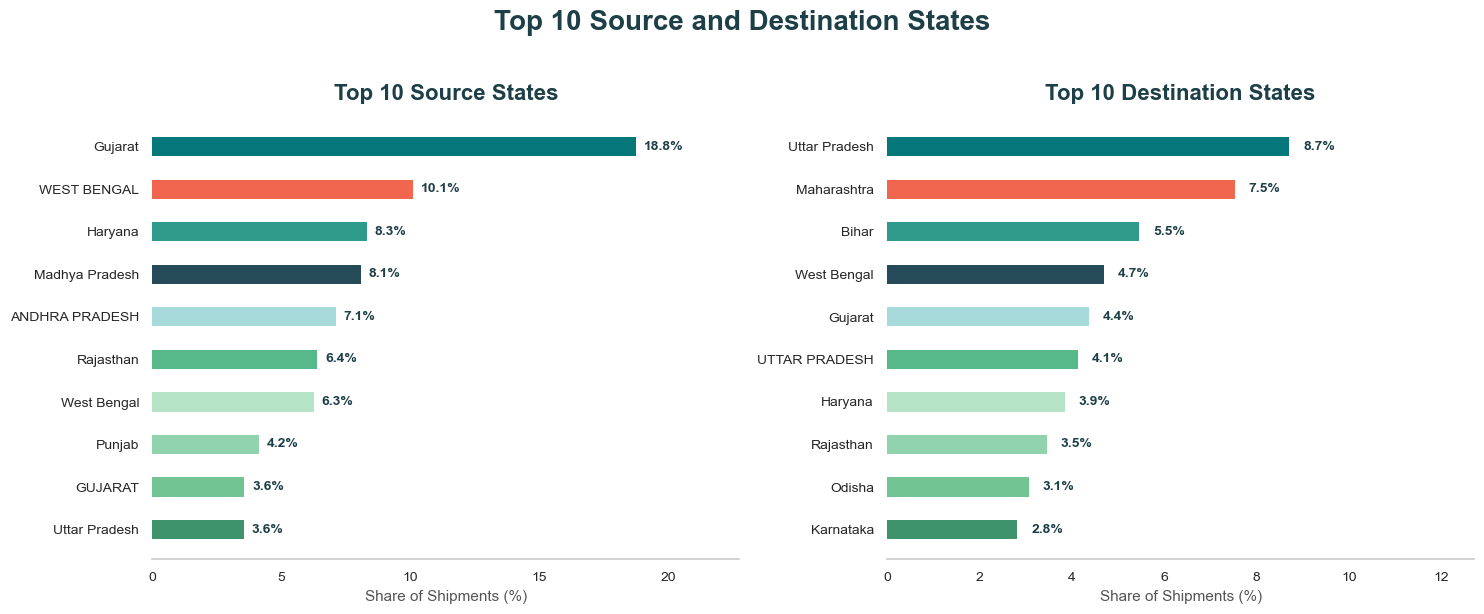

In [167]:
# ============================================================
# Univariate Analysis: Top 10 Source States & Destination States
# Same Color Format / PPT Style
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Select corrected columns if available
# ------------------------------------------------------------

source_col = 'Corrected_Source_State'
dest_col = 'Corrected_Destination_State'

if source_col not in df.columns:
    source_col = 'Source_State'

if dest_col not in df.columns:
    dest_col = 'Destination_State'

# ------------------------------------------------------------
# Source States Summary
# ------------------------------------------------------------

source_counts = df[source_col].value_counts(dropna=False).head(10)
source_pct = df[source_col].value_counts(normalize=True, dropna=False).head(10) * 100

source_df = pd.DataFrame({
    'State': source_counts.index,
    'Count': source_counts.values,
    'Percentage (%)': source_pct.values.round(2)
})

source_df['State'] = source_df['State'].apply(
    lambda x: 'Missing' if pd.isna(x) else x
)

print("=" * 60)
print("TOP 10 SOURCE STATES")
print("=" * 60)
print(source_df.to_string(index=False))
print("\n")

# ------------------------------------------------------------
# Destination States Summary
# ------------------------------------------------------------

dest_counts = df[dest_col].value_counts(dropna=False).head(10)
dest_pct = df[dest_col].value_counts(normalize=True, dropna=False).head(10) * 100

dest_df = pd.DataFrame({
    'State': dest_counts.index,
    'Count': dest_counts.values,
    'Percentage (%)': dest_pct.values.round(2)
})

dest_df['State'] = dest_df['State'].apply(
    lambda x: 'Missing' if pd.isna(x) else x
)

print("=" * 60)
print("TOP 10 DESTINATION STATES")
print("=" * 60)
print(dest_df.to_string(index=False))
print("\n")

# ------------------------------------------------------------
# Color palette used in your previous graphs
# ------------------------------------------------------------

colors = [
    "#05777B",  # deep teal
    "#F1664E",  # coral highlight
    "#2D9A8A",  # teal green
    "#244B57",  # dark blue-green
    "#A6DADB",  # light aqua
    "#57B889",  # medium green
    "#B5E3C5",  # pale green
    "#91D3AE",  # soft green
    "#72C493",  # fresh green
    "#3F936C"   # dark green
]

text_color = "#1D3F47"

# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=False)

# ============================================================
# Source States Bar Chart
# ============================================================

bars1 = axes[0].barh(
    source_df['State'],
    source_df['Percentage (%)'],
    color=colors[:len(source_df)],
    edgecolor="none",
    height=0.45
)

axes[0].invert_yaxis()

for bar, pct in zip(bars1, source_df['Percentage (%)']):
    axes[0].text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.1f}%",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold",
        color=text_color
    )

axes[0].set_title(
    "Top 10 Source States",
    fontsize=16,
    fontweight="bold",
    color=text_color,
    pad=12
)

axes[0].set_xlabel(
    "Share of Shipments (%)",
    fontsize=11,
    color="#555555"
)

axes[0].set_ylabel("")
axes[0].set_xlim(0, source_df['Percentage (%)'].max() + 4)

# ============================================================
# Destination States Bar Chart
# ============================================================

bars2 = axes[1].barh(
    dest_df['State'],
    dest_df['Percentage (%)'],
    color=colors[:len(dest_df)],
    edgecolor="none",
    height=0.45
)

axes[1].invert_yaxis()

for bar, pct in zip(bars2, dest_df['Percentage (%)']):
    axes[1].text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.1f}%",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold",
        color=text_color
    )

axes[1].set_title(
    "Top 10 Destination States",
    fontsize=16,
    fontweight="bold",
    color=text_color,
    pad=12
)

axes[1].set_xlabel(
    "Share of Shipments (%)",
    fontsize=11,
    color="#555555"
)

axes[1].set_ylabel("")
axes[1].set_xlim(0, dest_df['Percentage (%)'].max() + 4)

# ------------------------------------------------------------
# Common Styling
# ------------------------------------------------------------

for ax in axes:
    ax.tick_params(axis='x', labelsize=10)
    ax.tick_params(axis='y', labelsize=10)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.spines["bottom"].set_linewidth(1.2)
    ax.grid(False)

fig.suptitle(
    "Top 10 Source and Destination States",
    fontsize=20,
    fontweight="bold",
    color=text_color,
    y=1.02
)

plt.tight_layout()
plt.show()

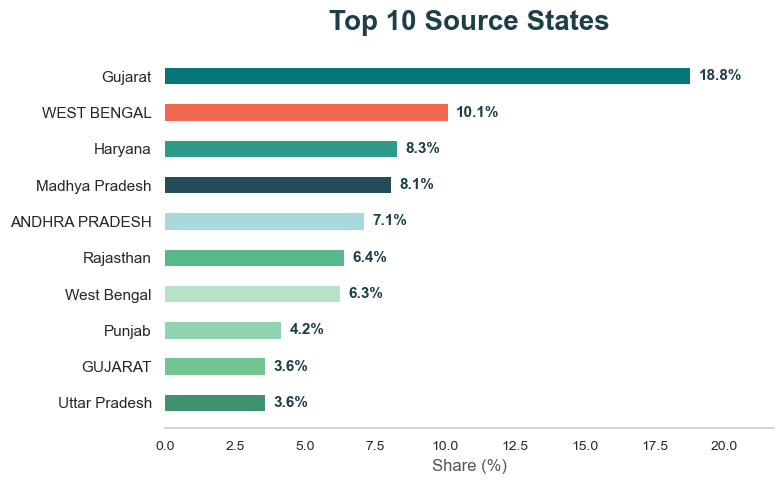

In [130]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# TOP 10 SOURCE STATES
# ============================================================

source_col = 'Source_State'

# Calculate counts and percentages
src_counts = df[source_col].value_counts().head(10)
src_pct = df[source_col].value_counts(normalize=True).head(10) * 100

src_df = pd.DataFrame({
    'State': src_counts.index,
    'Count': src_counts.values,
    'Percentage (%)': src_pct.values.round(2)
})

# Green / teal color palette based on your reference graph
colors = [
    "#05777B",  # deep teal
    "#F1664E",  # coral highlight
    "#2D9A8A",  # teal green
    "#244B57",  # dark blue-green
    "#A6DADB",  # light aqua
    "#57B889",  # medium green
    "#B5E3C5",  # pale green
    "#91D3AE",  # soft green
    "#72C493",  # fresh green
    "#3F936C"   # dark green
]

text_color = "#1D3F47"

# Create figure
plt.figure(figsize=(8, 5))

# Horizontal bar chart
bars = plt.barh(
    src_df['State'],
    src_df['Percentage (%)'],
    color=colors[:len(src_df)],
    edgecolor="none",
    height=0.45
)

# Largest on top
plt.gca().invert_yaxis()

# Add percentage labels
for bar, pct in zip(bars, src_df['Percentage (%)']):
    plt.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.1f}%",
        va="center",
        ha="left",
        fontsize=11,
        fontweight="bold",
        color=text_color
    )

# Title and labels
plt.title(
    "Top 10 Source States",
    fontsize=20,
    fontweight="bold",
    color=text_color,
    pad=15
)

plt.xlabel(
    "Share (%)",
    fontsize=12,
    color="#555555"
)

plt.ylabel("")

# Axis formatting
plt.xticks(fontsize=10)
plt.yticks(fontsize=11)

# Space for percentage labels
plt.xlim(0, max(src_df['Percentage (%)']) + 3)

# Remove unnecessary spines
for spine in ["top", "right", "left"]:
    plt.gca().spines[spine].set_visible(False)

plt.gca().spines["bottom"].set_linewidth(1.2)

plt.grid(False)
plt.tight_layout()
plt.show()

In [131]:
# ---- Destination States ----
dst_counts = df[dest_col].value_counts().head(10)
dst_pct = df[dest_col].value_counts(normalize=True).head(10) * 100

dst_df = pd.DataFrame({
    'State': dst_counts.index,
    'Count': dst_counts.values,
    'Percentage (%)': dst_pct.values.round(2)
})

print("=" * 60)
print("TOP 10 DESTINATION STATES")
print("=" * 60)
print(dst_df.to_string(index=False))

TOP 10 DESTINATION STATES
        State  Count  Percentage (%)
Uttar Pradesh  36825            8.70
  Maharashtra  31850            7.52
        Bihar  23108            5.46
  West Bengal  19900            4.70
      Gujarat  18487            4.37
UTTAR PRADESH  17477            4.13
      Haryana  16295            3.85
    Rajasthan  14612            3.45
       Odisha  12974            3.06
    Karnataka  11928            2.82


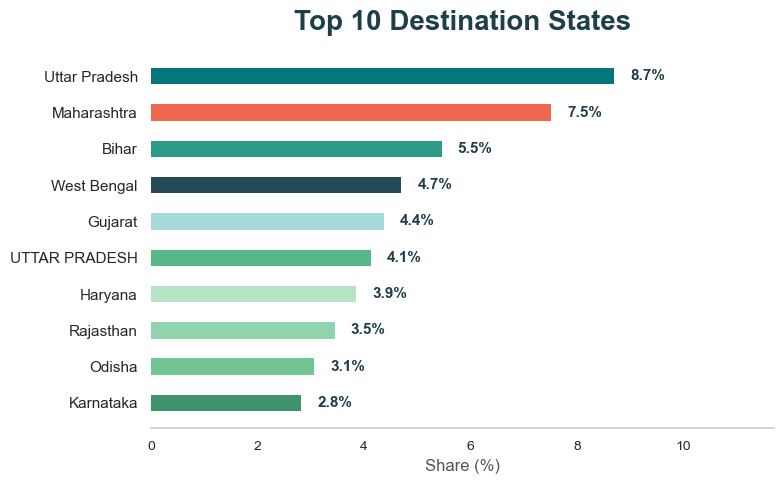

In [132]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# TOP 10 DESTINATION STATES
# ============================================================

dest_col = 'Destination_State'

# Calculate counts and percentages
dst_counts = df[dest_col].value_counts().head(10)
dst_pct = df[dest_col].value_counts(normalize=True).head(10) * 100

dst_df = pd.DataFrame({
    'State': dst_counts.index,
    'Count': dst_counts.values,
    'Percentage (%)': dst_pct.values.round(2)
})

# Green / teal color palette
colors = [
    "#05777B",  # deep teal
    "#F1664E",  # coral highlight
    "#2D9A8A",  # teal green
    "#244B57",  # dark blue-green
    "#A6DADB",  # light aqua
    "#57B889",  # medium green
    "#B5E3C5",  # pale green
    "#91D3AE",  # soft green
    "#72C493",  # fresh green
    "#3F936C"   # dark green
]

text_color = "#1D3F47"

# Create figure
plt.figure(figsize=(8, 5))

# Horizontal bar chart
bars = plt.barh(
    dst_df['State'],
    dst_df['Percentage (%)'],
    color=colors[:len(dst_df)],
    edgecolor="none",
    height=0.45
)

# Largest on top
plt.gca().invert_yaxis()

# Add percentage labels
for bar, pct in zip(bars, dst_df['Percentage (%)']):
    plt.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.1f}%",
        va="center",
        ha="left",
        fontsize=11,
        fontweight="bold",
        color=text_color
    )

# Title and labels
plt.title(
    "Top 10 Destination States",
    fontsize=20,
    fontweight="bold",
    color=text_color,
    pad=15
)

plt.xlabel(
    "Share (%)",
    fontsize=12,
    color="#555555"
)

plt.ylabel("")

# Axis formatting
plt.xticks(fontsize=10)
plt.yticks(fontsize=11)

# Space for percentage labels
plt.xlim(0, max(dst_df['Percentage (%)']) + 3)

# Remove unnecessary spines
for spine in ["top", "right", "left"]:
    plt.gca().spines[spine].set_visible(False)

plt.gca().spines["bottom"].set_linewidth(1.2)

plt.grid(False)
plt.tight_layout()
plt.show()

TOP 10 SOURCE STATES
         State  Count  Percentage (%)
       Gujarat  79452           18.77
   WEST BENGAL  42812           10.11
       Haryana  35194            8.31
Madhya Pradesh  34211            8.08
ANDHRA PRADESH  30106            7.11
     Rajasthan  27093            6.40
   West Bengal  26497            6.26
        Punjab  17572            4.15
       GUJARAT  15114            3.57
 Uttar Pradesh  15077            3.56


TOP 10 DESTINATION STATES
        State  Count  Percentage (%)
Uttar Pradesh  36825            8.70
  Maharashtra  31850            7.52
        Bihar  23108            5.46
  West Bengal  19900            4.70
      Gujarat  18487            4.37
UTTAR PRADESH  17477            4.13
      Haryana  16295            3.85
    Rajasthan  14612            3.45
       Odisha  12974            3.06
    Karnataka  11928            2.82




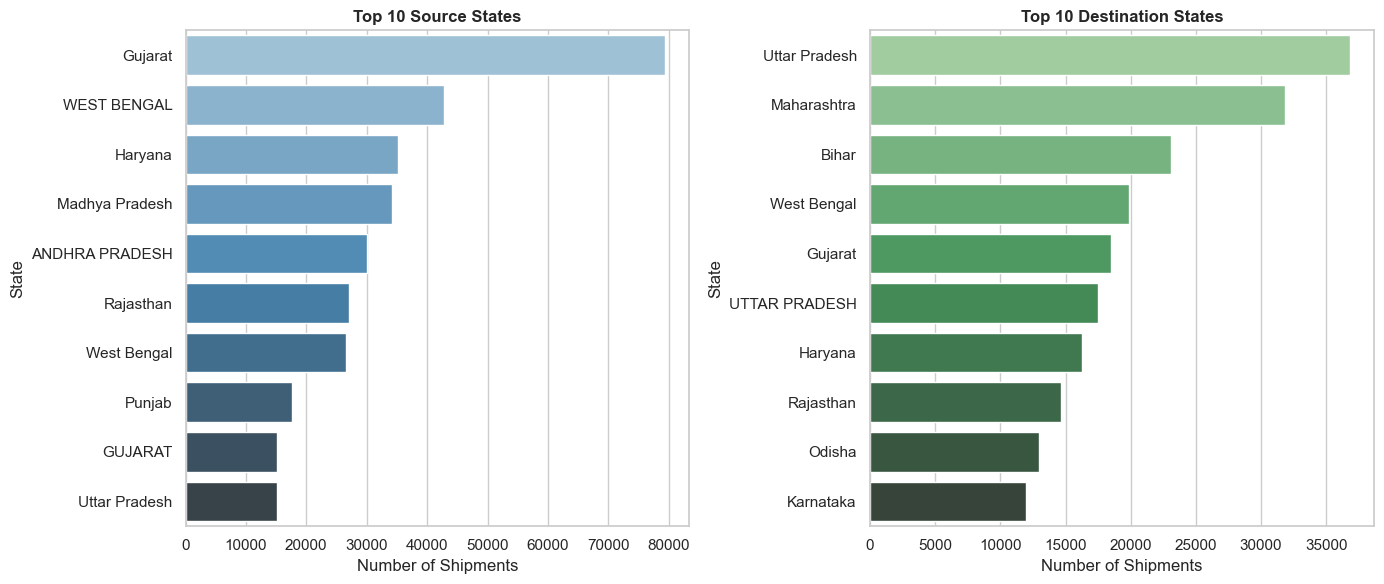

<a id="2-2-7-5-Product-Type-Distribution"></a>
##### 2.2.7.5 Product Type Distribution


In [18]:
# ============================================================
# Product Type Distribution
# ============================================================

import pandas as pd

# Assuming 'df' is your DataFrame (raw or cleaned)
# Use the 'Product' column
product_counts = df['Product'].value_counts()
product_pct = df['Product'].value_counts(normalize=True) * 100

# Create summary DataFrame
product_df = pd.DataFrame({
    'Product': product_counts.index,
    'Count': product_counts.values,
    'Percentage (%)': product_pct.values.round(2)
})

# Print table
print("=" * 60)
print("PRODUCT TYPE DISTRIBUTION")
print("=" * 60)
print(product_df.to_string(index=False))

PRODUCT TYPE DISTRIBUTION
          Product  Count  Percentage (%)
       Edible Oil 296156           69.96
             Food  71573           16.91
            Flour  27956            6.60
          Nuggets  11294            2.67
             ATTA   5380            1.27
            Besan   5380            1.27
             Oleo   2892            0.68
Food and Non Food    557            0.13
             Rice    516            0.12
              DOC    499            0.12
             Soap    255            0.06
         Non Food    239            0.06
            Sugar    206            0.05
           Pulses    182            0.04
           Others    126            0.03
            Wheat     54            0.01
             Soya     40            0.01
 Soya Derivatives      5            0.00
       Castor Oil      1            0.00


In [19]:
# ============================================================
# NUMERICAL SUMMARY:
# Product Type Distribution + Average Cost by Product
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# Prepare data
# ------------------------------------------------------------

product_col = 'Product'
cost_col = 'Cost'

df_num = df[[product_col, cost_col]].copy()

# Convert Cost to numeric
df_num[cost_col] = pd.to_numeric(df_num[cost_col], errors='coerce')

# Convert missing Product values to readable label
df_num[product_col] = df_num[product_col].apply(
    lambda x: 'Missing' if pd.isna(x) else x
)

# Drop rows where Cost is missing
df_num = df_num.dropna(subset=[cost_col])

# ------------------------------------------------------------
# Product-wise numerical summary
# ------------------------------------------------------------

product_summary = (
    df_num
    .groupby(product_col)
    .agg(
        Count=(cost_col, 'count'),
        Average_Cost=(cost_col, 'mean'),
        Median_Cost=(cost_col, 'median'),
        Minimum_Cost=(cost_col, 'min'),
        Maximum_Cost=(cost_col, 'max'),
        Std_Dev_Cost=(cost_col, 'std')
    )
    .reset_index()
)

# Add percentage share
total_records = product_summary['Count'].sum()

product_summary['Percentage (%)'] = (
    product_summary['Count'] / total_records * 100
).round(2)

# Round cost columns
cost_columns = [
    'Average_Cost',
    'Median_Cost',
    'Minimum_Cost',
    'Maximum_Cost',
    'Std_Dev_Cost'
]

product_summary[cost_columns] = product_summary[cost_columns].round(2)

# Sort by product share
product_summary = product_summary.sort_values(
    'Percentage (%)',
    ascending=False
)

# Rename columns for clean output
product_summary = product_summary.rename(columns={
    product_col: 'Product',
    'Average_Cost': 'Average Cost (Rs.)',
    'Median_Cost': 'Median Cost (Rs.)',
    'Minimum_Cost': 'Minimum Cost (Rs.)',
    'Maximum_Cost': 'Maximum Cost (Rs.)',
    'Std_Dev_Cost': 'Std. Dev. Cost (Rs.)'
})

# ------------------------------------------------------------
# Print full summary table
# ------------------------------------------------------------

print("=" * 130)
print("PRODUCT TYPE DISTRIBUTION + COST SUMMARY")
print("=" * 130)
print(product_summary.to_string(index=False))
print("=" * 130)
print(f"Total Valid Records: {total_records:,}")

PRODUCT TYPE DISTRIBUTION + COST SUMMARY
          Product  Count  Average Cost (Rs.)  Median Cost (Rs.)  Minimum Cost (Rs.)  Maximum Cost (Rs.)  Std. Dev. Cost (Rs.)  Percentage (%)
       Edible Oil 296156             5123.97             2810.0                15.0            350010.0              12742.44           69.96
             Food  71573             3822.47             2250.0                60.0            165010.0               8506.72           16.91
            Flour  27956             2065.18             1654.5                70.0            164960.0               3912.86            6.60
          Nuggets  11294            47818.38            42910.0               340.0           1009910.0              28868.73            2.67
            Besan   5380            11403.61             2876.5               190.0            137010.0              24821.67            1.27
             ATTA   5380             2089.71             1823.0               110.0            115009.0    

In [21]:
# ============================================================
# PPT NUMERICAL SUMMARY:
# Product Share + Average / Median Cost
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# Prepare data
# ------------------------------------------------------------

product_col = 'Product'
cost_col = 'Cost'

# Create working copy
df_product = df[[product_col, cost_col]].copy()

# Convert Cost to numeric
df_product[cost_col] = pd.to_numeric(df_product[cost_col], errors='coerce')

# Convert missing product values to readable label
df_product[product_col] = df_product[product_col].apply(
    lambda x: 'Missing' if pd.isna(x) else x
)

# Drop rows where Cost is missing
df_product = df_product.dropna(subset=[cost_col])

# ------------------------------------------------------------
# Create product summary
# ------------------------------------------------------------

product_summary = (
    df_product
    .groupby(product_col)
    .agg(
        Count=(cost_col, 'count'),
        Average_Cost=(cost_col, 'mean'),
        Median_Cost=(cost_col, 'median')
    )
    .reset_index()
)

# Calculate percentage share
total_records = product_summary['Count'].sum()

product_summary['Percentage (%)'] = (
    product_summary['Count'] / total_records * 100
).round(2)

# Round cost values
product_summary['Average_Cost'] = product_summary['Average_Cost'].round(2)
product_summary['Median_Cost'] = product_summary['Median_Cost'].round(2)

# Sort by product share
product_summary = product_summary.sort_values(
    'Percentage (%)',
    ascending=False
)

# Rename columns for PPT-friendly output
product_summary = product_summary.rename(columns={
    product_col: 'Product',
    'Average_Cost': 'Average Cost (Rs.)',
    'Median_Cost': 'Median Cost (Rs.)'
})

# Reorder columns
product_summary = product_summary[
    [
        'Product',
        'Count',
        'Percentage (%)',
        'Average Cost (Rs.)',
        'Median Cost (Rs.)'
    ]
]

# ------------------------------------------------------------
# Print PPT-friendly table
# ------------------------------------------------------------

print("=" * 95)
print("PRODUCT SHARE AND COST SUMMARY")
print("=" * 95)
print(product_summary.to_string(index=False))
print("=" * 95)
print(f"Total Valid Records: {total_records:,}")

PRODUCT SHARE AND COST SUMMARY
          Product  Count  Percentage (%)  Average Cost (Rs.)  Median Cost (Rs.)
       Edible Oil 296156           69.96             5123.97             2810.0
             Food  71573           16.91             3822.47             2250.0
            Flour  27956            6.60             2065.18             1654.5
          Nuggets  11294            2.67            47818.38            42910.0
            Besan   5380            1.27            11403.61             2876.5
             ATTA   5380            1.27             2089.71             1823.0
             Oleo   2892            0.68             7445.47             4650.0
Food and Non Food    557            0.13             9929.92             1754.0
              DOC    499            0.12             6140.99             2850.0
             Rice    516            0.12             2943.69             3000.0
         Non Food    239            0.06            24473.54             6300.0
         

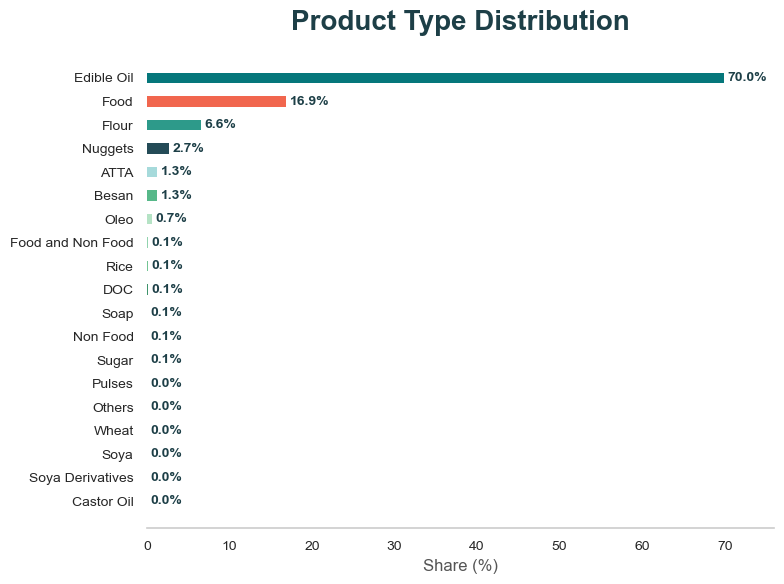

In [135]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# PRODUCT TYPE DISTRIBUTION
# ============================================================

product_col = 'Product'

# Calculate counts and percentages
product_counts = df[product_col].value_counts(dropna=False)
product_pct = df[product_col].value_counts(normalize=True, dropna=False) * 100

product_df = pd.DataFrame({
    'Product': product_counts.index,
    'Count': product_counts.values,
    'Percentage (%)': product_pct.values.round(2)
})

# Convert missing values to readable label
product_df['Product'] = product_df['Product'].apply(
    lambda x: 'Missing' if pd.isna(x) else x
)

# Green / teal color palette
colors = [
    "#05777B",  # deep teal
    "#F1664E",  # coral highlight
    "#2D9A8A",  # teal green
    "#244B57",  # dark blue-green
    "#A6DADB",  # light aqua
    "#57B889",  # medium green
    "#B5E3C5",  # pale green
    "#91D3AE",  # soft green
    "#72C493",  # fresh green
    "#3F936C",  # dark green
    "#8DD3C7",
    "#66A182",
    "#B7E4C7",
    "#40916C",
    "#95D5B2",
    "#52B788",
    "#74C69D",
    "#1B4332",
    "#D8F3DC"
]

text_color = "#1D3F47"

# Create figure
plt.figure(figsize=(8, 6))

# Horizontal bar chart
bars = plt.barh(
    product_df['Product'],
    product_df['Percentage (%)'],
    color=colors[:len(product_df)],
    edgecolor="none",
    height=0.45
)

# Largest on top
plt.gca().invert_yaxis()

# Add percentage labels
for bar, pct in zip(bars, product_df['Percentage (%)']):
    plt.text(
        bar.get_width() + 0.4,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.1f}%",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold",
        color=text_color
    )

# Title and labels
plt.title(
    "Product Type Distribution",
    fontsize=20,
    fontweight="bold",
    color=text_color,
    pad=15
)

plt.xlabel(
    "Share (%)",
    fontsize=12,
    color="#555555"
)

plt.ylabel("")

# Axis formatting
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

# Space for percentage labels
plt.xlim(0, max(product_df['Percentage (%)']) + 6)

# Remove unnecessary spines
for spine in ["top", "right", "left"]:
    plt.gca().spines[spine].set_visible(False)

plt.gca().spines["bottom"].set_linewidth(1.2)

plt.grid(False)
plt.tight_layout()
plt.show()

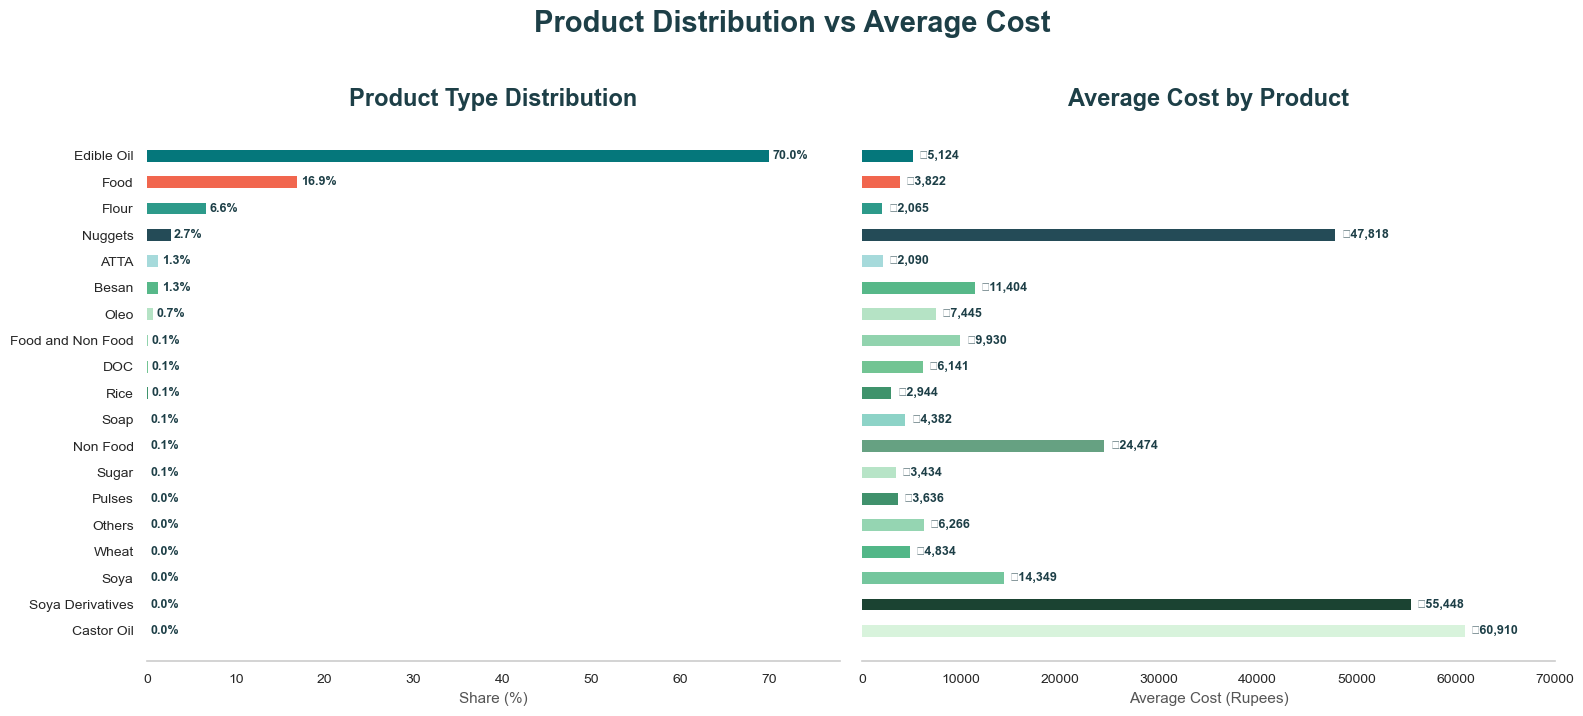

In [16]:
# ============================================================
# COMBINED GRAPH:
# Product Type Distribution + Average Cost by Product
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Prepare data
# ------------------------------------------------------------

product_col = 'Product'
cost_col = 'Cost'

# Make a working copy
df_plot = df[[product_col, cost_col]].copy()

# Convert Cost to numeric
df_plot[cost_col] = pd.to_numeric(df_plot[cost_col], errors='coerce')

# Convert missing Product values to readable label
df_plot[product_col] = df_plot[product_col].apply(
    lambda x: 'Missing' if pd.isna(x) else x
)

# Drop rows where cost is missing
df_plot = df_plot.dropna(subset=[cost_col])

# ------------------------------------------------------------
# 1. Product Type Distribution
# ------------------------------------------------------------

product_counts = df_plot[product_col].value_counts(dropna=False)
product_pct = df_plot[product_col].value_counts(normalize=True, dropna=False) * 100

product_df = pd.DataFrame({
    'Product': product_counts.index,
    'Count': product_counts.values,
    'Percentage (%)': product_pct.values.round(2)
})

# ------------------------------------------------------------
# 2. Average Cost by Product
# ------------------------------------------------------------

prod_cost = (
    df_plot
    .groupby(product_col, as_index=False)[cost_col]
    .mean()
    .rename(columns={cost_col: 'Average Cost'})
)

# Merge distribution and average cost
combined_df = product_df.merge(
    prod_cost,
    on='Product',
    how='left'
)

# Sort by product share
combined_df = combined_df.sort_values('Percentage (%)', ascending=False)

# ------------------------------------------------------------
# Colors
# ------------------------------------------------------------

colors = [
    "#05777B",
    "#F1664E",
    "#2D9A8A",
    "#244B57",
    "#A6DADB",
    "#57B889",
    "#B5E3C5",
    "#91D3AE",
    "#72C493",
    "#3F936C",
    "#8DD3C7",
    "#66A182",
    "#B7E4C7",
    "#40916C",
    "#95D5B2",
    "#52B788",
    "#74C69D",
    "#1B4332",
    "#D8F3DC"
]

text_color = "#1D3F47"

# ------------------------------------------------------------
# Combined Plot
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(16, 7),
    sharey=True
)

# ------------------------------------------------------------
# Left: Product Type Distribution
# ------------------------------------------------------------

bars1 = axes[0].barh(
    combined_df['Product'],
    combined_df['Percentage (%)'],
    color=colors[:len(combined_df)],
    edgecolor="none",
    height=0.45
)

axes[0].invert_yaxis()

for bar, pct in zip(bars1, combined_df['Percentage (%)']):
    axes[0].text(
        bar.get_width() + 0.4,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.1f}%",
        va="center",
        ha="left",
        fontsize=9,
        fontweight="bold",
        color=text_color
    )

axes[0].set_title(
    "Product Type Distribution",
    fontsize=17,
    fontweight="bold",
    color=text_color,
    pad=14
)

axes[0].set_xlabel(
    "Share (%)",
    fontsize=11,
    color="#555555"
)

axes[0].set_ylabel("")
axes[0].set_xlim(0, combined_df['Percentage (%)'].max() + 8)

# ------------------------------------------------------------
# Right: Average Cost by Product
# ------------------------------------------------------------

bars2 = axes[1].barh(
    combined_df['Product'],
    combined_df['Average Cost'],
    color=colors[:len(combined_df)],
    edgecolor="none",
    height=0.45
)

for bar, val in zip(bars2, combined_df['Average Cost']):
    axes[1].text(
        bar.get_width() + combined_df['Average Cost'].max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"₹{val:,.0f}",
        va="center",
        ha="left",
        fontsize=9,
        fontweight="bold",
        color=text_color
    )

axes[1].set_title(
    "Average Cost by Product",
    fontsize=17,
    fontweight="bold",
    color=text_color,
    pad=14
)

axes[1].set_xlabel(
    "Average Cost (Rupees)",
    fontsize=11,
    color="#555555"
)

axes[1].set_ylabel("")
axes[1].set_xlim(0, combined_df['Average Cost'].max() * 1.15)

# ------------------------------------------------------------
# Styling
# ------------------------------------------------------------

for ax in axes:
    ax.tick_params(axis='x', labelsize=10)
    ax.tick_params(axis='y', labelsize=10)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.spines["bottom"].set_linewidth(1.2)
    ax.grid(False)

fig.suptitle(
    "Product Distribution vs Average Cost",
    fontsize=21,
    fontweight="bold",
    color=text_color,
    y=1.02
)

plt.tight_layout()
plt.show()

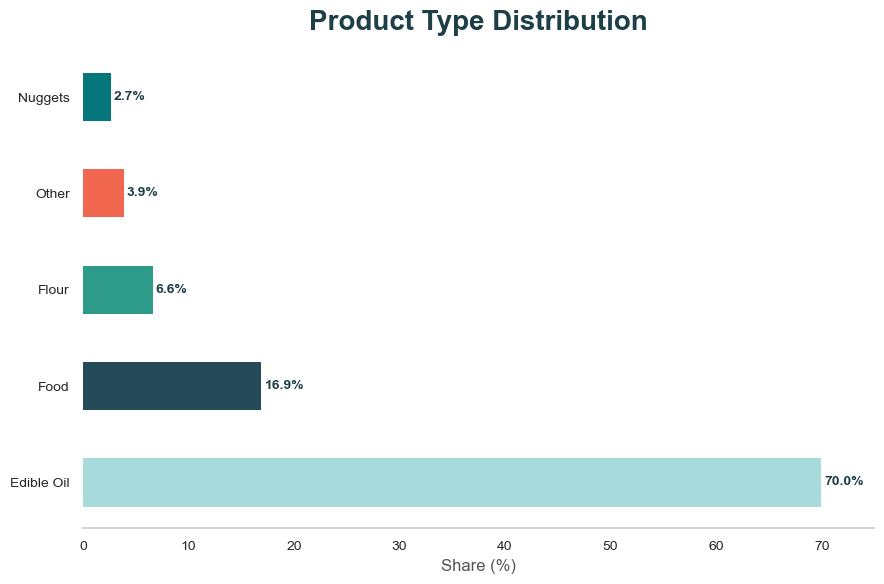

In [136]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# PRODUCT TYPE DISTRIBUTION – WITH 'OTHER' GROUP FOR SMALL SLICES
# ============================================================

product_col = 'Product'

# Set a threshold: categories below this % will be grouped into 'Other'
THRESHOLD = 2.0  # percent

# Calculate counts and percentages
product_counts = df[product_col].value_counts(dropna=False)
product_pct = df[product_col].value_counts(normalize=True, dropna=False) * 100

# Create a DataFrame
product_df = pd.DataFrame({
    'Product': product_counts.index,
    'Count': product_counts.values,
    'Percentage (%)': product_pct.values
})

# Replace NaN with 'Missing'
product_df['Product'] = product_df['Product'].apply(
    lambda x: 'Missing' if pd.isna(x) else x
)

# --- Group small categories into 'Other' ---
# Identify categories below threshold (excluding any existing 'Other' if present)
small_mask = (product_df['Percentage (%)'] < THRESHOLD) & (product_df['Product'] != 'Other')
small_cats = product_df[small_mask]

if not small_cats.empty:
    other_count = small_cats['Count'].sum()
    other_pct = small_cats['Percentage (%)'].sum()

    # Keep only categories above threshold, plus 'Other'
    product_df = product_df[~small_mask].copy()
    other_row = pd.DataFrame({
        'Product': ['Other'],
        'Count': [other_count],
        'Percentage (%)': [other_pct]
    })
    product_df = pd.concat([product_df, other_row], ignore_index=True)

# Sort descending by percentage (largest on top for horizontal bar chart)
product_df = product_df.sort_values('Percentage (%)', ascending=True).reset_index(drop=True)

# Colors (teal/green palette, extended if needed)
base_colors = [
    "#05777B", "#F1664E", "#2D9A8A", "#244B57", "#A6DADB",
    "#57B889", "#B5E3C5", "#91D3AE", "#72C493", "#3F936C",
    "#8DD3C7", "#66A182", "#B7E4C7", "#40916C", "#95D5B2",
    "#52B788", "#74C69D", "#1B4332", "#D8F3DC"
]
# Assign colors – recycle if more categories than colors
colors = base_colors[:len(product_df)] + base_colors * (len(product_df) // len(base_colors) + 1)

text_color = "#1D3F47"

# Create figure
fig, ax = plt.subplots(figsize=(9, 6))

# Horizontal bar chart
bars = ax.barh(
    product_df['Product'],
    product_df['Percentage (%)'],
    color=colors[:len(product_df)],
    edgecolor="none",
    height=0.5
)

# Largest on top
ax.invert_yaxis()

# Add percentage labels
for bar, pct in zip(bars, product_df['Percentage (%)']):
    x_pos = bar.get_width() + 0.3
    # For very small bars, place label to the right (already outside)
    ax.text(
        x_pos,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.1f}%",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold",
        color=text_color
    )

# Title and labels
ax.set_title(
    "Product Type Distribution",
    fontsize=20,
    fontweight="bold",
    color=text_color,
    pad=15
)
ax.set_xlabel("Share (%)", fontsize=12, color="#555555")
ax.set_ylabel("")

# Axis formatting
ax.tick_params(axis='x', labelsize=10)
ax.tick_params(axis='y', labelsize=10)

# Extend x-axis slightly for labels
ax.set_xlim(0, max(product_df['Percentage (%)']) + 5)

# Clean spines
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_linewidth(1.2)
ax.grid(False)

plt.tight_layout()
plt.show()

PRODUCT TYPE DISTRIBUTION
          Product  Count  Percentage (%)
       Edible Oil 296156           69.96
             Food  71573           16.91
            Flour  27956            6.60
          Nuggets  11294            2.67
             ATTA   5380            1.27
            Besan   5380            1.27
             Oleo   2892            0.68
Food and Non Food    557            0.13
             Rice    516            0.12
              DOC    499            0.12
             Soap    255            0.06
         Non Food    239            0.06
            Sugar    206            0.05
           Pulses    182            0.04
           Others    126            0.03
            Wheat     54            0.01
             Soya     40            0.01
 Soya Derivatives      5            0.00
       Castor Oil      1            0.00




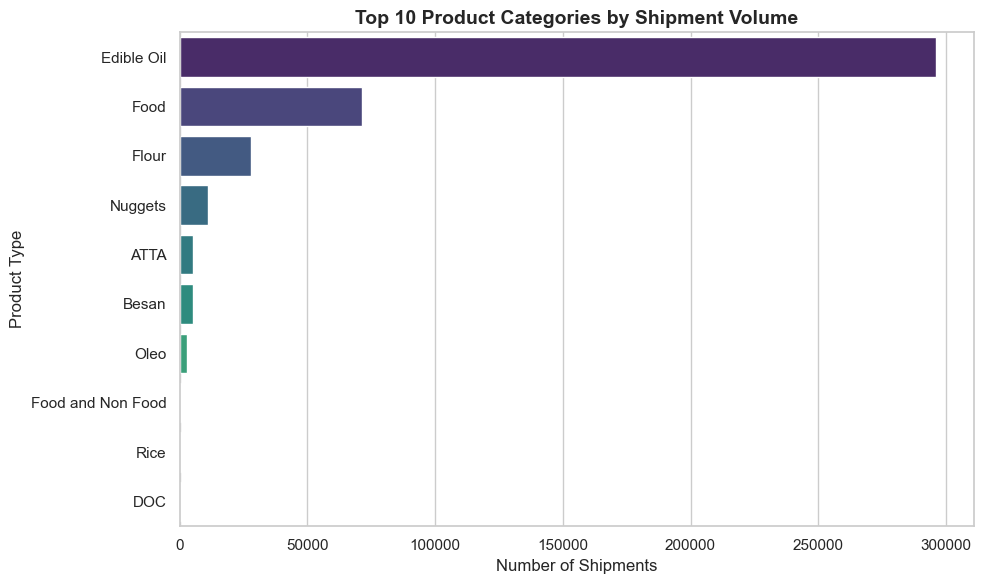

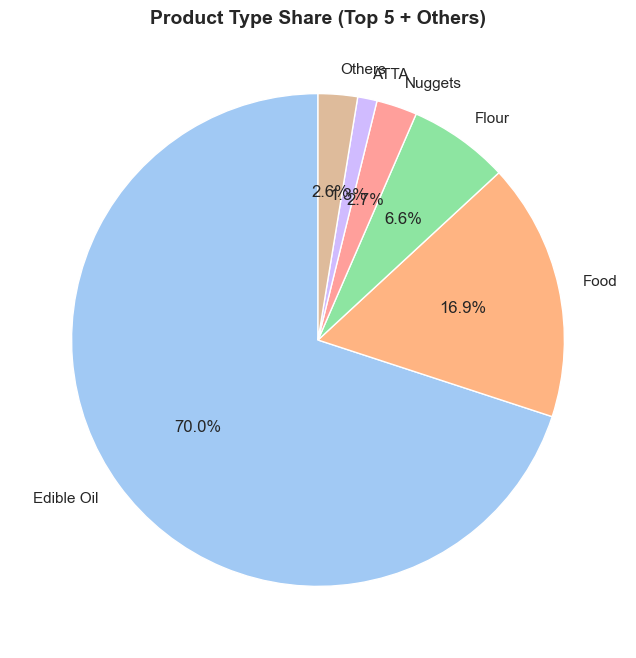

In [57]:
# ============================================================
# Univariate Analysis: Product Type Distribution
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'df' is your DataFrame (raw or cleaned)
# Use the 'Product' column (available in both raw and cleaned data)
product_counts = df['Product'].value_counts()
product_pct = df['Product'].value_counts(normalize=True) * 100

# Create summary DataFrame
product_df = pd.DataFrame({
    'Product': product_counts.index,
    'Count': product_counts.values,
    'Percentage (%)': product_pct.values.round(2)
})

print("=" * 60)
print("PRODUCT TYPE DISTRIBUTION")
print("=" * 60)
print(product_df.to_string(index=False))
print("\n")

# Optional: Bar chart for top 10 products
top_products = product_df.head(10)
plt.figure(figsize=(10,6))
sns.barplot(data=top_products, x='Count', y='Product', palette='viridis')
plt.title('Top 10 Product Categories by Shipment Volume', fontsize=14, fontweight='bold')
plt.xlabel('Number of Shipments')
plt.ylabel('Product Type')
plt.tight_layout()
plt.show()

# Optional: Pie chart for top 5 products + 'Others'
top5 = product_df.head(5)
others_count = product_df.iloc[5:]['Count'].sum()
others_pct = product_df.iloc[5:]['Percentage (%)'].sum()

pie_data = pd.concat([top5, pd.DataFrame({'Product': ['Others'], 'Count': [others_count], 'Percentage (%)': [others_pct]})])

plt.figure(figsize=(8,8))
plt.pie(pie_data['Percentage (%)'], labels=pie_data['Product'], autopct='%1.1f%%',
        startangle=90, colors=sns.color_palette('pastel'))
plt.title('Product Type Share (Top 5 + Others)', fontsize=14, fontweight='bold')
plt.show()

<a id="2-2-7-6-Cost-Distribution"></a>
##### 2.2.7.6 Cost Distribution


In [140]:
# ==============================================================================
# Numeric Summary: Cost Distribution
# ==============================================================================

import pandas as pd
import numpy as np

# Cost column
cost = df['Cost']

# Compute statistics
min_cost = cost.min()
q1 = cost.quantile(0.25)
median_cost = cost.median()
mean_cost = cost.mean()
q3 = cost.quantile(0.75)
max_cost = cost.max()
std_cost = cost.std()
skew_cost = cost.skew()
kurt_cost = cost.kurtosis()

print("=" * 65)
print("COST DISTRIBUTION STATISTICS")
print("=" * 65)
print(f"Minimum Cost:         Rs.{min_cost:>15,.2f}")
print(f"25th Percentile:      Rs.{q1:>15,.2f}")
print(f"Median Cost:          Rs.{median_cost:>15,.2f}")
print(f"Mean Cost:            Rs.{mean_cost:>15,.2f}")
print(f"75th Percentile:      Rs.{q3:>15,.2f}")
print(f"Maximum Cost:         Rs.{max_cost:>15,.2f}")
print("-" * 65)
print(f"Standard Deviation:   Rs.{std_cost:>15,.2f}")
print(f"Skewness:             {skew_cost:>18,.2f}")
print(f"Kurtosis:             {kurt_cost:>18,.2f}")
print("=" * 65)

COST DISTRIBUTION STATISTICS
Minimum Cost:         Rs.          15.00
25th Percentile:      Rs.       1,740.00
Median Cost:          Rs.       2,710.00
Mean Cost:            Rs.       5,913.89
75th Percentile:      Rs.       3,700.00
Maximum Cost:         Rs.   1,009,910.00
-----------------------------------------------------------------
Standard Deviation:   Rs.      14,475.48
Skewness:                           6.09
Kurtosis:                          88.82


COST DISTRIBUTION STATISTICS
count     423311.00
mean        5913.89
std        14475.48
min           15.00
25%         1740.00
50%         2710.00
75%         3700.00
max      1009910.00
Name: Cost, dtype: float64




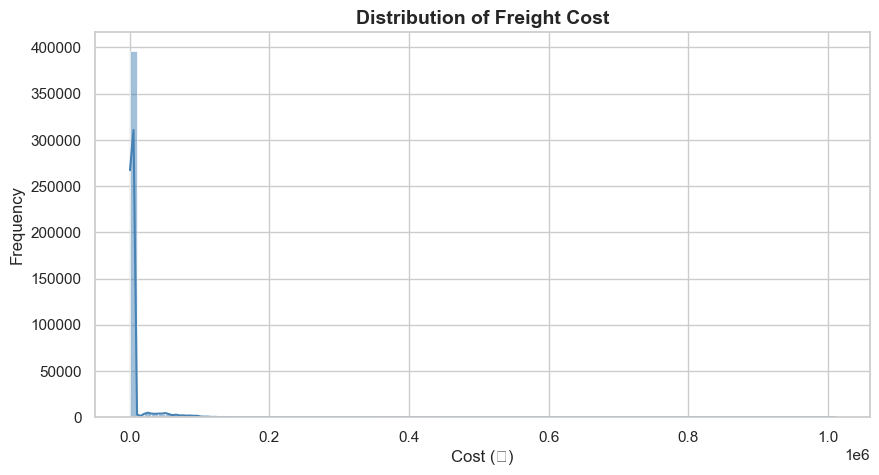

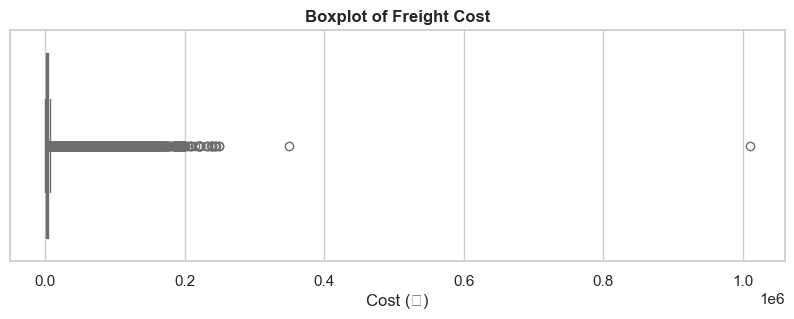

In [141]:
# ============================================================
# Univariate Analysis: Cost Distribution
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'df' is your DataFrame
cost_stats = df['Cost'].describe()
print("=" * 50)
print("COST DISTRIBUTION STATISTICS")
print("=" * 50)
print(cost_stats.round(2))
print("\n")

# Histogram
plt.figure(figsize=(10,5))
sns.histplot(df['Cost'], bins=100, kde=True, color='steelblue')
plt.title('Distribution of Freight Cost', fontsize=14, fontweight='bold')
plt.xlabel('Cost (₹)')
plt.ylabel('Frequency')
plt.show()

# Boxplot
plt.figure(figsize=(10,3))
sns.boxplot(x=df['Cost'], color='lightcoral')
plt.title('Boxplot of Freight Cost', fontsize=12)
plt.xlabel('Cost (₹)')
plt.show()

COST DISTRIBUTION STATISTICS
Mean Cost:       ₹5,913.89
Median Cost:     ₹2,710.00
Maximum Cost:    ₹1,009,910.00
Skewness:        6.09
Kurtosis:        88.82

Interpretation:
• Right-skew: Skewness = 6.09, Kurtosis = 88.82 (heavy tails)
• Median ₹2,710 vs Mean ₹5,914 — outliers inflate mean
• Max ₹1,009,910 — extreme long-haul/heavy shipments
• Log-transformation recommended and applied in Data Prep


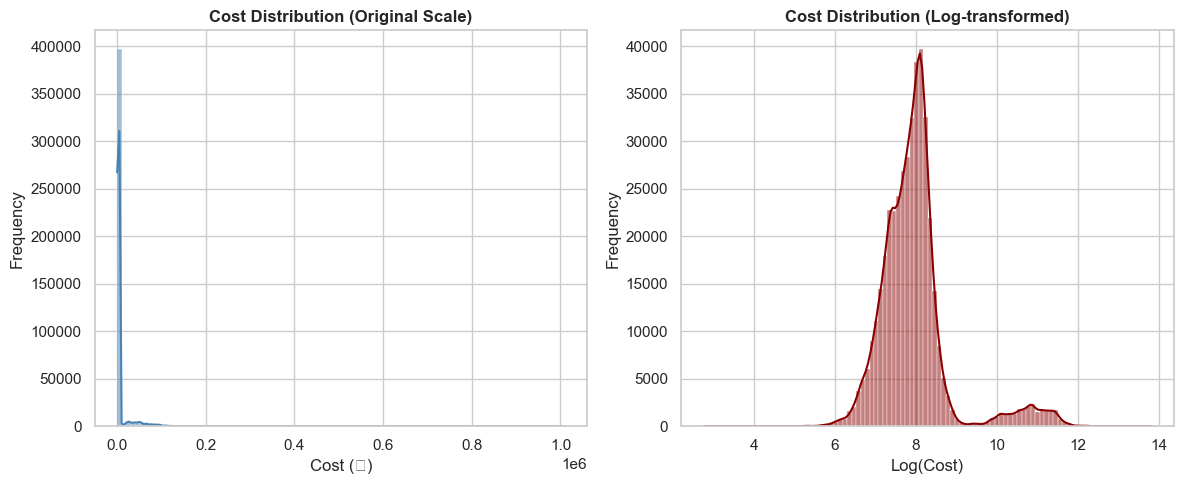

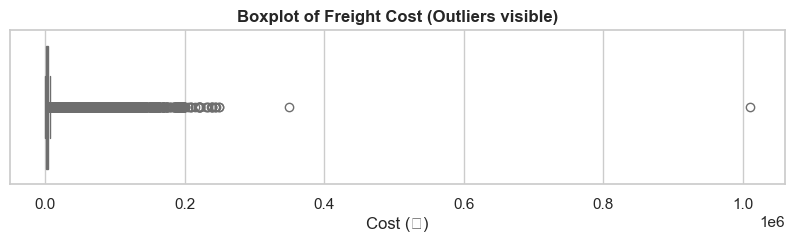

In [142]:
# ============================================================
# Cost Distribution Analysis: Frequency, Skewness, Kurtosis
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis

# Assuming 'df' is your DataFrame with 'Cost' column
cost = df['Cost'].dropna()

# Basic statistics
mean_cost = cost.mean()
median_cost = cost.median()
max_cost = cost.max()
skewness = skew(cost)
kurt = kurtosis(cost)

print("=" * 60)
print("COST DISTRIBUTION STATISTICS")
print("=" * 60)
print(f"Mean Cost:       ₹{mean_cost:,.2f}")
print(f"Median Cost:     ₹{median_cost:,.2f}")
print(f"Maximum Cost:    ₹{max_cost:,.2f}")
print(f"Skewness:        {skewness:.2f}")
print(f"Kurtosis:        {kurt:.2f}")
print("\nInterpretation:")
print(f"• Right-skew: Skewness = {skewness:.2f}, Kurtosis = {kurt:.2f} (heavy tails)")
print(f"• Median ₹{median_cost:,.0f} vs Mean ₹{mean_cost:,.0f} — outliers inflate mean")
print(f"• Max ₹{max_cost:,.0f} — extreme long-haul/heavy shipments")
print("• Log-transformation recommended and applied in Data Prep")
print("=" * 60)

# Histogram with KDE
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.histplot(cost, bins=100, kde=True, color='steelblue')
plt.title('Cost Distribution (Original Scale)', fontweight='bold')
plt.xlabel('Cost (₹)')
plt.ylabel('Frequency')

# Log-transformed histogram (to show effect)
plt.subplot(1,2,2)
log_cost = np.log1p(cost)
sns.histplot(log_cost, bins=100, kde=True, color='darkred')
plt.title('Cost Distribution (Log-transformed)', fontweight='bold')
plt.xlabel('Log(Cost)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

# Boxplot to visualize outliers
plt.figure(figsize=(10,2))
sns.boxplot(x=cost, color='lightcoral')
plt.title('Boxplot of Freight Cost (Outliers visible)', fontweight='bold')
plt.xlabel('Cost (₹)')
plt.show()

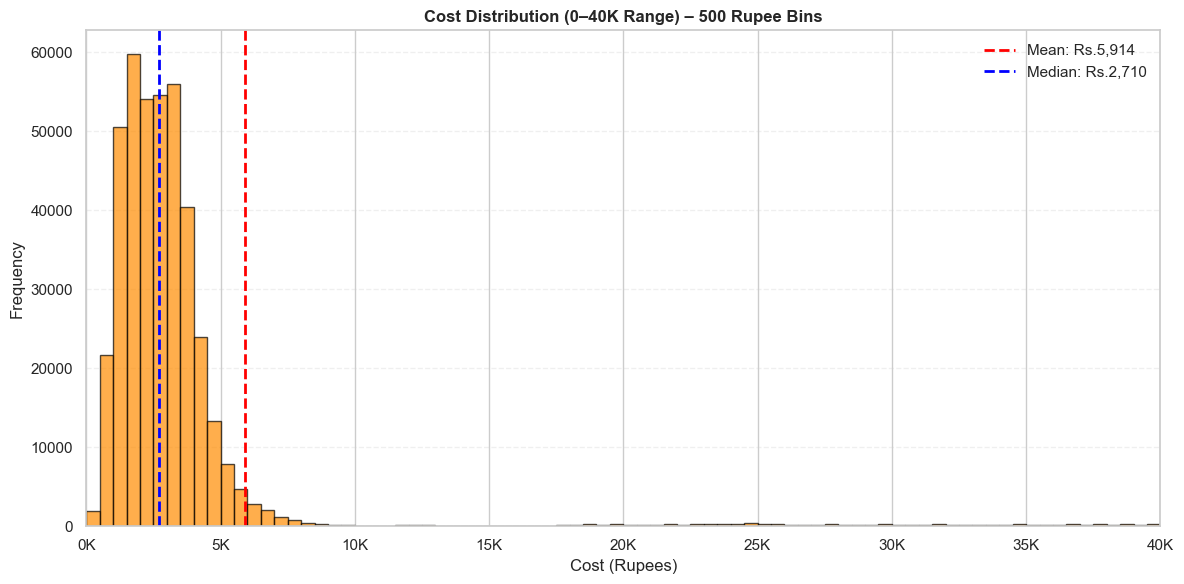

Mean Cost (0–40K range): Rs.5,913.89
Median Cost (0–40K range): Rs.2,710.00


In [143]:
# ============================================================
# Zoomed Cost Distribution (0–40K) with Mean & Median Lines
# (Using 'Rs.' instead of '₹' to avoid rendering issues)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Assuming 'df' is your DataFrame with 'Cost' column
cost = df['Cost'].dropna()

# Compute mean and median
mean_cost = cost.mean()
median_cost = cost.median()

# Create bins every 500 rupees from 0 to 40000
bins_zoom = np.arange(0, 40000 + 500, 500)

plt.figure(figsize=(12, 6))
counts, bin_edges, patches = plt.hist(cost, bins=bins_zoom, edgecolor='black', alpha=0.7, color='darkorange')

# Add vertical lines for mean and median (using 'Rs.' instead of '₹')
plt.axvline(mean_cost, color='red', linestyle='--', linewidth=2, label=f'Mean: Rs.{mean_cost:,.0f}')
plt.axvline(median_cost, color='blue', linestyle='--', linewidth=2, label=f'Median: Rs.{median_cost:,.0f}')

# Set x‑axis ticks every 5000 rupees, formatted as '5K', '10K', etc. (no currency symbol)
tick_positions = np.arange(0, 40001, 5000)
tick_labels = [f'{int(x/1000)}K' for x in tick_positions]
plt.xticks(tick_positions, tick_labels)

plt.xlim(0, 40000)
plt.title('Cost Distribution (0–40K Range) – 500 Rupee Bins', fontweight='bold')
plt.xlabel('Cost (Rupees)')
plt.ylabel('Frequency')

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Mean Cost (0–40K range): Rs.{mean_cost:,.2f}")
print(f"Median Cost (0–40K range): Rs.{median_cost:,.2f}")

<a id="2-2-7-7-Distance-Distribution"></a>
##### 2.2.7.7 Distance Distribution


In [144]:
# ============================================================
# Numeric Summary: Distance Distribution (km)
# ============================================================

import pandas as pd
import numpy as np

# Choose the distance column (use 'Corrected_Distance' if available, else 'Distance')
if 'Corrected_Distance' in df.columns:
    dist_col = 'Corrected_Distance'
else:
    dist_col = 'Distance'

distance = df[dist_col].dropna()

# Compute statistics
mean_dist = distance.mean()
median_dist = distance.median()
std_dist = distance.std()
min_dist = distance.min()
max_dist = distance.max()
q1 = distance.quantile(0.25)
q3 = distance.quantile(0.75)

print("=" * 60)
print("DISTANCE DISTRIBUTION STATISTICS (km)")
print("=" * 60)
print(f"Mean Distance:          {mean_dist:>12,.2f} km")
print(f"Median Distance:        {median_dist:>12,.2f} km")
print(f"Standard Deviation:      {std_dist:>12,.2f} km")
print(f"Minimum Distance:        {min_dist:>12,.2f} km")
print(f"Maximum Distance:        {max_dist:>12,.2f} km")
print(f"25th Percentile (Q1):    {q1:>12,.2f} km")
print(f"75th Percentile (Q3):    {q3:>12,.2f} km")
print("=" * 60)

DISTANCE DISTRIBUTION STATISTICS (km)
Mean Distance:                847.69 km
Median Distance:              770.00 km
Standard Deviation:            547.81 km
Minimum Distance:                1.00 km
Maximum Distance:            9,164.00 km
25th Percentile (Q1):          402.00 km
75th Percentile (Q3):        1,234.00 km


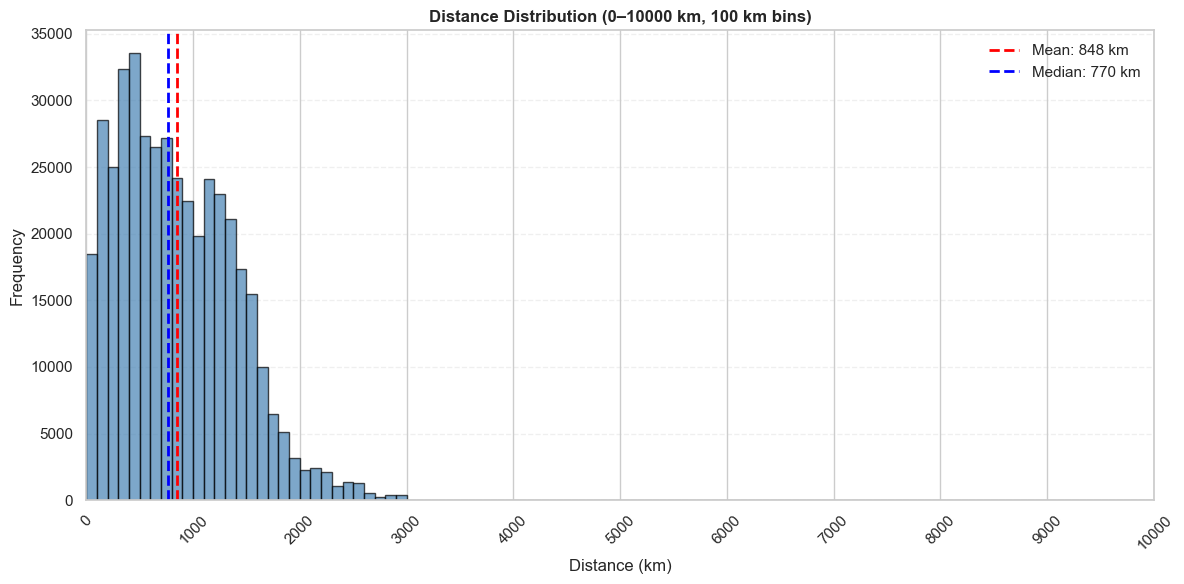

In [145]:
# ============================================================
# Graph: Distance Distribution – Custom X‑Axis Limit
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- SET YOUR DESIRED X-AXIS LIMIT HERE ---
X_AXIS_LIMIT = 10000   # change this to any km value, e.g., 5000, 8000, 15000, etc.
# -------------------------------------------

# Use the appropriate distance column
if 'Corrected_Distance' in df.columns:
    dist_col = 'Corrected_Distance'
else:
    dist_col = 'Distance'

distance = df[dist_col].dropna()

# Trim data to the user-defined x-axis limit (optional: keep full data but only show up to limit)
distance_trimmed = distance[distance <= X_AXIS_LIMIT]

# Compute mean and median on FULL data (or trimmed; choose as you like)
mean_dist = distance.mean()
median_dist = distance.median()

# Set bin width (e.g., 100 km bins; adjust as needed)
bin_width = 100
bins = np.arange(0, X_AXIS_LIMIT + bin_width, bin_width)

plt.figure(figsize=(12, 6))
counts, bin_edges, patches = plt.hist(distance_trimmed, bins=bins, edgecolor='black', alpha=0.7, color='steelblue')

# Add vertical lines for mean and median
plt.axvline(mean_dist, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_dist:,.0f} km')
plt.axvline(median_dist, color='blue', linestyle='--', linewidth=2, label=f'Median: {median_dist:,.0f} km')

# X‑axis ticks (e.g., every 1000 km)
tick_step = 1000
tick_positions = np.arange(0, X_AXIS_LIMIT + tick_step, tick_step)
plt.xticks(tick_positions, rotation=45)

plt.xlim(0, X_AXIS_LIMIT)
plt.title(f'Distance Distribution (0–{X_AXIS_LIMIT} km, {bin_width} km bins)', fontweight='bold')
plt.xlabel('Distance (km)')
plt.ylabel('Frequency')

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

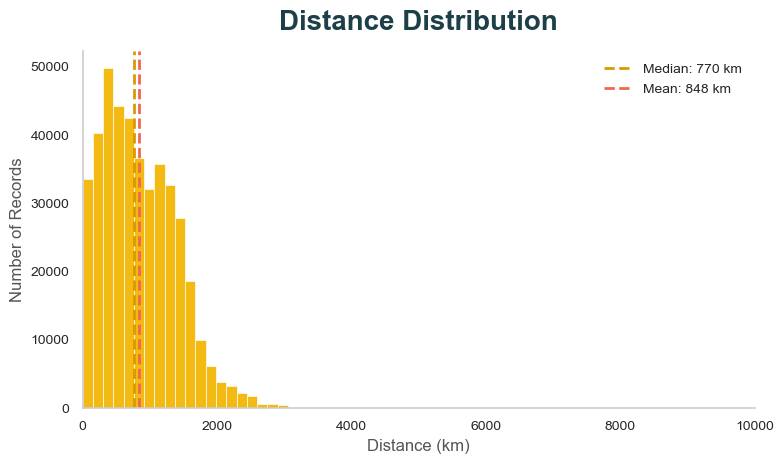

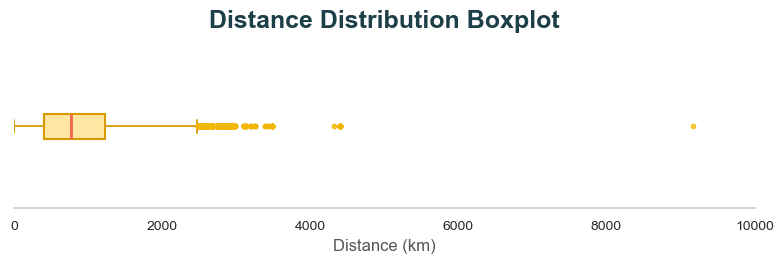

In [148]:
# ============================================================
# Distance Distribution Graphs - Yellow Theme
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Choose the distance column
if 'Corrected_Distance' in df.columns:
    dist_col = 'Corrected_Distance'
else:
    dist_col = 'Distance'

distance = df[dist_col].dropna()

# Remove zero or negative values if any
distance_positive = distance[distance > 0]

# Compute statistics
mean_dist = distance_positive.mean()
median_dist = distance_positive.median()

# Yellow / orange color palette
dark_yellow = "#D99A00"
gold = "#F2B705"
orange = "#F1664E"
light_yellow = "#FFE7A3"
text_color = "#1D3F47"

# ============================================================
# 1. Histogram: Distance Distribution
# ============================================================

plt.figure(figsize=(8, 4.8))

plt.hist(
    distance_positive,
    bins=60,
    color=gold,
    edgecolor="white",
    linewidth=0.5,
    alpha=0.95
)

plt.axvline(
    median_dist,
    color=dark_yellow,
    linestyle="--",
    linewidth=2,
    label=f"Median: {median_dist:,.0f} km"
)

plt.axvline(
    mean_dist,
    color=orange,
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_dist:,.0f} km"
)

plt.title(
    "Distance Distribution",
    fontsize=20,
    fontweight="bold",
    color=text_color,
    pad=15
)

plt.xlabel(
    "Distance (km)",
    fontsize=12,
    color="#555555"
)

plt.ylabel(
    "Number of Records",
    fontsize=12,
    color="#555555"
)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.xlim(0, 10000)

plt.legend(frameon=False, fontsize=10)

for spine in ["top", "right"]:
    plt.gca().spines[spine].set_visible(False)

plt.gca().spines["bottom"].set_linewidth(1.2)
plt.gca().spines["left"].set_linewidth(1.2)

plt.grid(False)
plt.tight_layout()
plt.show()


# ============================================================
# 2. Boxplot: Distance Distribution
# ============================================================

plt.figure(figsize=(8, 2.8))

plt.boxplot(
    distance_positive,
    vert=False,
    patch_artist=True,
    boxprops=dict(facecolor=light_yellow, color=dark_yellow, linewidth=1.5),
    medianprops=dict(color=orange, linewidth=2),
    whiskerprops=dict(color=dark_yellow, linewidth=1.3),
    capprops=dict(color=dark_yellow, linewidth=1.3),
    flierprops=dict(
        marker="o",
        markerfacecolor=gold,
        markeredgecolor=gold,
        markersize=3,
        alpha=0.35
    )
)

plt.title(
    "Distance Distribution Boxplot",
    fontsize=18,
    fontweight="bold",
    color=text_color,
    pad=12
)

plt.xlabel(
    "Distance (km)",
    fontsize=12,
    color="#555555"
)

plt.yticks([])
plt.xticks(fontsize=10)

plt.xlim(0, 10000)

for spine in ["top", "right", "left"]:
    plt.gca().spines[spine].set_visible(False)

plt.gca().spines["bottom"].set_linewidth(1.2)

plt.grid(False)
plt.tight_layout()
plt.show()

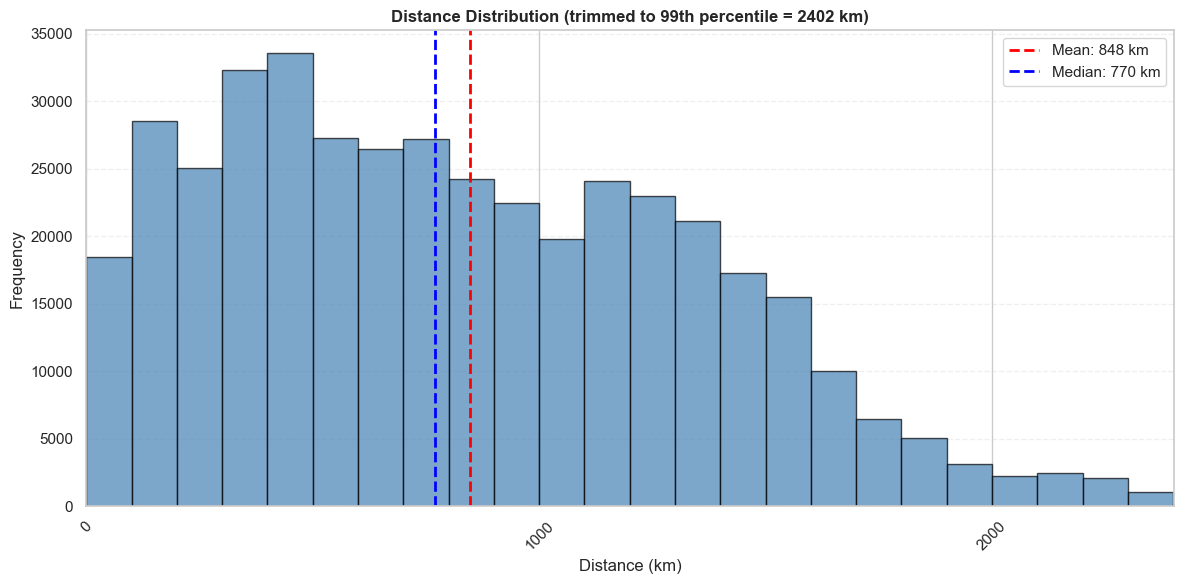

In [82]:
# ============================================================
# Graph: Distance Distribution (km) with Mean & Median Lines
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use the same distance column as above
if 'Corrected_Distance' in df.columns:
    dist_col = 'Corrected_Distance'
else:
    dist_col = 'Distance'

distance = df[dist_col].dropna()

# Trim to 99th percentile to avoid extreme outliers stretching the x-axis
upper_limit = np.percentile(distance, 99)
distance_trimmed = distance[distance <= upper_limit]

# Compute mean and median on trimmed data for line placement (or use full data)
mean_dist = distance.mean()
median_dist = distance.median()

# Create bins: e.g., 100 km bins up to the trimmed limit
bin_width = 100
bins = np.arange(0, upper_limit + bin_width, bin_width)

plt.figure(figsize=(12, 6))
counts, bin_edges, patches = plt.hist(distance_trimmed, bins=bins, edgecolor='black', alpha=0.7, color='steelblue')

# Add vertical lines for mean and median
plt.axvline(mean_dist, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_dist:,.0f} km')
plt.axvline(median_dist, color='blue', linestyle='--', linewidth=2, label=f'Median: {median_dist:,.0f} km')

# X-axis ticks every 500 km (or adjust based on data range)
tick_step = 1000
tick_positions = np.arange(0, upper_limit + tick_step, tick_step)
plt.xticks(tick_positions, rotation=45)

plt.xlim(0, upper_limit)
plt.title(f'Distance Distribution (trimmed to 99th percentile = {upper_limit:.0f} km)', fontweight='bold')
plt.xlabel('Distance (km)')
plt.ylabel('Frequency')

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

In [84]:
# ============================================================
# Numeric Summary: Distance Distribution (km)
# ============================================================

import pandas as pd
import numpy as np

# Choose the distance column (use 'Corrected_Distance' if available, else 'Distance')
if 'Corrected_Distance' in df.columns:
    dist_col = 'Corrected_Distance'
else:
    dist_col = 'Distance'

distance = df[dist_col].dropna()

# Compute statistics
mean_dist = distance.mean()
median_dist = distance.median()
std_dist = distance.std()
min_dist = distance.min()
max_dist = distance.max()
q1 = distance.quantile(0.25)
q3 = distance.quantile(0.75)

print("=" * 60)
print("DISTANCE DISTRIBUTION STATISTICS (km)")
print("=" * 60)
print(f"Mean Distance:          {mean_dist:>12,.2f} km")
print(f"Median Distance:        {median_dist:>12,.2f} km")
print(f"Standard Deviation:      {std_dist:>12,.2f} km")
print(f"Minimum Distance:        {min_dist:>12,.2f} km")
print(f"Maximum Distance:        {max_dist:>12,.2f} km")
print(f"25th Percentile (Q1):    {q1:>12,.2f} km")
print(f"75th Percentile (Q3):    {q3:>12,.2f} km")
print("=" * 60)

DISTANCE DISTRIBUTION STATISTICS (km)
Mean Distance:                847.69 km
Median Distance:              770.00 km
Standard Deviation:            547.81 km
Minimum Distance:                1.00 km
Maximum Distance:            9,164.00 km
25th Percentile (Q1):          402.00 km
75th Percentile (Q3):        1,234.00 km


In [86]:
# ============================================================
# Numeric Summary: Distance Distribution (km)
# ============================================================

import pandas as pd
import numpy as np

# Choose the distance column (use 'Corrected_Distance' if available, else 'Distance')
if 'Corrected_Distance' in df.columns:
    dist_col = 'Corrected_Distance'
else:
    dist_col = 'Distance'

distance = df[dist_col].dropna()

# Compute statistics
mean_dist = distance.mean()
median_dist = distance.median()
std_dist = distance.std()
min_dist = distance.min()
max_dist = distance.max()
q1 = distance.quantile(0.25)
q3 = distance.quantile(0.75)

print("=" * 60)
print("DISTANCE DISTRIBUTION STATISTICS (km)")
print("=" * 60)
print(f"Mean Distance:          {mean_dist:>12,.2f} km")
print(f"Median Distance:        {median_dist:>12,.2f} km")
print(f"Standard Deviation:      {std_dist:>12,.2f} km")
print(f"Minimum Distance:        {min_dist:>12,.2f} km")
print(f"Maximum Distance:        {max_dist:>12,.2f} km")
print(f"25th Percentile (Q1):    {q1:>12,.2f} km")
print(f"75th Percentile (Q3):    {q3:>12,.2f} km")
print("=" * 60)

DISTANCE DISTRIBUTION STATISTICS (km)
Mean Distance:                847.69 km
Median Distance:              770.00 km
Standard Deviation:            547.81 km
Minimum Distance:                1.00 km
Maximum Distance:            9,164.00 km
25th Percentile (Q1):          402.00 km
75th Percentile (Q3):        1,234.00 km


<a id="2-2-7-8-Vehicle-Body-Type-Distribution"></a>
##### 2.2.7.8 Vehicle Body Type Distribution


In [149]:
import pandas as pd

# ============================================================
# Vehicle Body Type Distribution: Top 3 + Others
# ============================================================

# Get counts
vb_counts = df['Vehicle_body_type'].value_counts(dropna=False)

# Top 3
top3 = vb_counts.head(3)

# Others
others = vb_counts.iloc[3:].sum()

# Combine Top 3 + Others
final_counts = top3.copy()
final_counts['Others'] = others

# Calculate percentages
final_pct = final_counts / final_counts.sum() * 100

# Create summary table
vehicle_body_summary = pd.DataFrame({
    'Vehicle Body Type': final_counts.index,
    'Count': final_counts.values,
    'Percentage (%)': final_pct.values.round(2)
})

# Print formatted output
print("=" * 70)
print("VEHICLE BODY TYPE DISTRIBUTION: TOP 3 + OTHERS")
print("=" * 70)
print(vehicle_body_summary.to_string(index=False))
print("=" * 70)

# Optional: print total records
print(f"Total Records: {final_counts.sum():,}")

VEHICLE BODY TYPE DISTRIBUTION: TOP 3 + OTHERS
Vehicle Body Type  Count  Percentage (%)
 Full Punjab Body 274002           64.73
        Dala Body  88328           20.87
   Container Body  39564            9.35
           Others  21417            5.06
Total Records: 423,311


VEHICLE BODY TYPE DISTRIBUTION: TOP 3 + OTHERS
Vehicle Body Type  Count  Percentage (%)
 Full Punjab Body 274002           64.73
        Dala Body  88328           20.87
   Container Body  39564            9.35
           Others  21417            5.06
Total Records: 423,311


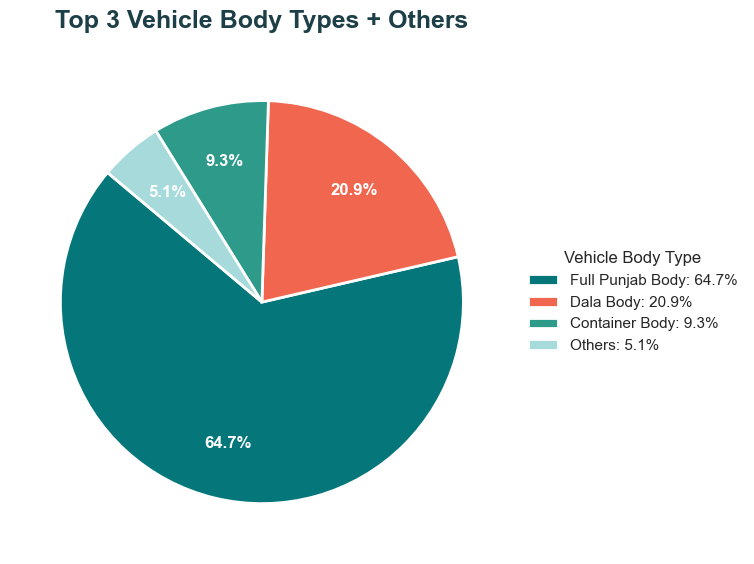

In [150]:
# ============================================================
# Vehicle Body Type Distribution: Top 3 + Others
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Get counts
vb_counts = df['Vehicle_body_type'].value_counts(dropna=False)

# Top 3 body types
top3 = vb_counts.head(3)

# Combine remaining categories as Others
others = vb_counts.iloc[3:].sum()

final_counts = top3.copy()
final_counts['Others'] = others

# Calculate percentages
final_pct = final_counts / final_counts.sum() * 100

# Summary table
vehicle_body_summary = pd.DataFrame({
    'Vehicle Body Type': final_counts.index,
    'Count': final_counts.values,
    'Percentage (%)': final_pct.values.round(2)
})

print("=" * 70)
print("VEHICLE BODY TYPE DISTRIBUTION: TOP 3 + OTHERS")
print("=" * 70)
print(vehicle_body_summary.to_string(index=False))
print("=" * 70)
print(f"Total Records: {final_counts.sum():,}")

# Color palette matching your EDA style
colors = [
    "#05777B",  # deep teal
    "#F1664E",  # coral
    "#2D9A8A",  # teal green
    "#A6DADB"   # light aqua for Others
]

text_color = "#1D3F47"

# Legend labels with percentages
legend_labels = [
    f"{label}: {pct:.1f}%"
    for label, pct in zip(final_counts.index, final_pct.values)
]

# Plot
plt.figure(figsize=(7.5, 5.8))

wedges, texts, autotexts = plt.pie(
    final_counts,
    labels=None,
    autopct=lambda p: f"{p:.1f}%" if p >= 2 else "",
    startangle=140,
    colors=colors[:len(final_counts)],
    pctdistance=0.72,
    wedgeprops={
        "edgecolor": "white",
        "linewidth": 2
    }
)

# Style percentage labels
for autotext in autotexts:
    autotext.set_color("white")
    autotext.set_fontsize(12)
    autotext.set_fontweight("bold")

# Title
plt.title(
    "Top 3 Vehicle Body Types + Others",
    fontsize=18,
    fontweight="bold",
    color=text_color,
    pad=16
)

# Legend
plt.legend(
    wedges,
    legend_labels,
    title="Vehicle Body Type",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    fontsize=11,
    title_fontsize=12,
    frameon=False
)

plt.tight_layout()
plt.show()

<a id="2-2-7-9-Distance-vs-Cost"></a>
##### 2.2.7.9 Distance vs Cost


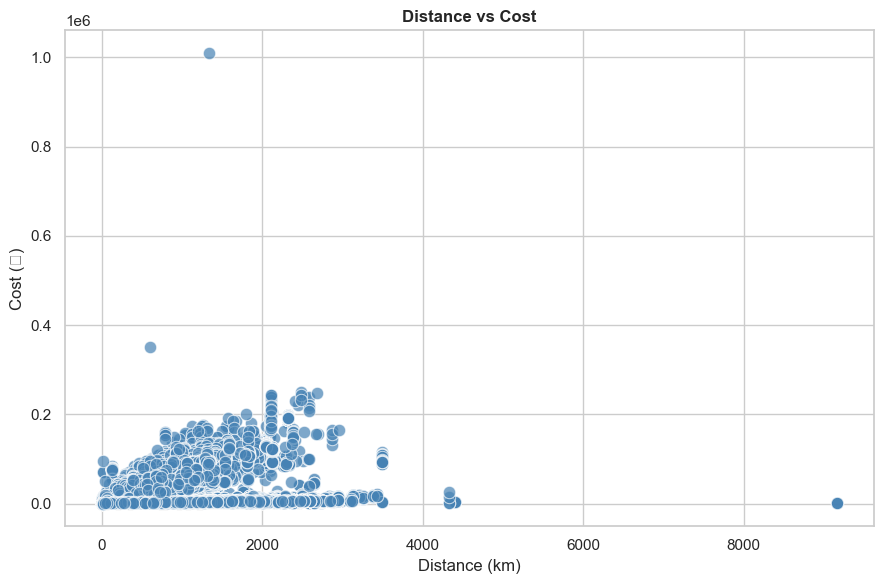

In [151]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='Distance', y='Cost',
                alpha=0.7, color='steelblue', edgecolor='white', s=80)
plt.title('Distance vs Cost')
plt.xlabel('Distance (km)')
plt.ylabel('Cost (₹)')
plt.tight_layout()
plt.show()

In [160]:
# ============================================================
# Numerical Summary: Distance vs Cost
# ============================================================

import pandas as pd
import numpy as np

# Use Distance and Cost columns
analysis_df = df[['Distance', 'Cost']].copy()

# Drop missing values
analysis_df = analysis_df.dropna()

# Keep only valid positive values
analysis_df = analysis_df[
    (analysis_df['Distance'] > 0) &
    (analysis_df['Cost'] > 0)
]

# Rename for clear output
distance = analysis_df['Distance']
cost = analysis_df['Cost']

# Correlation
pearson_corr = distance.corr(cost, method='pearson')
spearman_corr = distance.corr(cost, method='spearman')

# Cost per km
analysis_df['Cost_per_km'] = analysis_df['Cost'] / analysis_df['Distance']

# Summary statistics
summary = pd.DataFrame({
    'Metric': [
        'Total Valid Records',
        'Minimum Distance (km)',
        'Median Distance (km)',
        'Mean Distance (km)',
        'Maximum Distance (km)',
        'Minimum Cost (Rupees)',
        'Median Cost (Rupees)',
        'Mean Cost (Rupees)',
        'Maximum Cost (Rupees)',
        'Median Cost per km',
        'Mean Cost per km',
        'Pearson Correlation',
        'Spearman Correlation'
    ],
    'Value': [
        f"{len(analysis_df):,}",
        f"{distance.min():,.2f}",
        f"{distance.median():,.2f}",
        f"{distance.mean():,.2f}",
        f"{distance.max():,.2f}",
        f"{cost.min():,.2f}",
        f"{cost.median():,.2f}",
        f"{cost.mean():,.2f}",
        f"{cost.max():,.2f}",
        f"{analysis_df['Cost_per_km'].median():,.2f}",
        f"{analysis_df['Cost_per_km'].mean():,.2f}",
        f"{pearson_corr:.2f}",
        f"{spearman_corr:.2f}"
    ]
})

print("=" * 75)
print("NUMERICAL SUMMARY: DISTANCE VS COST")
print("=" * 75)
print(summary.to_string(index=False))
print("=" * 75)

NUMERICAL SUMMARY: DISTANCE VS COST
               Metric        Value
  Total Valid Records      423,311
Minimum Distance (km)         1.00
 Median Distance (km)       770.00
   Mean Distance (km)       847.69
Maximum Distance (km)     9,164.00
Minimum Cost (Rupees)        15.00
 Median Cost (Rupees)     2,710.00
   Mean Cost (Rupees)     5,913.89
Maximum Cost (Rupees) 1,009,910.00
   Median Cost per km         3.59
     Mean Cost per km         9.20
  Pearson Correlation         0.14
 Spearman Correlation         0.77


<a id="2-2-7-10-Average-Cost-by-Contract-Type"></a>
##### 2.2.7.10 Average Cost by Contract Type


In [164]:
# ============================================================
# Average Cost by Contract Type - Code
# ============================================================

import pandas as pd

# Assuming 'df' is your DataFrame with 'Contract_type' and 'Cost' columns
# Drop NaN contract types if any
df_temp = df[df['Contract_type'].notna()].copy()

# Calculate average cost per contract type
contract_avg = df_temp.groupby('Contract_type')['Cost'].mean().round(2).reset_index()
contract_avg.columns = ['Contract_Type', 'Avg_Cost']

# Sort by Avg_Cost descending (to match your output order: DAILY highest)
# If your output is in a specific order, you can hardcode or sort as needed
# Your shown order: DAILY, SPOT, SHORT, MONTHLY, LONG
# Let's sort by Avg_Cost descending
contract_avg = contract_avg.sort_values('Avg_Cost', ascending=False).reset_index(drop=True)

# Calculate overall average
overall_avg = df['Cost'].mean().round(2)

# Print the table exactly as requested
print("=" * 60)
print("AVERAGE COST BY CONTRACT TYPE")
print("=" * 60)
print(contract_avg.to_string(index=False))
print(f"\nOverall Average Cost: ₹{overall_avg:,.2f}")
print("=" * 60)

AVERAGE COST BY CONTRACT TYPE
Contract_Type  Avg_Cost
        DAILY  12680.69
         SPOT   7174.91
        SHORT   6101.57
      MONTHLY   4395.82
         LONG   3331.27

Overall Average Cost: ₹5,913.89


AVERAGE COST BY CONTRACT TYPE
Contract_Type  Avg_Cost
        DAILY  12680.69
         SPOT   7174.91
        SHORT   6101.57
      MONTHLY   4395.82
         LONG   3331.27

Overall Average Cost: ₹5,913.89


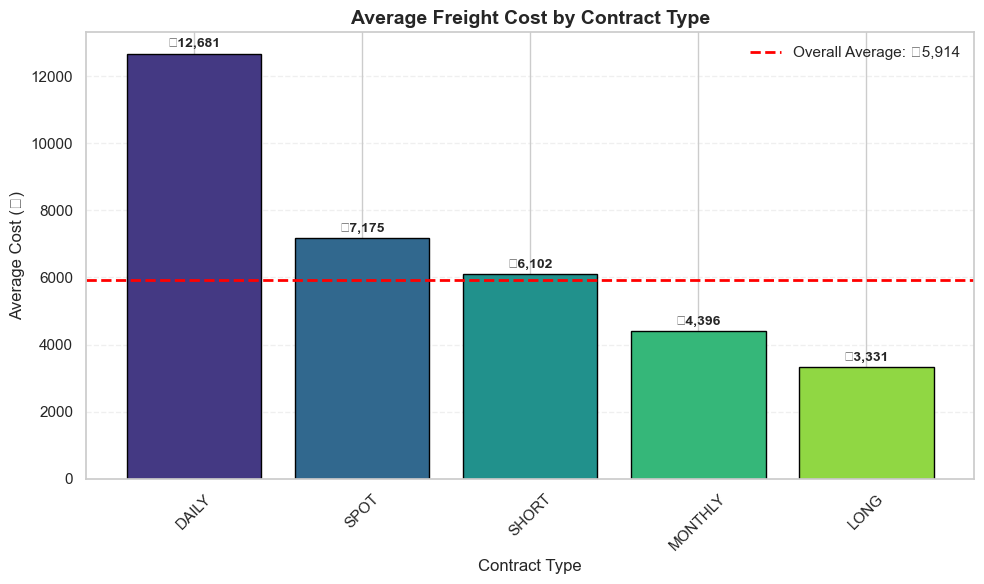

In [162]:
# ============================================================
# Bivariate Analysis: Average Cost by Contract Type
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'df' is your DataFrame with 'Contract_type' and 'Cost' columns
# Calculate average cost per contract type
contract_avg = df.groupby('Contract_type')['Cost'].mean().sort_values(ascending=False).reset_index()
contract_avg.columns = ['Contract_Type', 'Avg_Cost']
contract_avg['Avg_Cost'] = contract_avg['Avg_Cost'].round(2)

# Calculate overall average cost (for reference line)
overall_avg = df['Cost'].mean()

# Print summary table
print("=" * 60)
print("AVERAGE COST BY CONTRACT TYPE")
print("=" * 60)
print(contract_avg.to_string(index=False))
print(f"\nOverall Average Cost: ₹{overall_avg:,.2f}")
print("=" * 60)

# Create bar chart
plt.figure(figsize=(10, 6))
colors = sns.color_palette('viridis', len(contract_avg))
bars = plt.bar(contract_avg['Contract_Type'], contract_avg['Avg_Cost'], color=colors, edgecolor='black')

# Add horizontal line for overall average
plt.axhline(y=overall_avg, color='red', linestyle='--', linewidth=2, label=f'Overall Average: ₹{overall_avg:,.0f}')

# Add data labels on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 100,
             f'₹{height:,.0f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title('Average Freight Cost by Contract Type', fontweight='bold', fontsize=14)
plt.xlabel('Contract Type')
plt.ylabel('Average Cost (₹)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

<a id="2-2-7-11-Yearly-and-Monthly-Cost-Trends"></a>
##### 2.2.7.11 Yearly and Monthly Cost Trends


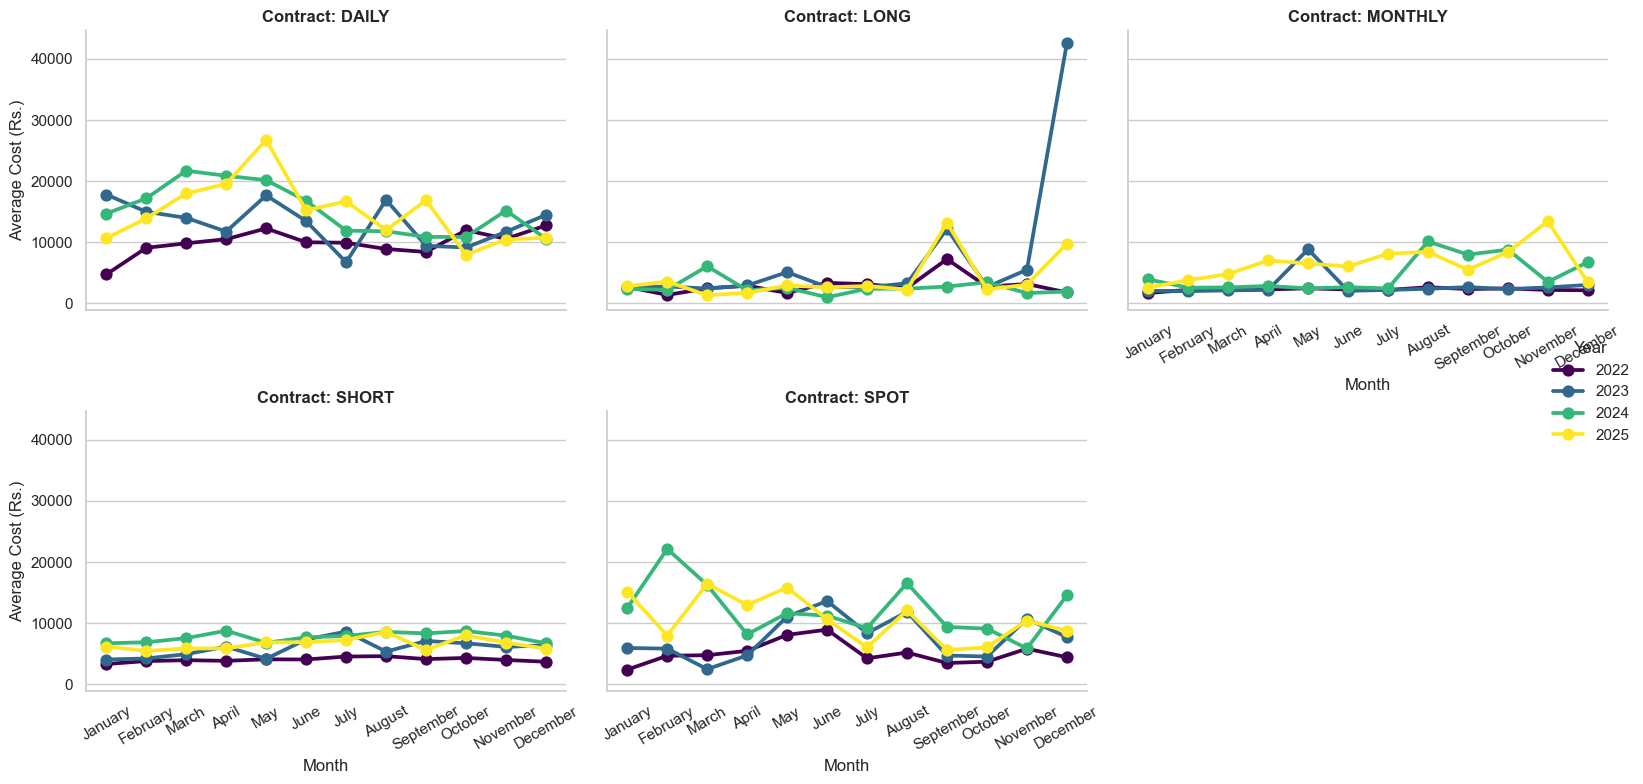

In [158]:
# ============================================================
# Average Monthly Cost by Contract Type and Year
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# Prepare data
# ------------------------------------------------------------

df_plot = df.copy()

# Convert Cost to numeric
df_plot['Cost'] = pd.to_numeric(df_plot['Cost'], errors='coerce')

# Drop missing values needed for this analysis
df_plot = df_plot.dropna(subset=['Contract_type', 'Month', 'Year', 'Cost'])

# Month order
MONTH_ORDER = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]

# If Month is numeric, convert to month name
if pd.api.types.is_numeric_dtype(df_plot['Month']):
    df_plot['Month'] = pd.to_datetime(df_plot['Month'], format='%m').dt.month_name()

# Set proper month order
df_plot['Month'] = pd.Categorical(
    df_plot['Month'],
    categories=MONTH_ORDER,
    ordered=True
)

# Group by Contract Type, Month, and Year
monthly_contract = (
    df_plot
    .groupby(['Contract_type', 'Month', 'Year'], observed=False)['Cost']
    .mean()
    .reset_index()
)

monthly_contract = monthly_contract.sort_values(['Contract_type', 'Year', 'Month'])

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

sns.set_theme(style="whitegrid")

g = sns.catplot(
    data=monthly_contract,
    x='Month',
    y='Cost',
    col='Contract_type',
    hue='Year',
    kind='point',
    col_wrap=3,
    height=4,
    aspect=1.3,
    palette='viridis',
    markers='o',
    linestyles='-'
)

# Titles and labels
g.set_titles("Contract: {col_name}", size=12, weight='bold')
g.set_axis_labels("Month", "Average Cost (Rs.)")

# Rotate month labels
for ax in g.axes.flat:
    ax.tick_params(axis='x', rotation=30)
    ax.set_xlabel("Month")
    ax.set_ylabel("Average Cost (Rs.)")

# Legend title
if g._legend is not None:
    g._legend.set_title("Year")

plt.tight_layout()
plt.show()

In [166]:
# ============================================================
# Numerical Summary:
# Year-on-Year Average Cost, Median Cost and Transaction Count
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# Prepare data
# ------------------------------------------------------------

num_df = df.copy()

num_df['Year'] = pd.to_numeric(num_df['Year'], errors='coerce')
num_df['Cost'] = pd.to_numeric(num_df['Cost'], errors='coerce')

num_df = num_df.dropna(subset=['Year', 'Cost'])
num_df['Year'] = num_df['Year'].astype(int)

# ------------------------------------------------------------
# Yearly summary
# ------------------------------------------------------------

yearly_summary = (
    num_df
    .groupby('Year')
    .agg(
        Transaction_Count=('Cost', 'count'),
        Average_Cost=('Cost', 'mean'),
        Median_Cost=('Cost', 'median'),
        Minimum_Cost=('Cost', 'min'),
        Maximum_Cost=('Cost', 'max'),
        Std_Dev_Cost=('Cost', 'std')
    )
    .reset_index()
)

# Sort by year
yearly_summary = yearly_summary.sort_values('Year')

# Year-on-year changes
yearly_summary['Avg_Cost_YoY_Change (%)'] = (
    yearly_summary['Average_Cost'].pct_change() * 100
)

yearly_summary['Transaction_YoY_Change (%)'] = (
    yearly_summary['Transaction_Count'].pct_change() * 100
)

# Round values
cost_cols = [
    'Average_Cost',
    'Median_Cost',
    'Minimum_Cost',
    'Maximum_Cost',
    'Std_Dev_Cost'
]

yearly_summary[cost_cols] = yearly_summary[cost_cols].round(2)

yearly_summary[
    ['Avg_Cost_YoY_Change (%)', 'Transaction_YoY_Change (%)']
] = yearly_summary[
    ['Avg_Cost_YoY_Change (%)', 'Transaction_YoY_Change (%)']
].round(2)

# Rename columns for clean output
yearly_summary = yearly_summary.rename(columns={
    'Year': 'Year',
    'Transaction_Count': 'Transaction Count',
    'Average_Cost': 'Average Cost (Rs.)',
    'Median_Cost': 'Median Cost (Rs.)',
    'Minimum_Cost': 'Minimum Cost (Rs.)',
    'Maximum_Cost': 'Maximum Cost (Rs.)',
    'Std_Dev_Cost': 'Std. Dev. Cost (Rs.)'
})

# ------------------------------------------------------------
# Print summary
# ------------------------------------------------------------

print("=" * 130)
print("YEARLY SUMMARY: AVERAGE COST, MEDIAN COST AND TRANSACTION COUNT")
print("=" * 130)
print(yearly_summary.to_string(index=False))
print("=" * 130)

YEARLY SUMMARY: AVERAGE COST, MEDIAN COST AND TRANSACTION COUNT
 Year  Transaction Count  Average Cost (Rs.)  Median Cost (Rs.)  Minimum Cost (Rs.)  Maximum Cost (Rs.)  Std. Dev. Cost (Rs.)  Avg_Cost_YoY_Change (%)  Transaction_YoY_Change (%)
 2022              95903             4196.13             2819.0                70.0            238510.0               9459.38                      NaN                         NaN
 2023             116167             5793.98             2820.0               170.0            249510.0              14459.58                    38.08                       21.13
 2024             127257             7079.99             2610.0                15.0            244460.0              16941.40                    22.20                        9.55
 2025              83984             6274.36             2570.0                60.0           1009910.0              14977.07                   -11.38                      -34.00


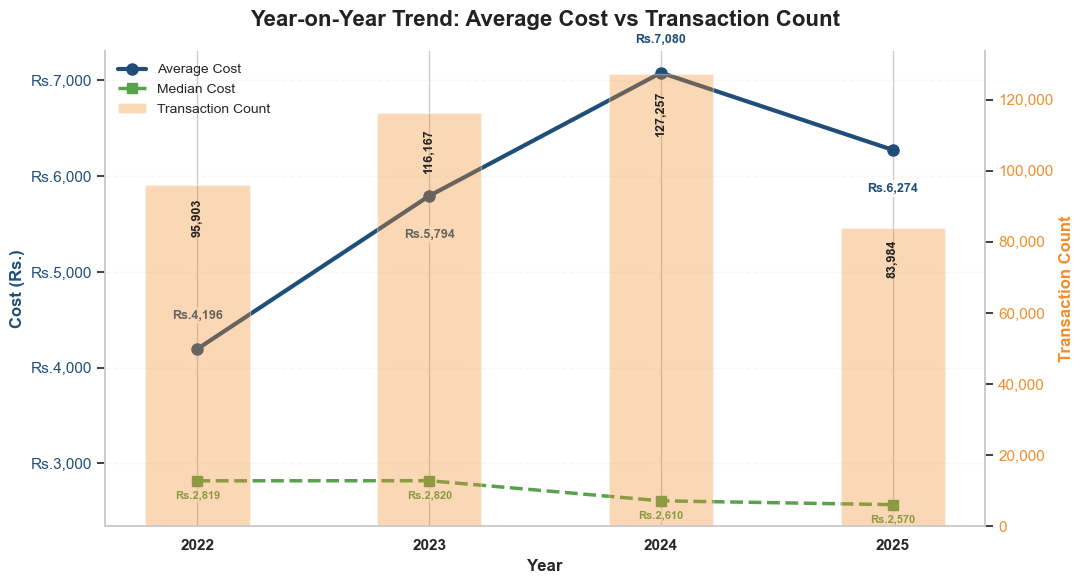

In [165]:
# ============================================================
# Year-on-Year Trend: Average Cost vs Transaction Count
# Clear labels, no overlap, PPT-friendly colors
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter

# ------------------------------------------------------------
# Prepare data
# ------------------------------------------------------------

plot_df = df.copy()

# Ensure correct data types
plot_df['Year'] = pd.to_numeric(plot_df['Year'], errors='coerce')
plot_df['Cost'] = pd.to_numeric(plot_df['Cost'], errors='coerce')

# Remove missing values
plot_df = plot_df.dropna(subset=['Year', 'Cost'])

# Convert Year to integer
plot_df['Year'] = plot_df['Year'].astype(int)

# Group by Year
yearly_stats = (
    plot_df
    .groupby('Year')
    .agg(
        Average_Cost=('Cost', 'mean'),
        Median_Cost=('Cost', 'median'),
        Transaction_Count=('Cost', 'count')
    )
    .reset_index()
)

# Sort by year
yearly_stats = yearly_stats.sort_values('Year')

# Round values
yearly_stats['Average_Cost'] = yearly_stats['Average_Cost'].round(0)
yearly_stats['Median_Cost'] = yearly_stats['Median_Cost'].round(0)

# ------------------------------------------------------------
# Colors
# ------------------------------------------------------------

line_color = "#1F4E79"       # deep blue
bar_color = "#F28E2B"        # orange
median_color = "#59A14F"     # green
text_color = "#222222"
grid_color = "#EAEAEA"

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

fig, ax1 = plt.subplots(figsize=(11, 6))

# ------------------------------------------------------------
# Bar chart: Transaction Count
# ------------------------------------------------------------

ax2 = ax1.twinx()

bars = ax2.bar(
    yearly_stats['Year'],
    yearly_stats['Transaction_Count'],
    color=bar_color,
    alpha=0.35,
    width=0.45,
    label='Transaction Count'
)

ax2.set_ylabel(
    "Transaction Count",
    fontsize=12,
    fontweight="bold",
    color=bar_color
)

ax2.tick_params(axis='y', labelcolor=bar_color)

# Format transaction count axis
ax2.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{int(x):,}")
)

# Add bar labels inside/top of bars to avoid overlap
for bar, count in zip(bars, yearly_stats['Transaction_Count']):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() * 0.96,
        f"{count:,}",
        ha="center",
        va="top",
        fontsize=9,
        fontweight="bold",
        color=text_color,
        rotation=90
    )

# ------------------------------------------------------------
# Line chart: Average Cost
# ------------------------------------------------------------

ax1.plot(
    yearly_stats['Year'],
    yearly_stats['Average_Cost'],
    marker='o',
    linestyle='-',
    linewidth=3,
    markersize=8,
    color=line_color,
    label='Average Cost'
)

# Optional: Median Cost line for comparison
ax1.plot(
    yearly_stats['Year'],
    yearly_stats['Median_Cost'],
    marker='s',
    linestyle='--',
    linewidth=2.5,
    markersize=7,
    color=median_color,
    label='Median Cost'
)

ax1.set_xlabel(
    "Year",
    fontsize=12,
    fontweight="bold"
)

ax1.set_ylabel(
    "Cost (Rs.)",
    fontsize=12,
    fontweight="bold",
    color=line_color
)

ax1.tick_params(axis='y', labelcolor=line_color)

# Format cost axis
ax1.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"Rs.{int(x):,}")
)

# Add average cost labels with alternating positions to avoid overlap
cost_offset = yearly_stats['Average_Cost'].max() * 0.04

for i, row in yearly_stats.iterrows():
    offset = cost_offset if i % 2 == 0 else -cost_offset * 1.2
    va_position = "bottom" if i % 2 == 0 else "top"
    
    ax1.text(
        row['Year'],
        row['Average_Cost'] + offset,
        f"Rs.{row['Average_Cost']:,.0f}",
        ha="center",
        va=va_position,
        fontsize=9,
        fontweight="bold",
        color=line_color,
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.75,
            boxstyle="round,pad=0.2"
        )
    )

# Add median cost labels smaller
median_offset = yearly_stats['Median_Cost'].max() * 0.035

for i, row in yearly_stats.iterrows():
    ax1.text(
        row['Year'],
        row['Median_Cost'] - median_offset,
        f"Rs.{row['Median_Cost']:,.0f}",
        ha="center",
        va="top",
        fontsize=8,
        fontweight="bold",
        color=median_color,
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.65,
            boxstyle="round,pad=0.15"
        )
    )

# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------

ax1.set_xticks(yearly_stats['Year'])
ax1.set_xticklabels(yearly_stats['Year'], fontweight='bold')

ax1.grid(axis='y', linestyle='--', alpha=0.4, color=grid_color)
ax2.grid(False)

plt.title(
    "Year-on-Year Trend: Average Cost vs Transaction Count",
    fontsize=16,
    fontweight="bold",
    pad=18,
    color=text_color
)

# Combined legend
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines_1 + lines_2,
    labels_1 + labels_2,
    loc="upper left",
    fontsize=10,
    frameon=False
)

# Remove unnecessary spines
for spine in ["top"]:
    ax1.spines[spine].set_visible(False)
    ax2.spines[spine].set_visible(False)

plt.tight_layout()

# Optional save for PPT
plt.savefig(
    "yoy_average_cost_transaction_count_clear.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [96]:
# ============================================================
# Yearly Summary: Average Cost & Transaction Count
# ============================================================

import pandas as pd

# Assuming 'df' is your DataFrame with 'Year' and 'Cost' columns
yearly_summary = df.groupby('Year').agg(
    avg_cost=('Cost', 'mean'),
    transaction_count=('Cost', 'count')
).reset_index()

# Round average cost to 2 decimal places
yearly_summary['avg_cost'] = yearly_summary['avg_cost'].round(2)

# Print the table
print("=" * 60)
print("YEARLY SUMMARY")
print("=" * 60)
print(yearly_summary.to_string(index=False))

YEARLY SUMMARY
 Year  avg_cost  transaction_count
 2022   4196.13              95903
 2023   5793.98             116167
 2024   7079.99             127257
 2025   6274.36              83984


<a id="2-2-7-12-Correlation-Matrix-Numerical-Features"></a>
##### 2.2.7.12 Correlation Matrix — Numerical Features


CORRELATION MATRIX: NUMERICAL FEATURES
               Cost  Price_per_KM  Distance  Vehicle_Load   week  month   Year
Cost          1.000         0.471     0.143        -0.116  0.010  0.011  0.049
Price_per_KM  0.471         1.000    -0.113        -0.161 -0.001  0.001  0.049
Distance      0.143        -0.113     1.000         0.467  0.003 -0.002 -0.052
Vehicle_Load -0.116        -0.161     0.467         1.000  0.006 -0.001 -0.045
week          0.010        -0.001     0.003         0.006  1.000  0.996 -0.275
month         0.011         0.001    -0.002        -0.001  0.996  1.000 -0.256
Year          0.049         0.049    -0.052        -0.045 -0.275 -0.256  1.000


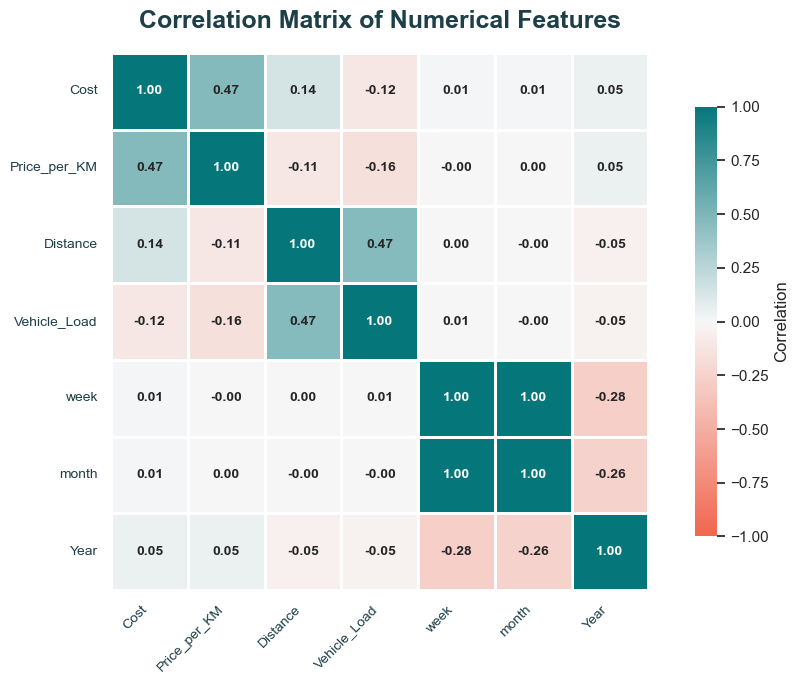


DESCRIPTIVE STATISTICS FOR NUMERICAL FEATURES
             Cost  Price_per_KM   Distance  Vehicle_Load       week  \
count   395877.00     395877.00  395877.00     395877.00  395877.00   
mean      6050.74          9.51     850.63         24.58      26.72   
std      14795.74         30.77     551.52          8.16      14.95   
min         15.00          0.25       1.00          3.00       0.00   
25%       1740.00          2.98     403.00         20.00      14.00   
50%       2710.00          3.78     770.00         25.50      27.00   
75%       3710.00          5.44    1238.00         30.50      40.00   
max    1009910.00       9490.25    9164.00         60.50      53.00   

           month       Year  
count  395877.00  395877.00  
mean        6.75    2023.57  
std         3.40       1.01  
min         1.00    2022.00  
25%         4.00    2023.00  
50%         7.00    2024.00  
75%        10.00    2024.00  
max        12.00    2025.00  


In [168]:
# ============================================================
# Correlation Matrix — Numerical Features
# PPT Color Format
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# ------------------------------------------------------------
# Select numerical columns
# ------------------------------------------------------------

numeric_cols = [
    'Cost',
    'Price_per_KM',
    'Distance',
    'Vehicle_Load',
    'week',
    'month',
    'Year'
]

# Use Corrected_Distance if available
if 'Corrected_Distance' in df.columns and 'Distance' in numeric_cols:
    numeric_cols[numeric_cols.index('Distance')] = 'Corrected_Distance'

# Keep only columns that exist in df
available_cols = [col for col in numeric_cols if col in df.columns]

# Create numeric dataframe
df_numeric = df[available_cols].copy()

# Convert all selected columns to numeric
for col in available_cols:
    df_numeric[col] = pd.to_numeric(df_numeric[col], errors='coerce')

# Drop missing values for correlation
df_corr = df_numeric.dropna()

# Compute correlation matrix
corr_matrix = df_corr.corr()

# ------------------------------------------------------------
# Print correlation matrix
# ------------------------------------------------------------

print("=" * 70)
print("CORRELATION MATRIX: NUMERICAL FEATURES")
print("=" * 70)
print(corr_matrix.round(3))
print("=" * 70)

# ------------------------------------------------------------
# PPT-style color theme
# ------------------------------------------------------------

PPT_COLORS = {
    "primary": "#05777B",      # deep teal
    "secondary": "#F1664E",    # coral
    "accent": "#2D9A8A",       # teal green
    "dark": "#1D3F47",         # dark text
    "light": "#A6DADB",        # light aqua
    "neutral": "#F7F7F7"       # center/neutral
}

# Custom diverging colormap: coral → white → teal
custom_cmap = LinearSegmentedColormap.from_list(
    "custom_corr",
    [
        PPT_COLORS["secondary"],
        PPT_COLORS["neutral"],
        PPT_COLORS["primary"]
    ]
)

# ------------------------------------------------------------
# Plot heatmap
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap=custom_cmap,
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.8,
    linecolor="white",
    cbar_kws={
        "shrink": 0.8,
        "label": "Correlation"
    },
    annot_kws={
        "fontsize": 10,
        "fontweight": "bold"
    }
)

plt.title(
    "Correlation Matrix of Numerical Features",
    fontsize=18,
    fontweight="bold",
    color=PPT_COLORS["dark"],
    pad=18
)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=10,
    color=PPT_COLORS["dark"]
)

plt.yticks(
    rotation=0,
    fontsize=10,
    color=PPT_COLORS["dark"]
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Descriptive Statistics
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DESCRIPTIVE STATISTICS FOR NUMERICAL FEATURES")
print("=" * 70)
print(df_corr.describe().round(2))
print("=" * 70)

In [100]:
# ============================================================
# Correlation Matrix & Descriptive Statistics — Numerical Features
# ============================================================

import pandas as pd
import numpy as np

# Define numerical features (use available columns)
# Adjust if needed: use 'Corrected_Distance' if present
distance_col = 'Corrected_Distance' if 'Corrected_Distance' in df.columns else 'Distance'

numeric_cols = ['Cost', 'Price_per_KM', distance_col, 'Vehicle_Load', 'week', 'month', 'Year']
# Ensure only columns that exist in df
numeric_cols = [col for col in numeric_cols if col in df.columns]

# Drop rows with NaN in any of these columns
df_numeric = df[numeric_cols].dropna()

# Compute correlation matrix (rounded to 3 decimals)
corr_matrix = df_numeric.corr().round(3)

# Print correlation matrix
print("=" * 60)
print("CORRELATION MATRIX (Numerical Features)")
print("=" * 60)
print(corr_matrix.to_string())
print("\nInterpretation:")
print("- Values close to 1 or -1 indicate strong correlation")
print("- Positive = direct relationship, Negative = inverse relationship")
print("=" * 60)

# Compute descriptive statistics (rounded to 2 decimals)
desc_stats = df_numeric.describe().round(2)

print("\n" + "=" * 60)
print("DESCRIPTIVE STATISTICS FOR NUMERICAL FEATURES")
print("=" * 60)
print(desc_stats.to_string())

CORRELATION MATRIX (Numerical Features)
               Cost  Price_per_KM  Distance  Vehicle_Load   week  month   Year
Cost          1.000         0.471     0.143        -0.116  0.010  0.011  0.049
Price_per_KM  0.471         1.000    -0.113        -0.161 -0.001  0.001  0.049
Distance      0.143        -0.113     1.000         0.467  0.003 -0.002 -0.052
Vehicle_Load -0.116        -0.161     0.467         1.000  0.006 -0.001 -0.045
week          0.010        -0.001     0.003         0.006  1.000  0.996 -0.275
month         0.011         0.001    -0.002        -0.001  0.996  1.000 -0.256
Year          0.049         0.049    -0.052        -0.045 -0.275 -0.256  1.000

Interpretation:
- Values close to 1 or -1 indicate strong correlation
- Positive = direct relationship, Negative = inverse relationship

DESCRIPTIVE STATISTICS FOR NUMERICAL FEATURES
             Cost  Price_per_KM   Distance  Vehicle_Load       week      month       Year
count   395877.00     395877.00  395877.00     395877.

<a id="2-2-7-13-Vehicle-Load-Distribution"></a>
##### 2.2.7.13 Vehicle Load Distribution


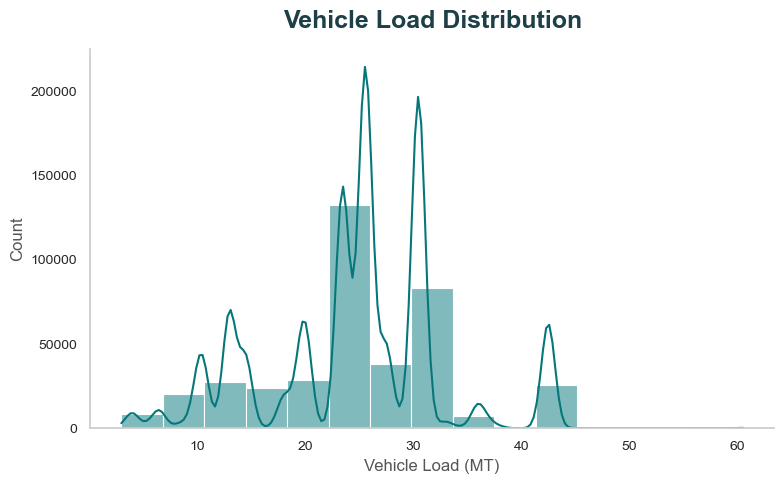

In [169]:
# ============================================================
# Vehicle Load Distribution Graph
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# Prepare data
# ------------------------------------------------------------

load_col = 'Vehicle_Load'

df_load = df[[load_col]].copy()

# Convert to numeric
df_load[load_col] = pd.to_numeric(df_load[load_col], errors='coerce')

# Remove missing and invalid values
df_load = df_load.dropna()
df_load = df_load[df_load[load_col] > 0]

# ------------------------------------------------------------
# Colors
# ------------------------------------------------------------

bar_color = "#05777B"      # deep teal
kde_color = "#F1664E"      # coral
text_color = "#1D3F47"

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

sns.histplot(
    df_load[load_col],
    bins=15,
    kde=True,
    color=bar_color,
    edgecolor="white",
    linewidth=0.8
)

plt.title(
    "Vehicle Load Distribution",
    fontsize=18,
    fontweight="bold",
    color=text_color,
    pad=15
)

plt.xlabel(
    "Vehicle Load (MT)",
    fontsize=12,
    color="#555555"
)

plt.ylabel(
    "Count",
    fontsize=12,
    color="#555555"
)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

for spine in ["top", "right"]:
    plt.gca().spines[spine].set_visible(False)

plt.grid(False)
plt.tight_layout()₹b
plt.show()

In [170]:
# ============================================================
# Numerical Summary: Vehicle Load Distribution
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Prepare data
# ------------------------------------------------------------

load_col = 'Vehicle_Load'

df_load = df[[load_col]].copy()

# Convert to numeric
df_load[load_col] = pd.to_numeric(df_load[load_col], errors='coerce')

# Remove missing and invalid values
df_load = df_load.dropna()
df_load = df_load[df_load[load_col] > 0]

vehicle_load = df_load[load_col]

# ------------------------------------------------------------
# Compute statistics
# ------------------------------------------------------------

summary = pd.DataFrame({
    'Metric': [
        'Total Valid Records',
        'Minimum Load (MT)',
        '25th Percentile (Q1)',
        'Median Load (MT)',
        'Mean Load (MT)',
        '75th Percentile (Q3)',
        'Maximum Load (MT)',
        'Standard Deviation',
        'Skewness',
        'Kurtosis'
    ],
    'Value': [
        f"{len(vehicle_load):,}",
        f"{vehicle_load.min():,.2f}",
        f"{vehicle_load.quantile(0.25):,.2f}",
        f"{vehicle_load.median():,.2f}",
        f"{vehicle_load.mean():,.2f}",
        f"{vehicle_load.quantile(0.75):,.2f}",
        f"{vehicle_load.max():,.2f}",
        f"{vehicle_load.std():,.2f}",
        f"{vehicle_load.skew():,.2f}",
        f"{vehicle_load.kurtosis():,.2f}"
    ]
})

print("=" * 70)
print("VEHICLE LOAD DISTRIBUTION STATISTICS")
print("=" * 70)
print(summary.to_string(index=False))
print("=" * 70)

VEHICLE LOAD DISTRIBUTION STATISTICS
              Metric   Value
 Total Valid Records 395,877
   Minimum Load (MT)    3.00
25th Percentile (Q1)   20.00
    Median Load (MT)   25.50
      Mean Load (MT)   24.58
75th Percentile (Q3)   30.50
   Maximum Load (MT)   60.50
  Standard Deviation    8.16
            Skewness   -0.03
            Kurtosis    0.31


<a id="2.3-Data-Quality-Assessment"></a>
## <span style="color:#388E3C;">2.3 Data Quality Assessment</span>

#### 2.3.1 Incorrect Format / Conformity

In [31]:
# Check inconsistent formatting in state columns

print("Unique Source States:", df['Source_State'].nunique())
print("Unique Destination States:", df['Destination_State'].nunique())

print("\nSample Destination States:")
print(df['Destination_State'].dropna().unique()[:50])

Unique Source States: 247
Unique Destination States: 1240

Sample Destination States:
['UP' 'Karnataka' 'Uttar Pradesh' 'Rajasthan' 'MP' 'BIHAR' 'Telangana'
 'ODISHA' 'HARYANA' 'CG' 'WEST BENGAL' 'West Bengal' 'GUJARAT' 'Bihar'
 'WEST BANGAL' 'Odisha' 'Punjab' 'Delhi' 'Andhra Pradesh' 'Madhya Pradesh'
 'Gujarat' 'Telegana' 'Tamil Nadu' 'Haryana' 'JHARKHAND' 'Jharkhand'
 'Maharashtra' 'Himachal Pradesh' 'MADHYA PRADESH' 'Jammu & Kashmir'
 'Uttarakhand' 'RAJASTHAN' 'MAHARASTRA' 'CHHATTISGARH' 'HIMACHAL ' 'ASSAM'
 'UTTARAKHAND' 'PUNJAB' 'Chandigarh' 'DELHI' 'J & K' 'Chattishgarh' 'Goa'
 'Chhattisgarh' 'Assam' ' Rajasthan' ' Chhattisgarh' ' Haryana'
 ' West bengal' ' Madhya Pradesh']


##### Observations

- The `Source_State` and `Destination_State` columns contain unusually high numbers of unique values.
- Several formatting inconsistencies were identified, including:
  - leading/trailing spaces,
  - inconsistent capitalization,
  - abbreviations,
  - merged words,
  - and spelling variations.
- Examples include:
  - `TamilNadu` vs `Tamil Nadu`
  - `J&K` vs `Jammu And Kashmir`
  - ` Gujarat` vs `Gujarat`
- These inconsistencies can negatively impact grouping operations, aggregations, visualizations, and machine learning performance.
- Standardization and normalization steps will be applied during the Data Preparation phase.

In [32]:
# Manually created expected_schema
expected_schema = {
    "Cost"               : "int64",
    "Price_per_KM"       : "float64",
    "Distance"           : "float64",
    #"Distance" : "float64",
    "Vehicle_Load"       : "float64",
    "month"              : "int64",
    "week"               : "int64",
    "Year"               : "int64",
}

# Validate column data types
errors = []
for col, expected in expected_schema.items():
    actual = str(df[col].dtype)
    if actual != expected:
        errors.append(f"{col}: expected {expected}, got {actual}")

if errors:
    print("Format errors found:")
    for e in errors: print(" -", e)
else:
    print("✅ All columns match expected format — no conformity issues!")

Format errors found:
 - Cost: expected int64, got float64


#### 2.3.2 Missing Values 

In [33]:
isnull_number = []
for i in df.columns:
    x = df[i].isnull().sum()
    isnull_number.append(x)

pd.DataFrame(isnull_number,index = df.columns, columns = ["Total Missing Values"])


,Total Missing Values
Date,0
Contract_type,2
Route_name,0
Source,0
Source_State,0
Destination,0
Destination_State,4
Distance,0
Vehicle_Type,4
Vehicle_body_type,354


In [34]:
missing_values = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().sum() / len(df)) * 100
})

missing_values = missing_values[missing_values['Missing_Count'] > 0]

missing_values.sort_values(by='Missing_Percentage', ascending=False)

,Missing_Count,Missing_Percentage
Vehicle_Load,27434,6.480814
Vehicle_body_type,354,0.083626
Pricing_Type,18,0.004252
Destination_State,4,0.000945
Vehicle_Type,4,0.000945
Contract_type,2,0.000472


##### Observations

- Most features in the dataset exhibit excellent completeness with negligible missing values.
- `Vehicle_Load` contains the highest number of missing records and represents the primary missing-data concern in the dataset.
- Missing values in `Vehicle_Load` are particularly important because vehicle load directly influences freight pricing and transportation cost estimation.
- Missing values in features such as `Contract_type`, `Vehicle_Type`, and `Pricing_Type` are minimal and are unlikely to significantly impact downstream analysis.
- Appropriate missing-value handling strategies will be applied during the Data Preparation phase.

#### 2.3.3 Duplicate / Unique Values

In [35]:
duplicate_count = df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)

Total Duplicate Rows: 1120


##### Observations

- The dataset contains 1,116 duplicate records.
- The proportion of duplicate rows is relatively small compared to the overall dataset size.
- Duplicate records may represent either repeated shipment transactions or redundant entries introduced during data collection.
- Further evaluation and appropriate duplicate-handling strategies will be applied during the Data Preparation phase.

#### 2.3.4 Outlier Detection

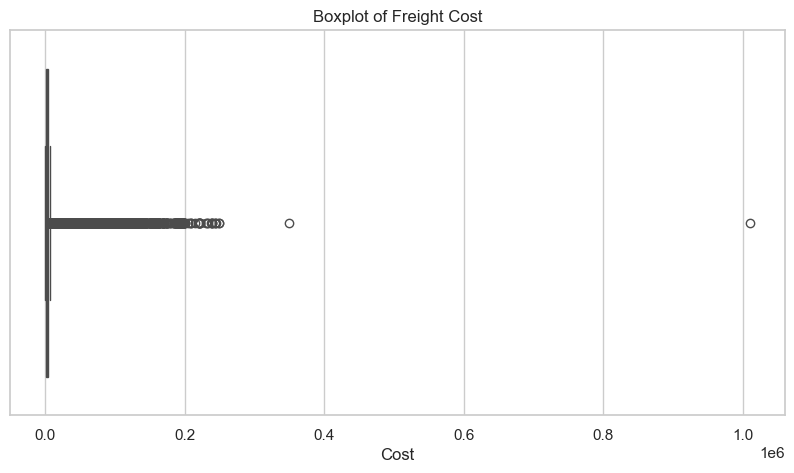

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,5))

sns.boxplot(x=df['Cost'])

plt.title("Boxplot of Freight Cost")

plt.show()

##### Observations

- The `Cost` feature exhibits a heavily right-skewed distribution with several extreme high-value observations.
- Most freight transactions are concentrated within lower cost ranges, while a limited number of shipments have exceptionally high transportation costs.
- The presence of numerous outliers suggests substantial variability in freight pricing across shipment types and transportation scenarios.
- These outliers may represent legitimate business cases such as long-haul transportation, high-capacity shipments, or premium logistics operations.
- Further outlier treatment and transformation strategies will be evaluated during the Data Preparation phase.

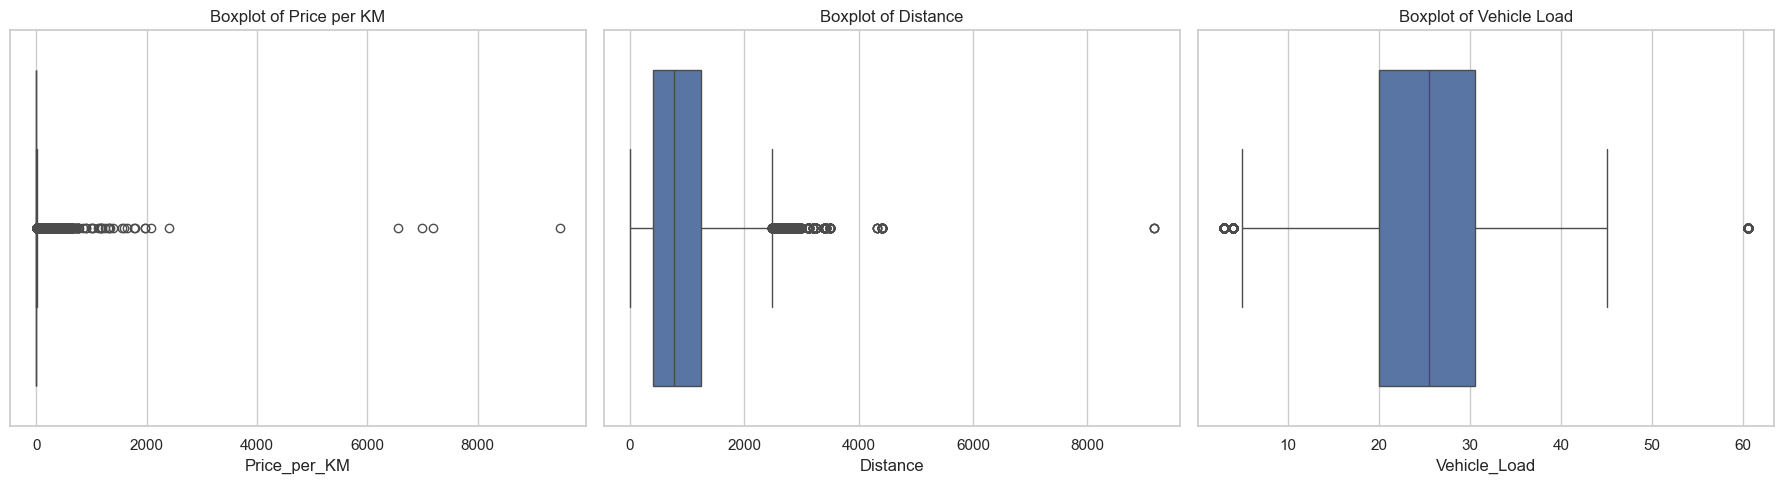

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(18,5))

sns.boxplot(x=df['Price_per_KM'], ax=axes[0])
axes[0].set_title("Boxplot of Price per KM")

sns.boxplot(x=df['Distance'], ax=axes[1])
axes[1].set_title("Boxplot of Distance")

sns.boxplot(x=df['Vehicle_Load'], ax=axes[2])
axes[2].set_title("Boxplot of Vehicle Load")

plt.tight_layout()
plt.show()

##### Observations

- `Price_per_KM` exhibits extreme right-skewness with several high-value outliers, indicating substantial variability in shipment pricing efficiency.
- `Distance` also contains long-tail outliers, representing very long-haul transportation routes.
- Compared to pricing-related variables, `Vehicle_Load` appears relatively stable with fewer extreme deviations.
- The majority of shipments are concentrated within moderate load ranges, suggesting operational consistency in freight capacity utilization.
- Outlier behavior in pricing-related features may reflect legitimate business scenarios such as premium logistics operations, specialized cargo movement, or exceptional route conditions.

#### 2.3.5 Out-of-date Data / Timeliness

In [38]:
df['Date'] = pd.to_datetime(df['Date'], errors='coerce', dayfirst=True)

# remove timezone if present
df['Date'] = df['Date'].dt.tz_localize(None)

df_sorted = df.sort_values("Date")

start = df_sorted['Date'].min()
end   = df_sorted['Date'].max()

days = (end - start).days

print(f"Data period: {start.date()} → {end.date()} ({days} days)")

# Check for missing dates (daily gaps)
expected_days = pd.date_range(start, end, freq='D').size
actual_days   = df_sorted['Date'].nunique()

print(f"Expected unique dates : {expected_days}")
print(f"Actual unique dates   : {actual_days}")

if expected_days == actual_days:
    print("✅ No missing days.")
else:
    print(f"⚠️  Missing {expected_days - actual_days} day(s) — may be weekends/holidays or data gaps.")

Data period: 2022-01-01 → 2025-12-31 (1460 days)
Expected unique dates : 1461
Actual unique dates   : 11704
⚠️  Missing -10243 day(s) — may be weekends/holidays or data gaps.


#### 2.3.6 Data Quality Report

In [39]:
data_quality_report = pd.DataFrame({
    "Issue": [
        "Datetime inconsistency",
        "Formatting inconsistencies",
        "Missing values",
        "Duplicate records",
        "Outliers"
    ],

    "Affected Columns": [
        "Date",
        "Source_State, Destination_State",
        "Vehicle_Load",
        "Entire dataset",
        "Cost, Price_per_KM, Distance"
    ],

    "Observation": [
        "Mixed timezone formats detected",
        "Inconsistent capitalization, spacing, abbreviations",
        "Vehicle_Load contains missing values",
        "1116 duplicate rows identified",
        "Extreme values detected in pricing and distance features"
    ],

    "Proposed Handling": [
        "Datetime standardization",
        "Category normalization",
        "Imputation/removal strategy",
        "Duplicate validation/removal",
        "Outlier treatment or transformation"
    ]
})

data_quality_report

,Issue,Affected Columns,Observation,Proposed Handling
0,Datetime inconsistency,Date,Mixed timezone formats detected,Datetime standardization
1,Formatting inconsistencies,"Source_State, Destination_State","Inconsistent capitalization, spacing, abbrevia...",Category normalization
2,Missing values,Vehicle_Load,Vehicle_Load contains missing values,Imputation/removal strategy
3,Duplicate records,Entire dataset,1116 duplicate rows identified,Duplicate validation/removal
4,Outliers,"Cost, Price_per_KM, Distance",Extreme values detected in pricing and distanc...,Outlier treatment or transformation


In [40]:
print("=" * 55)
print("DATA QUALITY REPORT – AWL Logistics Freight Dataset")
print("=" * 55)

print("\nMissing values:")
mv = df.isnull().sum()
mv = mv[mv > 0]
if len(mv):
    for col, cnt in mv.items():
        print(f"  {col:<30} {cnt}  ({cnt/len(df)*100:.1f}%)")
else:
    print("  No missing values found.")

print("\nOutliers:")
q1, q3 = df['Cost'].quantile(0.25), df['Cost'].quantile(0.75)
iqr    = q3 - q1
out    = df[(df['Cost'] < q1 - 1.5*iqr) | (df['Cost'] > q3 + 1.5*iqr)]
print(f"  Cost column: {len(out)} potential outliers detected (IQR method)")

print("\nNotes:")
print("  1. Cost is right-skewed (skew =", round(df['Cost'].skew(), 2),
      ") — log transformation recommended before modeling.")
print("  2. Zero-cost rows:", df[df['Cost']==0].shape[0],
      "— check if store was closed / data entry error.")
print("  3. corrected_vehicle_body — high % missing, handle in Data Preparation.")
print("  4. Contract type mix: LONG dominates (", df['Contract_type'].value_counts().to_dict(), ")")
print("=" * 55)

DATA QUALITY REPORT – AWL Logistics Freight Dataset

Missing values:
  Contract_type                  2  (0.0%)
  Destination_State              4  (0.0%)
  Vehicle_Type                   4  (0.0%)
  Vehicle_body_type              354  (0.1%)
  Pricing_Type                   18  (0.0%)
  Vehicle_Load                   27434  (6.5%)

Outliers:
  Cost column: 30666 potential outliers detected (IQR method)

Notes:
  1. Cost is right-skewed (skew = 6.09 ) — log transformation recommended before modeling.
  2. Zero-cost rows: 0 — check if store was closed / data entry error.
  3. corrected_vehicle_body — high % missing, handle in Data Preparation.
  4. Contract type mix: LONG dominates ( {'SHORT': 337844, 'LONG': 36904, 'MONTHLY': 32998, 'DAILY': 11330, 'SPOT': 4233} )


---
<a id="3-Data-Cleaning--Preparation"></a>
# <span style="color:#E65100;">3. Data Cleaning & Preparation</span>
> **CRISP-DM Phase 3 — Clean, correct, and standardize the dataset**

This section applies all cleaning transformations covering source city/state corrections, destination corrections, and vehicle type normalization.

<a id="3.1-Source-City--State-Cleaning"></a>
## <span style="color:#EF6C00;">3.1 Source City & State Cleaning</span>
> Corrects misspellings, abbreviations, noise values, and city-in-state-column errors for `Source` and `Source_State`. Outputs `Corrected_Source` and `Corrected_Source_State`.

In [41]:
import pandas as pd
import re

# Load the dataset
#file_path = r"C:\Users\HP\Desktop\HFU\SEM1\DS PROJECT\Transport_Market_Price.xlsx"
#df = pd.read_excel(file_path)

# ============================================================
# 1. VALID INDIAN STATES & UNION TERRITORIES (Official List)
# ============================================================
valid_states = {
    'Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar',
    'Chhattisgarh', 'Goa', 'Gujarat', 'Haryana',
    'Himachal Pradesh', 'Jharkhand', 'Karnataka', 'Kerala',
    'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya',
    'Mizoram', 'Nagaland', 'Odisha', 'Punjab',
    'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana',
    'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal',
    # Union Territories
    'Andaman And Nicobar Islands', 'Chandigarh',
    'Dadra And Nagar Haveli And Daman And Diu',
    'Delhi', 'Jammu And Kashmir', 'Ladakh',
    'Lakshadweep', 'Puducherry'
}

# ============================================================
# 2. STATE NAME CORRECTIONS (Misspellings / Abbreviations)
# ============================================================
state_corrections = {
    # Uttar Pradesh variants
    'Up': 'Uttar Pradesh',
    'U.P.': 'Uttar Pradesh',
    'U.P': 'Uttar Pradesh',
    'Utter Pardesh': 'Uttar Pradesh',
    'Uttarpradesh': 'Uttar Pradesh',
    'Uttar Prades': 'Uttar Pradesh',

    # Madhya Pradesh variants
    'Mp': 'Madhya Pradesh',
    'M.P': 'Madhya Pradesh',
    'M.P.': 'Madhya Pradesh',
    'Madhyapradesh': 'Madhya Pradesh',
    'Madhypradesh': 'Madhya Pradesh',
    'Madhayapradesh': 'Madhya Pradesh',
    'Madhy Pradesh': 'Madhya Pradesh',
    'Madhya Pradesh,': 'Madhya Pradesh',

    # Maharashtra variants
    'Maharastra': 'Maharashtra',
    'Maharsthra': 'Maharashtra',
    'Mahrastra': 'Maharashtra',
    'Maha': 'Maharashtra',
    'Mh': 'Maharashtra',

    # Tamil Nadu variants
    'Tamilnadu': 'Tamil Nadu',
    'Tn': 'Tamil Nadu',

    # Telangana variants
    'Telengana': 'Telangana',

    # Andhra Pradesh variants
    'Andhrapradesh': 'Andhra Pradesh',
    'Ap': 'Andhra Pradesh',

    # Gujarat variants
    'Gujrat': 'Gujarat',

    # Rajasthan variants
    'Rajsthan': 'Rajasthan',
    'Raasthan': 'Rajasthan',

    # Chhattisgarh variants
    'Chattisgarh': 'Chhattisgarh',
    'Chhatisgarh': 'Chhattisgarh',
    'Chhatishgarh': 'Chhattisgarh',

    # Karnataka variants
    'Ka': 'Karnataka',
    'Karnatka': 'Karnataka',

    # Uttarakhand variants
    'Uttarkhand': 'Uttarakhand',

    # Himachal Pradesh variants
    'Hp': 'Himachal Pradesh',

    # Jammu & Kashmir variants
    'J&K': 'Jammu And Kashmir',
    'J\u0026K': 'Jammu And Kashmir',
    'Jammu & Kashmir': 'Jammu And Kashmir',
    'Jammu & Kashimir': 'Jammu And Kashmir',
    'Jammu & Kasmir': 'Jammu And Kashmir',

    # Hindi script
    '\u0939\u0930\u093f\u092f\u093e\u0923\u093e': 'Haryana',   # हरियाणा
}

# ============================================================
# 3. CITY-TO-STATE MAPPING (cities found in Source_State column)
#    Verified online for correct state assignment
# ============================================================
city_to_state = {
    # --- Uttar Pradesh cities ---
    'Ghaziabad': 'Uttar Pradesh',
    'Ghaziabad Jb': 'Uttar Pradesh',
    'Chandauli': 'Uttar Pradesh',
    'Gajraula': 'Uttar Pradesh',
    'Khatauli': 'Uttar Pradesh',
    'Pilkhuwa': 'Uttar Pradesh',
    'Bahraich': 'Uttar Pradesh',
    'Prayagraj': 'Uttar Pradesh',
    'Mathura': 'Uttar Pradesh',
    'Kanpur': 'Uttar Pradesh',
    'Lucknow': 'Uttar Pradesh',
    'Banda': 'Uttar Pradesh',

    # --- Gujarat cities ---
    'Bardoli': 'Gujarat',
    'Hazira': 'Gujarat',
    'Surat': 'Gujarat',
    'Gandhidham': 'Gujarat',
    'Kadi': 'Gujarat',
    'Kadi+ Kadi': 'Gujarat',
    'Umbergaon': 'Gujarat',
    'Umbergoan': 'Gujarat',
    'Savli': 'Gujarat',
    'Vadodara': 'Gujarat',
    'Rajkot': 'Gujarat',
    'Padra': 'Gujarat',
    'Amreli': 'Gujarat',
    'Ahmedabad': 'Gujarat',

    # --- Maharashtra cities ---
    'Khopoli': 'Maharashtra',
    'Navi Mumbai': 'Maharashtra',
    'Mangaon': 'Maharashtra',
    'Baramati': 'Maharashtra',
    'Shirur': 'Maharashtra',
    'Mantha': 'Maharashtra',
    'Pune': 'Maharashtra',
    'Nagpur': 'Maharashtra',
    'Nagpur+Nagpur': 'Maharashtra',
    'Nagpur+Chandarpur': 'Maharashtra',
    'Nagpur+Gondia': 'Maharashtra',
    'Kolhapur': 'Maharashtra',
    'Kolhapur+Sawantwadi': 'Maharashtra',
    'Sativali': 'Maharashtra',
    'Sativli': 'Maharashtra',
    'Bhiwandi': 'Maharashtra',
    'Bhiwandi+Bhiwandi': 'Maharashtra',
    'Thane': 'Maharashtra',
    'Jalgaon': 'Maharashtra',
    'Jalna': 'Maharashtra',
    'Nallasopara': 'Maharashtra',
    'Satana': 'Maharashtra',
    'Nanded': 'Maharashtra',
    'Akola': 'Maharashtra',
    'Sawantwadi': 'Maharashtra',
    'Parnhani': 'Maharashtra',
    'Kudal': 'Maharashtra',
    'Narayagaon': 'Maharashtra',
    'Poynad': 'Maharashtra',
    'Buldana': 'Maharashtra',
    'Buldhana': 'Maharashtra',
    'Sangli': 'Maharashtra',
    'Vasai': 'Maharashtra',
    'Dharavi': 'Maharashtra',
    'Vashi': 'Maharashtra',
    'Andheri': 'Maharashtra',
    'Mahad': 'Maharashtra',
    'Pimpalgaon': 'Maharashtra',
    'Udgir': 'Maharashtra',
    'Gondiya': 'Maharashtra',
    'Bhusawal': 'Maharashtra',
    'Nashik': 'Maharashtra',
    'Nashik+ Nashik': 'Maharashtra',
    'Ahmadnagar': 'Maharashtra',
    'Pimpri Chinchwad + Pune': 'Maharashtra',
    'Akkalkuwa': 'Maharashtra',
    'Aurangabad': 'Maharashtra',
    'Mumbai Maharashtra': 'Maharashtra',
    'Bhopal': 'Madhya Pradesh',

    # --- Haryana cities ---
    'Rai': 'Haryana',
    'Karnal': 'Haryana',
    'Gohana': 'Haryana',
    'Gharunda': 'Haryana',
    'Pataudi': 'Haryana',
    'Jhajjar': 'Haryana',
    'Rohtak': 'Haryana',
    'Gurgaon': 'Haryana',
    'Bhiwani': 'Haryana',
    'Panchkula': 'Haryana',
    'Rewari': 'Haryana',
    'Ballabhgarh': 'Haryana',
    'Narnaul': 'Haryana',
    'Hisar': 'Haryana',

    # --- Punjab cities ---
    'Kheri Gurana': 'Punjab',
    'Patiala': 'Punjab',

    # --- Tamil Nadu cities ---
    'Chennai': 'Tamil Nadu',
    'Chennai+Chennai': 'Tamil Nadu',
    'Coimbatore': 'Tamil Nadu',
    'Madurai': 'Tamil Nadu',
    'Thanjavur': 'Tamil Nadu',

    # --- Telangana cities ---
    'Hyderabad': 'Telangana',
    'Patancheru': 'Telangana',

    # --- Rajasthan cities ---
    'Barmer': 'Rajasthan',
    'Khairthal': 'Rajasthan',

    # --- West Bengal cities ---
    'Kolkata': 'West Bengal',
    'Raniganj': 'West Bengal',
    'New Barrackpur': 'West Bengal',

    # --- Chhattisgarh cities ---
    'Bilaspur': 'Chhattisgarh',
    'Bilashpur': 'Chhattisgarh',
    'Raipur': 'Chhattisgarh',
    'Korba': 'Chhattisgarh',
    'Raigarh': 'Chhattisgarh',

    # --- Madhya Pradesh cities ---
    'Nimrani': 'Madhya Pradesh',
    'Jabalpur': 'Madhya Pradesh',
    'Satna': 'Madhya Pradesh',

    # --- Odisha cities ---
    'Barpali': 'Odisha',
    'Cuttack': 'Odisha',

    # --- Karnataka cities ---
    'Banglore': 'Karnataka',
    'Hubli': 'Karnataka',
    'Chitradurga + Shimoga': 'Karnataka',

    # --- Goa cities ---
    'Ponda': 'Goa',
    'Ponda Goa': 'Goa',
    'Ponda Goa (Depot+ Cd)': 'Goa',

    # --- Uttarakhand cities ---
    'Haridwar': 'Uttarakhand',
    'Haridwar Uttrakhand': 'Uttarakhand',
    'Pantnagar': 'Uttarakhand',
    'Haldwani': 'Uttarakhand',
    'Ponta Sahib': 'Himachal Pradesh',

    # --- Kerala cities ---
    'Cochin': 'Kerala',

    # --- Andhra Pradesh cities ---
    'Punganur': 'Andhra Pradesh',

    # --- Bihar cities ---
    'Samastipur, Bihar, India': 'Bihar',
    'Muzaffarpur, Bihar, India': 'Bihar',

    # --- Jharkhand cities ---
    'Dhanbad, Bihar, India': 'Jharkhand',
    'Gua': 'Jharkhand',

    # --- Composite / Address-style entries ---
    'Lucknow, Uttar Pradesh, India': 'Uttar Pradesh',

    # --- Small / ambiguous places (best guess from context) ---
    'Patli': 'Haryana',
    'Khumari': 'Chhattisgarh',
    'Rupra Road': 'Haryana',
}

# ============================================================
# 4. NOISE VALUES (not a state or city - should be blank)
# ============================================================
noise_values = {
    'Nan', ']', 'Metric Tonnes (Mt)', 'Party', 'Unknown', 'None', ''
}

# ============================================================
# 5. SOURCE (CITY) NAME CLEANING
# ============================================================

# 5a. Suffixes/prefixes to strip from city names (transport/railway jargon)
suffix_patterns = [
    r'\s+Rake\s+Yard$',   # e.g. "Ujhani Rake Yard" → "Ujhani"
    r'\s+Yard$',           # e.g. "Fatuha Yard" → "Fatuha"
    r'\s+Jb$',             # e.g. "Ghaziabad Jb" → "Ghaziabad" (Junction Booking)
    r'\s*\(Jb\)$',         # e.g. "Ghaziabad (Jb)" → "Ghaziabad"
]
prefix_patterns = [
    r'^Rsd\s+',            # e.g. "Rsd Raipur Yard" → "Raipur Yard" (then Yard stripped)
    r'^Ncmsl\s+Warehouse\s+',  # e.g. "Ncmsl Warehouse Raichur" → "Raichur"
]

# 5b. City spelling corrections (verified online)
city_spelling_corrections = {
    # Misspellings
    'Varansi': 'Varanasi',
    'Athni': 'Athani',
    'Bilashpur': 'Bilaspur',
    'Gharaunda': 'Gharaunda',  # correct as-is but normalizing from Source_State

    # Standardize to official city names
    'Mangalore': 'Mangaluru',          # Official name since 2014
    'Bangalore': 'Bengaluru',          # Official name since 2006
    'Banglore': 'Bengaluru',
    'Calcutta': 'Kolkata',
    'Bombay': 'Mumbai',
    'Madras': 'Chennai',
    'Cochin': 'Kochi',

    # Standardize Sri Ganganagar variants
    'Sriganganagar': 'Sri Ganganagar',

    # Tarn Taran variants
    'Taran Taran': 'Tarn Taran',

    # Handle number suffix
    'Kolkata-1': 'Kolkata',

    # Noise entries → extract actual city
    'Shriya Rice Mills': 'Raichur',    # Located in Raichur, Karnataka
    'Nrpa Yard': 'Narayanpur Anant',   # NRPA = Narayanpur Anant station, Bihar

    # Dahisar Mori is a locality in Navi Mumbai region
    'Dahisar Mori': 'Dahisar',

    # Hindon City is an area in Ghaziabad
    'Hindon City': 'Ghaziabad',

    # Meda Adraj is a village in Kadi taluka, Gujarat
    'Meda Adraj': 'Meda Adraj',        # Keep as-is (valid village name)

    # Delhi Kishanganj → Kishanganj (Kishanganj is the city, Delhi is the state)
    'Delhi Kishanganj': 'Kishanganj',

    # Lakhimpur Kheri → Lakhimpur (Lakhimpur is the city, merge with existing Lakhimpur)
    'Lakhimpur Kheri': 'Lakhimpur',
}

# 5c. Source noise values (not valid city names)
source_noise = {
    'Nan', 'None', '', 'Unknown', 'Party',
    'Metric Tonnes (Mt)', ']',
    'Delhi',  # Delhi is a state/UT, not a city name - remove from Source
}

# ============================================================
# 6. CLEANING FUNCTIONS
# ============================================================
def clean_source_city(val):
    """
    Comprehensive Source (city name) cleaning:
    1. Remove noise values
    2. Handle redundant names (Chennai + Chennai → Chennai)
    3. Strip transport suffixes (Yard, Jb, Rake Yard, Rsd)
    4. Fix city spelling mistakes
    5. Standardize to official city names
    """
    if pd.isna(val):
        return val

    val = str(val).strip().title()

    # Check if it's a noise value
    if val in source_noise:
        return ''

    # Handle redundant names: "Chennai + Chennai" → "Chennai"
    for sep in ['+', '/', '&']:
        if sep in val:
            parts = [p.strip() for p in val.split(sep)]
            if len(set(parts)) == 1:
                val = parts[0]
                break

    # Strip prefix patterns (Rsd, Ncmsl Warehouse)
    for pattern in prefix_patterns:
        val = re.sub(pattern, '', val, flags=re.IGNORECASE).strip()

    # Strip suffix patterns (Yard, Jb, Rake Yard)
    for pattern in suffix_patterns:
        val = re.sub(pattern, '', val, flags=re.IGNORECASE).strip()

    # Apply spelling corrections
    if val in city_spelling_corrections:
        val = city_spelling_corrections[val]

    return val


def clean_source_state(val):
    """
    Comprehensive Source_State cleaning:
    1. Remove noise values
    2. Fix state misspellings/abbreviations
    3. Replace city names with their correct state
    4. Handle address-style entries like 'City, State, India'
    """
    if pd.isna(val):
        return val

    val = str(val).strip().title()

    # Check if it's a noise value
    if val in noise_values:
        return ''

    # Check state corrections first (misspellings/abbreviations)
    if val in state_corrections:
        return state_corrections[val]

    # Check if already a valid state
    if val in valid_states:
        return val

    # Check city-to-state mapping
    if val in city_to_state:
        return city_to_state[val]

    # Handle address-style: "City, State, India" or "City, State"
    if ',' in val:
        parts = [p.strip() for p in val.split(',')]
        for part in parts:
            if part in valid_states:
                return part
            if part in state_corrections:
                return state_corrections[part]

    # If nothing matched, return original (will be flagged in review)
    return val


def to_lowercase(val):
    """Converts a string value to lowercase."""
    if pd.isna(val):
        return val
    return str(val).strip().lower()

# ============================================================
# 7. APPLY CLEANING
# ============================================================
# Clean Source column (city names: strip suffixes, fix spelling, remove noise)
df['Corrected_Source'] = df['Source'].apply(clean_source_city).apply(to_lowercase)

# Clean Source_State column (main fix: city→state, misspellings, noise)
df['Corrected_Source_State'] = df['Source_State'].apply(clean_source_state).apply(to_lowercase)

# ============================================================
# 8. VALIDATION
# ============================================================

# --- Validate Source_State ---
valid_states_lower = {s.lower() for s in valid_states}
remaining_state_issues = df[
    (df['Corrected_Source_State'] != '') &
    (~df['Corrected_Source_State'].isin(valid_states_lower)) &
    (df['Corrected_Source_State'].notna())
]['Corrected_Source_State'].value_counts()

if len(remaining_state_issues) > 0:
    print("WARNING: These values in Corrected_Source_State are NOT valid states:")
    print(remaining_state_issues.to_string())
    print()
else:
    print("OK - All Corrected_Source_State values are valid Indian states!")
    print()

# --- Validate Source (show what changed) ---
print("=" * 60)
print("SOURCE (CITY) CLEANING SUMMARY")
print("=" * 60)
source_changed = df['Source'].astype(str).str.strip().str.lower() != df['Corrected_Source']
print(f"Total rows with Source city corrections: {source_changed.sum()}")
print()

# Show examples of Source corrections
if source_changed.any():
    examples = df[source_changed][['Source', 'Corrected_Source']].drop_duplicates()
    print(f"Unique corrections made ({len(examples)} types):")
    print(examples.to_string(index=False))
    print()

print("Corrected_Source unique values:")
print(df['Corrected_Source'].value_counts().to_string())

print()
print("=" * 60)
print("SOURCE_STATE CLEANING SUMMARY")
print("=" * 60)
state_changed = df['Source_State'].astype(str).str.strip().str.lower() != df['Corrected_Source_State']
print(f"Total rows with Source_State corrections: {state_changed.sum()}")
print()
print("Corrected_Source_State value counts:")
print(df['Corrected_Source_State'].value_counts().to_string())

# ============================================================
# 9. REORGANIZE COLUMNS (Original | Corrected side by side)
# ============================================================
cols = list(df.columns)
cols.remove('Corrected_Source')
cols.remove('Corrected_Source_State')

source_idx = cols.index('Source')
cols.insert(source_idx + 1, 'Corrected_Source')

state_idx = cols.index('Source_State')
cols.insert(state_idx + 1, 'Corrected_Source_State')

df = df[cols]

# ============================================================
# 10. EXPORT
# ============================================================
# output_file = r'Cleaned_Transport_source_data.xlsx'
# df.to_excel(output_file, index=False)

OK - All Corrected_Source_State values are valid Indian states!

SOURCE (CITY) CLEANING SUMMARY
Total rows with Source city corrections: 6001

Unique corrections made (59 types):
                 Source Corrected_Source
              Mangalore        mangaluru
                  Delhi                 
                  Athni           athani
                VARANSI         varanasi
              MANGALORE        mangaluru
                  DELHI                 
          Sriganganagar   sri ganganagar
          SRIGANGANAGAR   sri ganganagar
          SriGanganagar   sri ganganagar
           Bhimsen Yard          bhimsen
            Fatuha yard           fatuha
          Kuberpur Yard         kuberpur
        Chaukhandi Yard       chaukhandi
  Delhi Kishanganj Yard       kishanganj
        Lakhimpur Kheri        lakhimpur
              NRPA Yard             nrpa
          Bilaspur Yard         bilaspur
        RSD Raipur Yard           raipur
        LAKHIMPUR KHERI        lakhimpur
 

<a id="3.2-Destination-City-Cleaning"></a>
## <span style="color:#EF6C00;">3.2 Destination City Cleaning</span>
> Standardizes destination names using a comprehensive mapping dictionary.

In [42]:
df["Destination"] = df["Destination"].str.lower()
df["Destination_State"] = df["Destination_State"].str.lower()
df["Vehicle_body_type"] = df["Vehicle_body_type"].str.lower()


In [43]:
location_mapping = {"jalandhar cantt":"jalandhar","fatehgarh cantt":"fatehgarh","delhi cantt":"delhi","ramgarh cantonment":"ramgarh","agra cantt":"agra","patiala cantt":"patiala","meerut cantt":"meerut","mhow gaon":"mhowgaon","chandi mandir":"Panchkula","missamari":"misamari","suratgarh cantt":"suratgarh","firozpur cantt":"firozpur","nasirabad rj":"nasirabad","tibri cantt":"tibri","faizabad cantt":"faizabad","farrukhabad-cum-fatehgarh":"farrukhabad","bathinda cantt":"bathinda","srinagar jk":"srinagar","darjiling":"darjeeling","ambala cantt":"ambala","babina cantt":"babina","jammu":"jammu and kashmir","kirkee cantt":"kirkee","bathinda":"bhatinda","gopalpur od":"gopalpur","kanpur cantt":"kanpur","mhow":"mhowgaon","madhuban":"madhubani","yamunanagar":"yamuna nagar","gopalganj district":"gopalganj","sitamarhiÂ ":"sitamarhi","kalagachhia":"kala gachhia","mangalore":"mangaluru","hissar":"hisar","pindara bazar":"Varanasi","kalyan-dombivali":"kalyan","pindra bazar":"Varanasi","raniganj wb":"raniganj","khalilabadÂ ":"khalilabad","bangalore":"bengaluru","guskara":"guskhara","pachpakri bazar":"pachpakari bazar","burdwan":"bardhaman","baharampur":"berhampore","westmambalam":"west mambalam","begumbazar":"begum bazar","jagatsinghapur":"jagatsinghpur","bharatpur wb":"bharatpur","pali mh":"pali","sangli miraj kupwad":"sangli","greater noida":"noida","kolkata 2":"kolkata","gondiya":"gondia","maharajganj-raibareilly":"maharajganj","raipur rani":"raipur","gopalpur kothi":"gopalpur","kalyan-dombivli":"kalyan","ahmadnagar":"ahmednagar","bewar up":"bewar","aurangabad mh":"aurangabad","aurangabad wb":"aurangabad","sonapur hat":"sonapur","raipur cg":"raipur","kurushetra":"kurukshetra","bullabhgarh":"ballabhgarh","g noida":"noida","chatanpally":"chattanpally","anklesvar":"ankleshwar","maharajganj gorakhpur":"maharajganj","ramnagar uk":"ramnagar","parlakhemundi":"paralakhemundi","sullurpet":"sullurupeta","ganjdundwara":"ganj dundwara","brahmapur":"berhampore","palasa @ kasibugga":"palasa","akbarpur":"ahmednagar","sarai aghat":"sarai","lucknow party":"lucknow","delhi fatehpur beri":"delhi","surat mfs":"surat","desariÂ ":"desari","jhunjunu":"jhunjhunu","githani-nathnagar":"githani","bhatni bazar":"bhatni","fazilnagarÂ ":"fazilnagar","tamkuhi road":"tamkuhi","brahmpur":"brahmapur","andehri":"andheri","kolkotta":"kolkata","brajrajnagar":"brajarajnagar","k r pet":"krishnarajapete","jalgoan":"jalgaon","manauri dandi":"manauri","shobha bazar kolkata":"kolkata","kanpur-mkak gkak":"kanpur","ramganj":"ramganj mandi","sheikhpura district":"sheikhpura","yeshwanthpur":"bengaluru","barkagaonÂ ":"barkagaon","beawar rj":"beawar","sarai akil":"sarai","jaunpur district":"jaunpur","jangipur up":"jangipur","jamui district":"jamui","jagadhri":"jagadhari","barddhaman":"bardhaman","new delhi":"delhi","chilbilla":"chilbila","mahrajganj azamgarh":"mahrajganj","barod":"baroda","muzaffar nagar":"muzaffarnagar","madhubani district":"madhubani","sriganganagar":"sri ganganagar","raipur rj":"raipur","jaipur depot":"jaipur","jallandhar":"jalandhar","raebareliÂ ":"rae bareli","shahjahanpurÂ ":"shahjahanpur","fatehpur sikri":"fatehpur","aurangabad bihar":"aurangabad","biswan- sitapur":"biswan","jhunjhunun":"jhunjhunu","mehdawal-ftl":"mehdawal","manali tn":"manali","sohratgarh":"shohratgarh","pratapgarh city":"pratapgarh","bagahaÂ ":"bagaha","kolkata depot":"kolkata","nagriÂ ":"nagri","siddipet":"siipet","tiruvanamalai":"tiruvannamalai","raebareli":"rae bareli","allahabad party":"allahabad","hyderdabad":"hyderabad","solavaram":"sholavaram","aurai":"auraiya","khamanaon":"khamanon","kalabaria":"kalaberia","raurkela":"rourkela","simri dbg":"simri","gorakhpur mother wh":"gorakhpur","lucknow depot":"lucknow","puchari bazar":"puchhari bazar","patna city":"patna","barelly":"bareilly","badhni -small load":"badhni","south goa":"goa","rampur hp":"rampur","dadar":"dadra and nagar haveli","biraul-supaul bazar":"biraul","allahabad depot":"allahabad","padraunaÂ ":"padrauna","rourkela":"raurkela","mirganjÂ ":"mirganj","sarai aquil":"sarai","arariya":"araria","keotiranwe":"keoti","beawar":"bewar","kakinara":"kankinara","delhi nazafgarh":"delhi","bareilly depot":"bareilly","bahalgarh sonipat":"bahalgarh","siwan district":"siwan","sangli-miraj & kupwad":"sangli","doharighat":"dohrighat","bahraich district":"bahraich","shriya rice mills":"Raichur","raniganj br":"raniganj","jajpur road":"jajpur","raxaulÂ ":"raxaul","hosiarpur":"hoshiarpur","maharajganj- azamgarh":"maharajganj","gorakhpurÂ  mother wh":"gorakhpur","dighwa dubaulli":"dighwa dubauli","keoti ranwe":"keoti","bharatpur rj":"bharatpur","masjid bunder":"mumbai","firozpur cant.":"firozpur","aurangabad br":"aurangabad","ganpatganj - kishanpur road":"ganpatganj","gaya br":"gaya","chauparan":"chouparan","bilaspur up":"bilaspur","farukkhabad":"farrukhabad","kauakole":"kauakol","chhatarpur jh":"chhatarpur","anandnagar":"anand nagar","laheriasarai":"laheria sarai","bidhannagar":"bidhan nagar","dudhi":"duddhi","nasik":"nashik","puruliya":"purulia","ashoknagar kalyangarh":"ashoknagar","panagarh wb":"panagarh","haora":"howrah","berhampore wb":"berhampore","bhatpara wb":"bhatpara","simri baktiyarpur":"simri","hazaribag":"hazaribagh","jagai manjhauli":"jagai majhauli","jalore":"jalor","brahmapur od":"brahmapur","morvi":"morbi","kishangarh bas":"kishangarh","kushmundi":"kushmandi","jamuabazar":"jamua bazar","laherisarai":"laheria sarai","ajmer rupangarh":"ajmer","sarai mir":"sarai","nabarangapur":"nabarangpur","rupraroad":"rupra road","saiyadraja":"saiyad raja","govindpur":"gobindpur","padampur":"padmapur","barauni ioc township":"barauni","anugul":"angul","jajpur town":"jajpur","dombivali":"dombivli","burdhwan":"bardhaman","ferozepur cantt":"ferozepur","gosainganj":"gosaiganj","raxaul bazar":"raxaul","gumadera hanuman mandir":"gumadera","raniganj bihar":"raniganj","ranigunj":"raniganj","raipur bazar":"raipur","manendragarh":"mahendragarh","varanasi railway station":"varanasi","maharajganj up vns":"maharajganj","maharajganj up":"maharajganj","tamakuhi raj":"tamkuhi","bhilai nagar":"bhilai","chhatarpur mp":"chhatarpur","maharajganj bihar":"maharajganj","sonarpur":"sonapur","saharghat br":"saharghat","tajpur br":"tajpur","ramgarh br":"ramgarh","gumadera post office":"gumadera","ganj dundawara":"ganj dundwara","berhampur od":"berhampur","raniganj uttar pradesh":"raniganj","jhumri tilaiya":"jhumri telaiya","rampur up":"rampur","nagar untari":"nagarutari","barilly":"bareilly","raniganj west bengal":"raniganj","dumdum":"dum dum","krishnanagar sagar":"krishnanagar","icahpur":"ichapur","kolkata 1":"kolkata","hugli-chinsurah":"hugli","sitapur up":"sitapur","kolkata party":"kolkata","ranigunj uttar pradesh":"raniganj","ashok nagar":"ashoknagar","bit college":"kolkata","vijapur":"vijayapura","ramnagar up":"ramnagar","chhatarpur (jh)":"chhatarpur","dhakiya":"dhakia","manjlegaon":"majalgaon","chandrapur mh":"chandrapur","patan gj":"patan","patan mh":"patan","majalgaon":"manjlegaon","chitrakoot dham":"chitrakoot","akkalkuva":"akkalkuwa","kankaria yard":"kankaria","deglur":"degloor","sangli miraj":"sangli","deharadun":"dehradun","gondia mh":"gondia","chandrapur up":"chandrapur","masjid mumbai":"mumbai","mandvi surat":"mandvi","mahesana":"mehsana","betwa river":"vidisha","varanashi":"varanasi","raman mandi":"raman","chikkathayappa reddy layout":"bengaluru","hsr layout":"bengaluru","j. p. nagar":"bengaluru","btm layout":"bengaluru","jc nagar":"bengaluru","athmavidya nagar":"bengaluru","basavanagudi":"bengaluru","cox town":"bengaluru","nelamangala":"bengaluru","bhadravathi karnataka":"bhadravathi","bagalakunte":"bengaluru","yeswanthpur":"bengaluru","doddaballapura":"doaballapura","bangaloreÂ  depot":"bengaluru","nelmangala":"bengaluru","st thomas town":"bengaluru","cv raman nagar":"bengaluru","chrompet":"chromepet","mangalore plant":"mangaluru","jp nagar":"bengaluru","basavannagudi":"bengaluru","tirupati depot":"tirupati","tiptur+turuvekere":"tiptur","hubli depot":"hubli","bangarpet":"bangarapet","itkhori":"itkori","puchri bazar road":"puchhari bazar","asnhara":"asnahara","buldana":"buldhana","keshiari":"keshiary","new guddadahalli":"guddadahalli","coxtown":"bengaluru","chamarajnagar":"chamarajanagar","sennerkuppam":"senneer kuppam","bhadravati mh":"bhadravathi","athini":"athani","davangere":"davanagere","fatehpur beri":"fatehpur","ram nagar":"ramnagar","ram nagar up":"ram nagar","radhanagri":"radhanagari","kasba tarale":"kasaba tarale","anderson street":"chennai","chattarpur":"chhatarpur","cotton street kolkata":"kolkata","cotton street":"kolkata","mehadipatnam":"mehdipatnam","kancheepuram":"kanchipuram","gaganpahad farms":"gaganpahad","begum bazaar":"begum bazar","palasa kasibugga":"palasa","athma vidya nagar":"bengaluru","bilai":"bilha","kaghaznagar":"kagaznagar","vrl - n t pet":"bengaluru","vishakhapatnam":"visakhapatnam","mansa gj":"mansa","vadodara mdm":"vadodara","coimbature":"coimbatore","surat city":"surat","kheda mdm":"kheda","amreli mdm":"amreli","botad mdm":"botad","mansa pb":"mansa","anand mdm":"anand","chhota udepur":"chhota udaipur","ahmedabad railway station":"ahmedabad","aravalli mdm":"aravalli","bhavnagar mdm":"bhavnagar","ahmedabad mdm":"ahmedabad","patan mdm":"patan","rajkot city":"rajkot","gandhinagar mdm":"gandhinagar","mahesana mdm":"mahesana","kolkota":"kolkata","jayapatna":"jaipatna","debgarh":"debagarh","godbhaga":"godabhaga","kalberia":"kalaberia","ichapuram":"ichchapuram","nowrangpur":"nabarangpur","katedan industrial area":"katedhan","kolkata railway station":"kolkata","una hp":"una","motiganj bazar":"motiganj market","goa velha":"goa","chatanpally road":"chattanpally","yelamanchili":"elamanchili","srungavarapu kota":"srungavarapukota","cherlapalli":"cherlapally","ghatkeser":"ghatkesar","addateegala":"aateegala","rai":"sonipat","nasirabad mh":"nasirabad","jetpur navagadh":"jetpur","baramula":"baramulla","jhajjar depot":"jhajjar","belgaum district":"belgaum","doddagubbi":"doagubbi","new tharagupet":"tharagupet","jayanagar":"bengaluru","chikkamagaluru":"chikmagalur","bhadravati":"bhadravathi","karaikkudi":"karaikudi","tirumakudal-narsipur":"tirumakudalu narasipura","kakinada port":"kakinada","c v raman nagar":"bengaluru","tirumakudal narsipur":"tirumakudalu narasipura","krishnarajanagar":"krishnarajanagara","kottur":"kotturu","thiruchirapalli":"tiruchirappalli","chennai central":"chennai","hukkeri":"hukeri","channarayapatne":"channarayapatna","krishnarajpet":"krishnarajpete","athni":"athani","shikarpur":"shikaripur","alipurdwar":"alipurduar","nalikul-hooghly":"nalikul","balrampur up":"balrampur","mirganj up":"mirganj","raniganj up":"raniganj","sherghati br":"sherghati","mirganj br":"mirganj","islampur wb":"islampur","biharsharif":"bihar sharif","contai-purba medinipur":"contai","balarampur wb":"balarampur","raigarh chhattisgarh":"raigarh","soyagaon":"soygaon","kalol panchmahal":"kalol","fatehpura":"fatepura","kishanpura hp":"kishanpura","mundra port":"mundra","gurgoan":"gurgaon","pali rj":"pali","anjoripal":"anjoripali","giddarbaha":"gidderbaha","dabra":"dadra and nagar haveli","silvassa - vapi road":"silvassa","sihore":"sehore","ghazaibad":"ghaziabad","himmatnagar":"himatnagar","channarayapattana":"channarayapatna","singheshwar":"singhesar","rajagangpur":"rajgangpur","chamoli gopeshwar":"chamoli","hubli-dharwad":"hubli","ajuwa":"ajuha","kasba br":"kasba","shirpur-warwade":"shirpur","yevla":"yeola","bahraich up":"bahraich","sikandrabad up":"sikandrabad","atrauli":"atraulia","bhangar raghunathpur":"bhangar","buxar district":"buxar","sahajanpur":"shahjahanpur","bikramganjÂ ":"bikramganj","auraiya district":"auraiya","saha ambala":"saha","gaya district":"gaya","varanasi depot":"varanasi","biswan - sitapur":"biswan","north lakhimpur":"lakhimpur","bathuabazar":"bathua bazar","chakarpur kanpur":"ankleshwar","sahibabadÂ ":"sahibabad","ramnagar br":"ramnagar","jaswant nagar - etawah":"jaswantnagar","supaul bazar":"supaul","pudukottai":"pudukkottai","moradabad depot":"moradabad","gorakhpur no entry small load":"gorakhpur","mehdawal-3mt":"mehdawal","lakhisarai district":"lakhisarai","barielly":"bareilly","delhi partyÂ ":"delhi","varanasi party":"varanasi","delhi mandoli":"delhi","etawahÂ ":"etawah","nazafgarh partyÂ ":"najafgarh","delhi-customer":"delhi","soharatgarh - 9 mt":"shohratgarh","muhammadabad gohna":"muhammadabad","delhi party":"delhi","meeraganj ald":"Meergunj","behman dewana":"behman diwana","hajipur br":"hajipur","ambala city":"ambala","jaipur party":"jaipur","desri":"desari","srinagar uk":"srinagar","badhni -ftl":"badhni","firozabad district":"firozabad","delhi kherakalan":"delhi","kolkatta":"kolkata","gorakhpur no entry ftl":"gorakhpur","barabanki district":"barabanki","saran district":"saran","ballabgharh":"ballabhgarh","maharajganj - azamgarh":"maharajganj","teghraÂ ":"teghra","pendra road":"pendra","jhansiÂ ":"jhansi","rupaidihaÂ ":"rupaidiha","bela- nanpur":"bela","khatkheri":"khatakheri","sabarkantha mdm":"sabarkantha","bharuch mdm":"bharuch","morva":"morva hadaf","surat mdm":"surat","valsad mdm":"valsad","gurgaon mfs":"gurgaon","sonipat mfs":"sonipat","noida mfs":"noida","delhi mfs":"delhi","nuh mfs":"","greater noida mfs":"noida","jhajjar mfs":"jhajjar","hapur mfs":"hapur","sahebganj br":"sahebganj","barkagagaon":"barkagaon","ahmedabad mfs":"ahmedabad","haridwar mfs":"haridwar","faridabad mfs":"faridabad","fatehgarh sahib":"fatehgarh","uska bazar":"uska","nihal singh wala":"nihal singhwala","siddapura udupi":"siddapura","south dinajpur":"dinajpur","jaithra":"jaithara","n t pet":"bengaluru","central delhi":"delhi","south west delhi":"delhi","south east delhi":"delhi","north west delhi":"delhi","north east delhi":"delhi","east delhi":"delhi","north delhi":"delhi","south delhi":"delhi","west delhi":"delhi","jagdishpur br":"jagdishpur","banmankhi bazar":"banmankhi","shahjahanpur rj":"shahjahanpur","malegaon bazar":"malegaon","bilaspur cg":"bilaspur","kishangarh alwar":"kishangarh","jhakharpara":"jhakharpar","lalapur br":"lalapur","lalapur up":"lalapur","bakhri bazar":"bakhri","sirhind-fatehgarh":"sirhind","hasanpura br":"hasanpura","pratapgarh rj":"pratapgarh","kudal mh":"kudal","sirhind -fategarh":"sirhind","domariaganj":"domariyaganj","maharajganj azamgarh":"maharajganj","gorakhpur depot":"gorakhpur"}

df["Corrected_Destination"] = (
    df["Destination"]
    .map(location_mapping)
    .fillna(df["Destination"])
)

<a id="3.3-Vehicle-Type--Body-Type-Cleaning"></a>
## <span style="color:#EF6C00;">3.3 Vehicle Type & Body Type Cleaning</span>
> Normalizes vehicle type strings, cleans body type labels, removes invalid entries.

In [44]:
df

,Date,Contract_type,Route_name,Source,Corrected_Source,Source_State,Corrected_Source_State,Destination,Destination_State,Distance,...,Cost,Price_per_KM,Vehicle_Load,Product,week,month,Month,Year,Financial_year,Corrected_Destination
0,2022-01-01 00:00:00.000,SHORT,HALDIA - CHHIBRAMAU,HALDIA,haldia,WEST BENGAL,west bengal,chhibramau,up,1243.000000,...,2890.0,2.539908,NaN,Edible Oil,0,1,January,2022,21-22,chhibramau
1,2022-01-01 00:00:00.000,SHORT,JAIPUR - BANGALORE,Jaipur,jaipur,Rajasthan,rajasthan,bangalore,karnataka,2016.000000,...,5910.0,3.176587,NaN,Edible Oil,0,1,January,2022,21-22,bengaluru
2,2022-01-01 00:00:00.000,SHORT,BUNDI - GORAKHPUR,BUNDI,bundi,Rajasthan,rajasthan,gorakhpur,uttar pradesh,1025.000000,...,3030.0,3.196341,NaN,Edible Oil,0,1,January,2022,21-22,gorakhpur
3,2022-01-01 00:00:00.000,SHORT,BUNDI - BARMER,BUNDI,bundi,Rajasthan,rajasthan,barmer,rajasthan,567.000000,...,1350.0,2.477588,NaN,Edible Oil,0,1,January,2022,21-22,barmer
4,2022-01-01 00:00:00.000,SHORT,HALDIA - SHAHJAHANPUR,HALDIA,haldia,WEST BENGAL,west bengal,shahjahanpur,up,1257.000000,...,3250.0,2.202962,NaN,Edible Oil,0,1,January,2022,21-22,shahjahanpur
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
423306,2025-12-31 10:14:48.994,SPOT,VIDISHA - REWARI,Vidisha,vidisha,Madhya Pradesh,madhya pradesh,rewari,haryana,724.000000,...,24960.0,34.711326,6.5,Nuggets,52,12,December,2025,25-26,rewari
423307,2025-12-31 10:37:22.395,SPOT,MANGALURU - TERDAL,Mangaluru,mangaluru,KARNATAKA,karnataka,terdal,karnataka,536.000000,...,1550.0,3.123134,25.5,Edible Oil,52,12,December,2025,25-26,terdal
423308,2025-12-31 10:50:37.710,DAILY,GOHANA - SURAT,GOHANA,gohana,Haryana,haryana,surat,gujarat,1246.666667,...,2610.0,2.335561,36.0,Edible Oil,52,12,December,2025,25-26,surat
423309,2025-12-31 11:10:07.172,DAILY,NEEMUCH - DELHI,NEEMUCH,neemuch,Madhya Pradesh,madhya pradesh,delhi,delhi,641.000000,...,2470.0,4.087754,42.5,Edible Oil,52,12,December,2025,25-26,delhi


In [ ]:

df['Vehicle_Type_Original'] = df['Vehicle_Type']


# -----------------------------
# STEP 2: Normalize text
# -----------------------------
df['Vehicle_Type'] = df['Vehicle_Type'].astype(str)
df['Vehicle_Type'] = df['Vehicle_Type'].str.upper().str.strip()

# Remove escape characters like \N
df['Vehicle_Type'] = df['Vehicle_Type'].str.replace(r'\\N', '', regex=True)

# -----------------------------
# STEP 3: Basic cleanup
# -----------------------------
# Remove brackets
df['Vehicle_Type'] = df['Vehicle_Type'].str.replace(r'[\(\)]', ' ', regex=True)

# Normalize spaces
df['Vehicle_Type'] = df['Vehicle_Type'].str.replace(r'\s+', ' ', regex=True).str.strip()

# -----------------------------
# STEP 4: Remove unwanted values
# -----------------------------
df.loc[df['Vehicle_Type'].str.contains('ANY MODE', na=False), 'Vehicle_Type'] = None
df.loc[df['Vehicle_Type'].str.contains('DEPOT', na=False), 'Vehicle_Type'] = None

df['Vehicle_Type'] = df['Vehicle_Type'].replace(['NAN', 'nan', ''], None)

# -----------------------------
# STEP 5: Fix formatting issues (CASE 1)
# -----------------------------

# 1. Add space between number and MT/FT
df['Vehicle_Type'] = df['Vehicle_Type'].str.replace(
    r'(\d)(MT|FT)', r'\1 \2', regex=True
)

# 2. Fix MT-FT pattern (NOT range)
df['Vehicle_Type'] = df['Vehicle_Type'].str.replace(
    r'MT\s*-\s*(\d+)\s*FT', r'MT \1 FT', regex=True
)

# 3. Remove WHEELER info (noise)
df['Vehicle_Type'] = df['Vehicle_Type'].str.replace(
    r'\d+\s*WHEELER', '', regex=True
)

df['Vehicle_Type'] = df['Vehicle_Type'].str.replace(
    r'\b(LONG|INCH|INCHES|MULTI COMPARTMENT|STANDARD HEIGHT|HEIGHT)\b',
    '',
    regex=True
)

df['Vehicle_Type'] = df['Vehicle_Type'].str.replace(
    r'\d+\s*INCH', '', regex=True
)

df['Vehicle_Type'] = df['Vehicle_Type'].str.replace(r'\s+', ' ', regex=True).str.strip()
# -----------------------------
# STEP 6: Fix typos
# -----------------------------
df['Vehicle_Type'] = df['Vehicle_Type'].str.replace(r'WHE[A-Z]*', 'WHEEL', regex=True)
df['Vehicle_Type'] = df['Vehicle_Type'].str.replace(r'TY[R|E]*', 'TYRE', regex=True)

# Normalize MT/FT again
df['Vehicle_Type'] = df['Vehicle_Type'].str.replace(r'MT+', 'MT', regex=True)
df['Vehicle_Type'] = df['Vehicle_Type'].str.replace(r'FT+', 'FT', regex=True)

# Remove tanker-specific noise
df['Vehicle_Type'] = df['Vehicle_Type'].str.replace(
    r'\b(MULTI COMPARTMENT|COMPARTMENT)\b',
    '',
    regex=True
)

# Final space cleanup
df['Vehicle_Type'] = df['Vehicle_Type'].str.replace(r'\s+', ' ', regex=True).str.strip()


df['Vehicle_Type'] = df['Vehicle_Type'].replace(['NAN', 'nan', ''], None)

def is_valid_vehicle(x):
    if pd.isna(x):
        return False

    # Check if it has at least MT or FT
    has_mt = re.search(r'\d+\.?\d*\s*MT', x)
    has_ft = re.search(r'\d+\s*FT', x)

    return bool(has_mt or has_ft)

df = df[df['Vehicle_Type'].apply(is_valid_vehicle)]

# -----------------------------
# STEP 7: Final extraction function
# -----------------------------
def clean_vehicle(x):
    if pd.isna(x):
        return None

    category = None
    mt = None
    ft = None
    tyre = None

    # -------- CATEGORY --------
    if 'EICHER' in x:
        category = 'EICHER'
    elif 'TAURUS' in x:
        category = 'TAURUS'
    elif 'HCV TRAILER' in x:
        category = 'HCV TRAILER'
    elif 'TRAILER' in x:
        category = 'TRAILER'
    elif 'MULTI AXLE CONTAINER' in x:
        category = 'MULTI AXLE CONTAINER'
    elif 'SINGLE AXLE CONTAINER' in x:
        category = 'SINGLE AXLE CONTAINER'
    elif 'REFER CONTAINER' in x:
        category = 'REFER CONTAINER'
    elif 'HCV RIGID TRUCK' in x:
        category = 'HCV RIGID TRUCK'
    elif 'BADA DOST' in x:
        category = 'BADA DOST'
    elif 'LIGHT TRUCKS' in x:
        category = 'LIGHT TRUCKS'
    elif 'MS TANKER' in x:
         category = 'MS Tanker'
    elif 'SS TANKER' in x:
         category = 'SS Tanker'

    elif 'VOLUMETRIC TRUCK' in x:
         category = 'VOLUMETRIC TRUCK'

    elif 'MS NORMAL' in x:
         category = 'MS NORMAL'

    elif 'SS INSULATED' in x:
         category = 'SS INSULATED'
    elif 'INTERMEDIATE TRUCKS' in x:
         category = 'INTERMAEDIATE TRUCKS'




    # -------- HANDLE MT (RANGE + SINGLE) --------
    if category:
        # Only for categorized vehicles → allow ranges
        range_mt = re.search(r'(\d+)\s*-\s*(\d+)\s*MT', x)
        if range_mt:
            mt = f"{range_mt.group(1)}-{range_mt.group(2)}"
        else:
            mt_match = re.search(r'(\d+\.?\d*)\s*MT', x)
            if mt_match:
                mt = mt_match.group(1)
    else:
        # No category → only pick simple MT (ignore range)
        mt_match = re.search(r'(\d+\.?\d*)\s*MT', x)
        if mt_match:
            mt = mt_match.group(1)


    # -------- HANDLE FT (RANGE + SINGLE) --------
    range_ft = re.search(r'(\d+)\s*-\s*(\d+)\s*FT', x)
    if range_ft:
        ft = f"{range_ft.group(1)}-{range_ft.group(2)}"
    else:
        ft_match = re.search(r'(\d+)\s*FT', x)
        if ft_match:
            ft = ft_match.group(1)

    # -------- EXTRACT TYRE --------
    tyre_match = re.search(r'(\d+)\s*TYRE', x)
    if tyre_match:
        tyre = tyre_match.group(1)

    # -------- BUILD OUTPUT --------
    parts = []

    if category:
        parts.append(category)

    if mt:
        parts.append(f"{mt} MT")

   # Include FT only if category exists
    if ft and category:
        parts.append(f"{ft} FT")

    if tyre:
        parts.append(f"{tyre} TYRE")

    return " ".join(parts) if parts else None

# -----------------------------
# STEP 8: Apply final cleaning
# -----------------------------
df['Corrected_vehicle_Type'] = df['Vehicle_Type'].apply(clean_vehicle)


# -----------------------------
# VEHICLE BODY TYPE
# -----------------------------


df['Corrected_vehicle_body_type'] = df['Vehicle_body_type'].astype(str)
df['Corrected_vehicle_body_type'] = df['Corrected_vehicle_body_type'].str.upper().str.strip()
df['Corrected_vehicle_body_type'] = df['Corrected_vehicle_body_type'].str.replace(r'\s+', ' ', regex=True)

df.loc[df['Corrected_vehicle_body_type'].str.contains(
    r'MT|TYRE|TRUCK|TAURUS|EICHER|FT', na=False
), 'Corrected_vehicle_body_type'] = None


body_mapping = {"DALAL BODY":"DALA BODY","DALA BODAY":"DALA BODY","DALA":"DALA BODY","DALA BODY / FULL BODY":"DALA BODY","DALAL BODY / FULL BODY":"DALA BODY","FULL PUNJABI BODY":"FULL PUNJAB BODY","FULL LOAD PUNJAB BODY":"FULL PUNJAB BODY","PUNJABI BODY":"FULL PUNJAB BODY","FULL PUNJA BODY":"FULL PUNJAB BODY","PUNJAB BODY":"FULL PUNJAB BODY","CONTAINERBODY":"CONTAINER BODY","CONTAINER BCOVERD BODY":"CONTAINER BODY","CONTAINER BOX":"CONTAINER BODY","CONTAINER":"CONTAINER BODY","CONTAIER BODY":"CONTAINER BODY","REEFER CONTAINER":"REEFER BODY","REFER CONTAINER":"REEFER BODY","REFFER CONTAINER":"REEFER BODY","REFEER CONTAINER":"REEFER BODY","REFER BODY":"REEFER BODY","REEFER BODY":"REEFER BODY","REFER UNIT":"REEFER BODY","SS TANKER":"TANKER","MS TANKER":"TANKER","TANKER BODY":"TANKER","HIGH CUBE UNIT":None,"PICKUP":None,"OTHERS":None,"ANY VEHICLE":None}


df['Corrected_vehicle_body_type'] = df['Corrected_vehicle_body_type'].replace(body_mapping)

df['Corrected_vehicle_body_type'] = df['Corrected_vehicle_body_type'].replace(['NAN', 'nan', ''], None)
#df = df.drop(columns=['corrected_vehicle_body'])




In [46]:
df.columns

Index(['Date', 'Contract_type', 'Route_name', 'Source', 'Corrected_Source',
       'Source_State', 'Corrected_Source_State', 'Destination',
       'Destination_State', 'Distance', 'Vehicle_Type', 'Vehicle_body_type',
       'Pricing_Type', 'Cost', 'Price_per_KM', 'Vehicle_Load', 'Product',
       'week', 'month', 'Month', 'Year', 'Financial_year',
       'Corrected_Destination', 'Vehicle_Type_Original',
       'Corrected_vehicle_Type', 'Corrected_vehicle_body_type'],
      dtype='object')

In [47]:
df.to_csv(r"C:\Users\HP\Downloads\until_clean_data_ss_vh.csv")

---
<a id="4-FreightIQ-Enrichment-Pipeline"></a>
# <span style="color:#6A1B9A;">4. FreightIQ Enrichment Pipeline</span>
> **This section documents the complete data cleaning pipeline for enriching the freight dataset with two new columns:**
> 1. `correcteted_destination_state` — the Indian state/UT for each destination city
> 2. `corrected_distance` — driving distance (km) for each source→destination pair

> **Destination state** and **pair distance** lookups are embedded as compact horizontal Python dictionaries (§4.2–4.6, §4.9).

### 🗺️Logistics Distance Calculator

```
┌──────────────────────────────────────────────────────────────────────────────────────┐
│  Phase A  – Resolve Corrected_Destination_State from Corrected_Destination city      │
│            LocationIQ forward (addressdetails) -> state                              │
│            Fallback: Photon forward -> state from props -> Photon reverse            │
└──────────────────────────────────────────────────────────────────────────────────────┘
                                      │
                                      ▼
┌───────────────────────────────────────────────────────────────┐
│   Phase B  – Forward geocode (city, state) -> lat/lon         │
│              LocationIQ -> Photon                             │
│                                                               │ 
└───────────────────────────────────────────────────────────────┘
                                      │
                                      ▼
┌──────────────────────────────────────────────────────────────────────────────────────┐
│  Phase C  – OSRM road distance from lat/lon pairs                                     │
│             Excel + CSV                                                               │
│                                                                                      │
└──────────────────────────────────────────────────────────────────────────────────────┘
```

<a id="4.1-Fixing Destination state and Distance"></a>
## <span style="color:#7B1FA2;">4.1 Fixing Destination state and Distance</span>
> Extracted all unique values from `corrected_destination` column.

> **Result:** 2999 unique destination city names from 416815 rows (8 rows had empty destinations).

In [ ]:
import os
import time
import warnings
from concurrent.futures import ThreadPoolExecutor, as_completed
from typing import Any, Optional, Tuple

import pandas as pd
import requests

warnings.filterwarnings("ignore")

# ─────────────────────────────────────────────────────────────
# CONFIG
# ─────────────────────────────────────────────────────────────
INPUT_FILE = df  # replace with your DataFrame or pd.read_excel("yourfile.xlsx")

LOCATIONIQ_KEY = os.environ.get("LOCATIONIQ_API_KEY",
                                "pk.36f42fe6e0ee0df64013689f556c7567")

LIQ_DELAY    = 0.25   # seconds between LocationIQ calls
PHOTON_DELAY = 0.50   # increased delay to be polite under parallelism

MAX_WORKERS  = 5      # parallel threads for geocoding

USER_AGENT = "AWL-LogisticsDist/2.0 (internal)"

LIQ_SEARCH     = "https://us1.locationiq.com/v1/search.php"
PHOTON_SEARCH  = "https://photon.komoot.io/api/"
OSRM_ROUTE     = "https://router.project-osrm.org/route/v1/driving/{coords}"

# ─────────────────────────────────────────────────────────────
# CANONICAL INDIA STATE NAMES
# ─────────────────────────────────────────────────────────────
CANONICAL: dict = {
    "andhra pradesh": "Andhra Pradesh",
    "arunachal pradesh": "Arunachal Pradesh",
    "assam": "Assam",
    "bihar": "Bihar",
    "chhattisgarh": "Chhattisgarh",
    "goa": "Goa",
    "gujarat": "Gujarat",
    "haryana": "Haryana",
    "himachal pradesh": "Himachal Pradesh",
    "jharkhand": "Jharkhand",
    "karnataka": "Karnataka",
    "kerala": "Kerala",
    "madhya pradesh": "Madhya Pradesh",
    "maharashtra": "Maharashtra",
    "manipur": "Manipur",
    "meghalaya": "Meghalaya",
    "mizoram": "Mizoram",
    "nagaland": "Nagaland",
    "odisha": "Odisha",
    "orissa": "Odisha",
    "punjab": "Punjab",
    "rajasthan": "Rajasthan",
    "sikkim": "Sikkim",
    "tamil nadu": "Tamil Nadu",
    "telangana": "Telangana",
    "tripura": "Tripura",
    "uttar pradesh": "Uttar Pradesh",
    "uttarakhand": "Uttarakhand",
    "uttaranchal": "Uttarakhand",
    "west bengal": "West Bengal",
    "delhi": "Delhi",
    "jammu and kashmir": "Jammu & Kashmir",
    "ladakh": "Ladakh",
    "chandigarh": "Chandigarh",
    "puducherry": "Puducherry",
    "pondicherry": "Puducherry",
    "andaman and nicobar islands": "Andaman & Nicobar Islands",
    "dadra and nagar haveli": "Dadra & Nagar Haveli",
    "daman and diu": "Daman & Diu",
    "lakshadweep": "Lakshadweep",
}

# ─────────────────────────────────────────────────────────────
# SESSION  (thread-safe: each thread uses its own session)
# ─────────────────────────────────────────────────────────────
import threading
_thread_local = threading.local()

def _get_session() -> requests.Session:
    if not hasattr(_thread_local, "session"):
        s = requests.Session()
        s.headers.update({"User-Agent": USER_AGENT})
        _thread_local.session = s
    return _thread_local.session
# ─────────────────────────────────────────────────────────────
# LOW-LEVEL HTTP
# ─────────────────────────────────────────────────────────────
def _get(url: str, params: dict, timeout: int = 20,
         max_429: int = 1) -> Optional[Any]:
    """
    GET with minimal 429 retry (max_429=1 by default — fail fast, 
    fall through to Photon instead of waiting 20+ seconds).
    """
    session = _get_session()
    for attempt in range(1, max_429 + 2):
        try:
            r = session.get(url, params=params, timeout=timeout)
            if r.status_code == 429:
                wait = max(int(r.headers.get("Retry-After", 0)), 2) * attempt
                print(f"    [429] {url.split('/')[2]} -> sleeping {wait}s "
                      f"(attempt {attempt}/{max_429})")
                time.sleep(wait)
                continue
            r.raise_for_status()
            return r.json()
        except requests.exceptions.Timeout:
            print(f"    [timeout] {url.split('/')[2]}")
            return None
        except requests.exceptions.RequestException as e:
            print(f"    [error] {url.split('/')[2]}: {e}")
            return None
    return None
# ─────────────────────────────────────────────────────────────
# STATE HELPERS
# ─────────────────────────────────────────────────────────────
def _canonicalize(raw: Optional[str]) -> Optional[str]:
    if not raw:
        return None
    key = raw.strip().lower()
    if key in CANONICAL:
        return CANONICAL[key]
    for k, v in CANONICAL.items():
        if k in key:
            return v
    return None

def _state_from_liq_hit(hit: dict) -> Optional[str]:
    addr = hit.get("address", {})
    for field in ("state", "region", "state_district", "county"):
        val = addr.get(field)
        canon = _canonicalize(val)
        if canon:
            return canon
    return None

def _state_from_photon_feat(feat: dict) -> Optional[str]:
    props = feat.get("properties", {})
    for field in ("state", "county"):
        val = props.get(field)
        canon = _canonicalize(val)
        if canon:
            return canon
    return None

def _is_india_liq(hit: dict) -> bool:
    addr = hit.get("address", {})
    return (addr.get("country_code", "").lower() == "in"
            or "india" in addr.get("country", "").lower())
# ─────────────────────────────────────────────────────────────
# LOCATIONIQ WRAPPERS
# ─────────────────────────────────────────────────────────────
def liq_forward(query: str) -> Optional[dict]:
    if not LOCATIONIQ_KEY:
        return None
    data = _get(LIQ_SEARCH, {
        "key": LOCATIONIQ_KEY,
        "q": query,
        "countrycodes": "in",
        "format": "json",
        "addressdetails": "1",
        "limit": "1",
    }, max_429=1)  # fail fast — don't waste time retrying
    if not data:
        return None
    hit = data[0] if isinstance(data, list) else data
    return hit if _is_india_liq(hit) else None

# ─────────────────────────────────────────────────────────────
# PHOTON WRAPPERS
# ─────────────────────────────────────────────────────────────
def photon_forward(query: str) -> Optional[dict]:
    data = _get(PHOTON_SEARCH, {"q": query, "limit": 5})
    if not data or not data.get("features"):
        return None
    for feat in data["features"]:
        if feat.get("properties", {}).get("country", "").lower() in ("india", "in"):
            return feat
    return data["features"][0]
    
# ─────────────────────────────────────────────────────────────
# HIGH-LEVEL: GET STATE — Photon-first (skip slow LIQ retries)
# ─────────────────────────────────────────────────────────────
def get_state(city: str) -> Optional[str]:
    """
    Resolve Indian state for a city.
    Strategy: Go straight to Photon (free, no rate limits).
    Only try LocationIQ as a quick first attempt if the key is valid.
    """
    city = str(city).strip()

    # ── Quick LIQ attempt (max_429=1, fail fast) ──────────
    hit = liq_forward(f"{city}, India")
    time.sleep(LIQ_DELAY)
    if hit:
        state = _state_from_liq_hit(hit)
        if state:
            return state

    # ── Photon forward (primary workhorse) ────────────────
    feat = photon_forward(f"{city}, India")
    time.sleep(PHOTON_DELAY)
    if feat:
        state = _state_from_photon_feat(feat)
        if state:
            return state

    print(f"    [state?] could not resolve state for: {city!r}")
    return None
    
# ────────────────────────────────────────────────────────────
# HIGH-LEVEL: GET COORDINATES
# ─────────────────────────────────────────────────────────────
def get_coords(city: str, state: Optional[str] = None) -> Optional[Tuple[float, float]]:
    """
    Forward geocode city (+state) -> (lat, lon).
    1. LocationIQ (quick, fail fast)
    2. Photon fallback
    """
    city  = str(city).strip()
    state = str(state).strip() if state and not pd.isna(state) else ""

    queries = ([f"{city}, {state}, India", f"{city}, India"]
               if state else [f"{city}, India"])

    # ── LocationIQ (quick attempt) ────────────────────────
    for q in queries:
        hit = liq_forward(q)
        time.sleep(LIQ_DELAY)
        if hit:
            try:
                return (float(hit["lat"]), float(hit["lon"]))
            except (KeyError, ValueError):
                pass

    # ── Photon fallback ───────────────────────────────────
    for q in queries:
        feat = photon_forward(q)
        time.sleep(PHOTON_DELAY)
        if feat:
            try:
                lon, lat = feat["geometry"]["coordinates"]
                return (float(lat), float(lon))
            except (KeyError, TypeError):
                pass

    print(f"    [coords?] could not geocode: {city!r} / {state!r}")
    return None

# ─────────────────────────────────────────────────────────────
# OSRM ROAD DISTANCE
# ─────────────────────────────────────────────────────────────
def osrm_distance(lat1: float, lon1: float,
                  lat2: float, lon2: float) -> Optional[float]:
    coords = f"{lon1},{lat1};{lon2},{lat2}"
    data = _get(OSRM_ROUTE.format(coords=coords),
                {"overview": "false", "alternatives": "false", "steps": "false"},
                timeout=20)
    if data and data.get("code") == "Ok" and data.get("routes"):
        return round(data["routes"][0]["distance"] / 1000, 2)
    return None

# ─────────────────────────────────────────────────────────────
# PARALLEL HELPERS
# ─────────────────────────────────────────────────────────────
def _resolve_states_parallel(unique_cities: list) -> dict:
    """Resolve states for all unique cities in parallel."""
    cache = {}
    total = len(unique_cities)
    completed = [0]
    lock = threading.Lock()

    def _task(city):
        state = get_state(city)
        with lock:
            completed[0] += 1
            print(f"  [{completed[0]}/{total}] {city} -> {state}")
        return city, state

    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
        futures = {executor.submit(_task, city): city for city in unique_cities}
        for future in as_completed(futures):
            city, state = future.result()
            cache[city] = state

    return cache

def _geocode_pairs_parallel(pairs: list) -> dict:
    """Geocode (city, state) pairs in parallel."""
    unique = list({(str(c).strip(),
                    str(s).strip() if s and not pd.isna(s) else "")
                   for c, s in pairs})
    cache = {}
    total = len(unique)
    completed = [0]
    lock = threading.Lock()

    def _task(city, state):
        coords = get_coords(city, state or None)
        with lock:
            completed[0] += 1
            if completed[0] % 50 == 0:
                print(f"  ... {completed[0]}/{total} geocoded")
        return (city, state), coords

    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
        futures = {executor.submit(_task, city, state): (city, state)
                   for city, state in unique}
        for future in as_completed(futures):
            key, coords = future.result()
            cache[key] = coords

    return cache
    
# ─────────────────────────────────────────────────────────────
# MAIN PIPELINE
# ─────────────────────────────────────────────────────────────
def run():

    # ── Load ─────────────────────────────────────────────────
    df = INPUT_FILE
    print(f"  {len(df)} records | columns: {df.columns.tolist()}\n")

    required = {"Corrected_Source", "Corrected_Source_State", "Corrected_Destination"}
    missing  = required - set(df.columns)
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    for col in ("Corrected_Destination_State",
                "Source_Latitude", "Source_Longitude",
                "Destination_Latitude", "Destination_Longitude",
                "Corrected_Distance",
                "Distance_Difference_km", "Distance_Difference_Pct"):
        if col not in df.columns:
            df[col] = None

    # ════════════════════════════════════════════════════════
    # PHASE A  –  Destination State  (PARALLEL)
    # ════════════════════════════════════════════════════════
    print("=" * 62)
    print("PHASE A – Resolving Destination States (parallel)")
    print("=" * 62)

    unique_dests = [str(d).strip()
                    for d in df["Corrected_Destination"].dropna().unique()]

    dest_state_cache = _resolve_states_parallel(unique_dests)

    df["Corrected_Destination_State"] = (
        df["Corrected_Destination"].astype(str).str.strip().map(dest_state_cache)
    )
    ok_states = df["Corrected_Destination_State"].notna().sum()
    print(f"\n  Resolved {ok_states}/{len(df)} destination states\n")

    # ════════════════════════════════════════════════════════
    # PHASE B  –  Forward Geocode  (PARALLEL)
    # ════════════════════════════════════════════════════════
    print("=" * 62)
    print("PHASE B – Geocoding Sources & Destinations (parallel)")
    print("=" * 62)

    src_pairs  = (df[["Corrected_Source", "Corrected_Source_State"]]
                  .dropna(subset=["Corrected_Source"]).values.tolist())
    dest_pairs = (df[["Corrected_Destination", "Corrected_Destination_State"]]
                  .dropna(subset=["Corrected_Destination"]).values.tolist())

    all_pairs = src_pairs + dest_pairs
    print(f"\n  Geocoding {len(set(map(tuple, all_pairs)))} unique city/state pairs...")
    coord_cache = _geocode_pairs_parallel(all_pairs)

    # ════════════════════════════════════════════════════════
    # PHASE C  –  OSRM Distances
    # ════════════════════════════════════════════════════════
    print("\n" + "=" * 62)
    print("PHASE C – Calculating OSRM Road Distances")
    print("=" * 62)

    for idx, row in df.iterrows():
        src_city  = str(row["Corrected_Source"]).strip()
        src_state = str(row.get("Corrected_Source_State", "") or "").strip()
        dst_city  = str(row["Corrected_Destination"]).strip()
        dst_state = str(row.get("Corrected_Destination_State", "") or "").strip()

        src_coords  = coord_cache.get((src_city, src_state))
        dest_coords = coord_cache.get((dst_city, dst_state))

        if src_coords:
            df.at[idx, "Source_Latitude"]  = src_coords[0]
            df.at[idx, "Source_Longitude"] = src_coords[1]

        if dest_coords:
            df.at[idx, "Destination_Latitude"]  = dest_coords[0]
            df.at[idx, "Destination_Longitude"] = dest_coords[1]

        if src_coords and dest_coords:
            dist = osrm_distance(*src_coords, *dest_coords)
            df.at[idx, "Corrected_Distance"] = dist

            orig = row.get("Distance")
            if dist and orig and not pd.isna(orig):
                orig = float(orig)
                if orig > 0:
                    diff = abs(dist - orig)
                    df.at[idx, "Distance_Difference_km"]  = round(diff, 2)
                    df.at[idx, "Distance_Difference_Pct"] = round(diff / orig * 100, 1)

        if (idx + 1) % 100 == 0:
            print(f"  ... {idx + 1}/{len(df)} rows done")

    # ════════════════════════════════════════════════════════
    # SUMMARY
    # ════════════════════════════════════════════════════════
    n = len(df)
    ok_src  = df["Source_Latitude"].notna().sum()
    ok_dst  = df["Destination_Latitude"].notna().sum()
    ok_dist = df["Corrected_Distance"].notna().sum()

    print("\n" + "=" * 62)
    print("SUMMARY")
    print("=" * 62)
    print(f"  Total records              : {n}")
    print(f"  Destination states found   : {ok_states} ({ok_states/n*100:.1f}%)")
    print(f"  Sources geocoded           : {ok_src}  ({ok_src/n*100:.1f}%)")
    print(f"  Destinations geocoded      : {ok_dst}  ({ok_dst/n*100:.1f}%)")
    print(f"  OSRM distances computed    : {ok_dist} ({ok_dist/n*100:.1f}%)")

    valid = df[df["Distance_Difference_km"].notna()]
    if len(valid):
        print(f"\n  Avg distance diff          : {valid['Distance_Difference_km'].mean():.2f} km")
        print(f"  Median distance diff       : {valid['Distance_Difference_km'].median():.2f} km")
        print(f"  Avg diff %                 : {valid['Distance_Difference_Pct'].mean():.1f}%")

    # Failed locations report
    failed_src  = df[df["Source_Latitude"].isna()]["Corrected_Source"].dropna().unique()
    failed_dest = df[df["Destination_Latitude"].isna()]["Corrected_Destination"].dropna().unique()
    if len(failed_src) or len(failed_dest):
        print("\n  -- Failed geocoding --")
        for loc in failed_src:
            print(f"    SOURCE : {loc}")
        for loc in failed_dest:
            print(f"    DEST   : {loc}")
        with open("failed_geocoding.txt", "w", encoding="utf-8") as f:
            f.write("Failed Sources:\n")
            f.writelines(f"  {l}\n" for l in failed_src)
            f.write("\nFailed Destinations:\n")
            f.writelines(f"  {l}\n" for l in failed_dest)
        print("  Saved -> failed_geocoding.txt")

    print("\n  Done!")
    return df
    
# ─────────────────────────────────────────────────────────────
if __name__ == "__main__":
    result = run()

  416814 records | columns: ['Date', 'Contract_type', 'Route_name', 'Source', 'Corrected_Source', 'Source_State', 'Corrected_Source_State', 'Destination', 'Destination_State', 'Distance', 'Vehicle_Type', 'Vehicle_body_type', 'Pricing_Type', 'Cost', 'Price_per_KM', 'Vehicle_Load', 'Product', 'week', 'month', 'Month', 'Year', 'Financial_year', 'Corrected_Destination', 'Vehicle_Type_Original', 'Corrected_vehicle_Type', 'Corrected_vehicle_body_type']

PHASE A – Resolving Destination States (parallel)
    [429] us1.locationiq.com -> sleeping 2s (attempt 1/1)
    [429] us1.locationiq.com -> sleeping 2s (attempt 1/1)
    [429] us1.locationiq.com -> sleeping 2s (attempt 1/1)
  [1/3003] pratapgarh -> Uttar Pradesh
  [2/3003] motihari -> Bihar
    [429] us1.locationiq.com -> sleeping 2s (attempt 1/1)
    [429] us1.locationiq.com -> sleeping 2s (attempt 1/1)
    [429] us1.locationiq.com -> sleeping 4s (attempt 2/1)
  [3/3003] shahjahanpur -> Uttar Pradesh
  [4/3003] chhibramau -> Uttar Pradesh
  

<a id="4.2 Fixing Destination and Distance (manually)"></a>
## <span style="color:#7B1FA2;">4.2 Fixing Destination and Distance (manually)</span>


Filled blank Corrected_Destination_State values using a predefined destination-to-state mapping based on Corrected_Destination, and populated missing Corrected_Distance values from the original Distance column after applying data cleaning and normalization.


In [93]:

mapping  = {"jind":"Haryana","gummalaxmipuram":"Andhra Pradesh","delhi":"Delhi","jhajjar":"Haryana","laxmikantapur":"West Bengal","ubidpur":"Bihar","pataudi":"Haryana","kurukshetra":"Haryana","rewari":"Haryana","panchkula":"Haryana","narnaul":"Haryana","shamshi":"Himachal Pradesh","bawana":"Delhi","libaspur":"Delhi","gharaunda":"Haryana","pavijetpur":"Gujarat","khureji khas":"Delhi","samalkha":"Haryana","hissar":"Haryana","julana":"Haryana","pehowa":"Haryana","birgunj":"Bihar","aateegala":"Andhra Pradesh","rae bareli":"Uttar Pradesh","kosli":"Haryana","etwarpur jointi":"Delhi","saha":"Haryana","farrukhnagar":"Haryana","palam":"Delhi","teorkhali":"West Bengal","assandh":"Haryana","punhana":"Haryana","meham":"Haryana","hansi":"Haryana","uklana":"Haryana","mushrigharari":"Bihar","delhi partyÂ":"Delhi","mundka":"Delhi","lehariasarai":"Bihar","pudri bazar kolhuyi":"Uttar Pradesh","bharaukhata":"Assam","rohini":"Delhi","ballabhpara":"Chhattisgarh","srikrushnasaranpur":"Odisha","narela":"Delhi","tapi mdm":"Gujarat","narmada mdm":"Gujarat","siwani":"Haryana","bullabgarh":"Haryana"}
mask_state = df["Corrected_Destination_State"].isna() | (
    df["Corrected_Destination_State"].astype(str).str.strip() == ""
)
df.loc[mask_state, "Corrected_Destination_State"] = (
    df.loc[mask_state, "Corrected_Destination"]
      .astype(str)
      .str.strip()
      .str.lower()
      .map(mapping)
)
# Fill blank/0 Corrected_Distance from Distance
mask_distance = (
    df["Corrected_Distance"].isna() |
    (df["Corrected_Distance"].astype(str).str.strip() == "") |
    (df["Corrected_Distance"] == 0)
)
df.loc[mask_distance, "Corrected_Distance"] = df["Distance"]
df

,Date,Contract_type,Route_name,Source,Corrected_Source,Source_State,Corrected_Source_State,Destination,Destination_State,Distance,...,Corrected_vehicle_Type,Corrected_vehicle_body_type,Corrected_Destination_State,Source_Latitude,Source_Longitude,Destination_Latitude,Destination_Longitude,Corrected_Distance,Distance_Difference_km,Distance_Difference_Pct
0,2022-01-01 00:00:00.000,SHORT,HALDIA - CHHIBRAMAU,HALDIA,haldia,WEST BENGAL,west bengal,chhibramau,up,1243.000000,...,20 MT,DALA BODY,Uttar Pradesh,22.028124,88.063265,27.077613,79.585696,1190.8,52.2,4.2
4,2022-01-01 00:00:00.000,SHORT,HALDIA - SHAHJAHANPUR,HALDIA,haldia,WEST BENGAL,west bengal,shahjahanpur,up,1257.000000,...,20 MT,DALA BODY,Uttar Pradesh,22.028124,88.063265,27.912858,79.747625,1252.14,4.86,0.4
5,2022-01-01 00:00:00.000,SHORT,HALDIA - INDORE,HALDIA,haldia,WEST BENGAL,west bengal,indore,mp,1797.000000,...,20 MT,DALA BODY,Madhya Pradesh,22.028124,88.063265,22.720362,75.8682,1553.4,243.6,13.6
6,2022-01-01 00:00:00.000,SHORT,HALDIA - MOTIHARI,HALDIA,haldia,WEST BENGAL,west bengal,motihari,bihar,781.000000,...,20 MT,DALA BODY,Bihar,22.028124,88.063265,26.650689,84.911465,742.97,38.03,4.9
7,2022-01-01 00:00:00.000,SHORT,HALDIA - PRATAPGARH,HALDIA,haldia,WEST BENGAL,west bengal,pratapgarh,uttar pradesh,1841.000000,...,20 MT,DALA BODY,Uttar Pradesh,22.028124,88.063265,25.75,81.75,897.76,943.24,51.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
423306,2025-12-31 10:14:48.994,SPOT,VIDISHA - REWARI,Vidisha,vidisha,Madhya Pradesh,madhya pradesh,rewari,haryana,724.000000,...,SINGLE AXLE CONTAINER 6 MT 20 FT,CONTAINER BODY,Haryana,23.8463,77.837021,28.195647,76.616518,668.44,55.56,7.7
423307,2025-12-31 10:37:22.395,SPOT,MANGALURU - TERDAL,Mangaluru,mangaluru,KARNATAKA,karnataka,terdal,karnataka,536.000000,...,TAURUS 25 MT 12 TYRE,DALA BODY,Karnataka,12.86981,74.843008,16.493618,75.046855,503.22,32.78,6.1
423308,2025-12-31 10:50:37.710,DAILY,GOHANA - SURAT,GOHANA,gohana,Haryana,haryana,surat,gujarat,1246.666667,...,TRAILER 34 MT 40 FT,DALA BODY,Gujarat,29.118941,76.670544,21.209489,72.831706,1152.57,94.1,7.5
423309,2025-12-31 11:10:07.172,DAILY,NEEMUCH - DELHI,NEEMUCH,neemuch,Madhya Pradesh,madhya pradesh,delhi,delhi,641.000000,...,TRAILER 40 MT 40 FT,DALA BODY,Delhi,24.630552,75.1829,None,None,641.0,None,None


<a id="4.3 Normalising Pricing Type"></a>
## <span style="color:#7B1FA2;">4.3 Normalising Pricing Type</span>


After converting all Rate/Trip entries into Rate/MT using Cost ÷ Vehicle_Load, the dataset now has a standardized pricing structure for consistent cost comparison and analysis.

In [96]:
mask = df["Pricing_Type"].astype(str).str.strip().eq("Rate/Trip")

# Convert Rate/Trip to Rate/MT
df.loc[mask, "Cost"] = (
    df.loc[mask, "Cost"] / df.loc[mask, "Vehicle_Load"]
)

# Update Pricing_Type
df.loc[mask, "Pricing_Type"] = "Rate/MT"

df

,Date,Contract_type,Route_name,Source,Corrected_Source,Source_State,Corrected_Source_State,Destination,Destination_State,Distance,...,Corrected_vehicle_Type,Corrected_vehicle_body_type,Corrected_Destination_State,Source_Latitude,Source_Longitude,Destination_Latitude,Destination_Longitude,Corrected_Distance,Distance_Difference_km,Distance_Difference_Pct
0,2022-01-01 00:00:00.000,SHORT,HALDIA - CHHIBRAMAU,HALDIA,haldia,WEST BENGAL,west bengal,chhibramau,up,1243.000000,...,20 MT,DALA BODY,Uttar Pradesh,22.028124,88.063265,27.077613,79.585696,1190.8,52.2,4.2
4,2022-01-01 00:00:00.000,SHORT,HALDIA - SHAHJAHANPUR,HALDIA,haldia,WEST BENGAL,west bengal,shahjahanpur,up,1257.000000,...,20 MT,DALA BODY,Uttar Pradesh,22.028124,88.063265,27.912858,79.747625,1252.14,4.86,0.4
5,2022-01-01 00:00:00.000,SHORT,HALDIA - INDORE,HALDIA,haldia,WEST BENGAL,west bengal,indore,mp,1797.000000,...,20 MT,DALA BODY,Madhya Pradesh,22.028124,88.063265,22.720362,75.8682,1553.4,243.6,13.6
6,2022-01-01 00:00:00.000,SHORT,HALDIA - MOTIHARI,HALDIA,haldia,WEST BENGAL,west bengal,motihari,bihar,781.000000,...,20 MT,DALA BODY,Bihar,22.028124,88.063265,26.650689,84.911465,742.97,38.03,4.9
7,2022-01-01 00:00:00.000,SHORT,HALDIA - PRATAPGARH,HALDIA,haldia,WEST BENGAL,west bengal,pratapgarh,uttar pradesh,1841.000000,...,20 MT,DALA BODY,Uttar Pradesh,22.028124,88.063265,25.75,81.75,897.76,943.24,51.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
423306,2025-12-31 10:14:48.994,SPOT,VIDISHA - REWARI,Vidisha,vidisha,Madhya Pradesh,madhya pradesh,rewari,haryana,724.000000,...,SINGLE AXLE CONTAINER 6 MT 20 FT,CONTAINER BODY,Haryana,23.8463,77.837021,28.195647,76.616518,668.44,55.56,7.7
423307,2025-12-31 10:37:22.395,SPOT,MANGALURU - TERDAL,Mangaluru,mangaluru,KARNATAKA,karnataka,terdal,karnataka,536.000000,...,TAURUS 25 MT 12 TYRE,DALA BODY,Karnataka,12.86981,74.843008,16.493618,75.046855,503.22,32.78,6.1
423308,2025-12-31 10:50:37.710,DAILY,GOHANA - SURAT,GOHANA,gohana,Haryana,haryana,surat,gujarat,1246.666667,...,TRAILER 34 MT 40 FT,DALA BODY,Gujarat,29.118941,76.670544,21.209489,72.831706,1152.57,94.1,7.5
423309,2025-12-31 11:10:07.172,DAILY,NEEMUCH - DELHI,NEEMUCH,neemuch,Madhya Pradesh,madhya pradesh,delhi,delhi,641.000000,...,TRAILER 40 MT 40 FT,DALA BODY,Delhi,24.630552,75.1829,None,None,641.0,None,None


<a id="4.4 Removing Null Values"></a>
## <span style="color:#7B1FA2;">4.4 Removing Null Values</span>
After removing rows with missing or blank values in key business and pricing fields, the dataset became cleaner and more reliable for accurate freight cost analysis, model training, and operational insights


In [150]:
columns_to_check = [
    'Contract_type',
    'Corrected_Source',
    'Corrected_Source_State',
    'Pricing_Type',
    'Cost',
    'Vehicle_Load',
    'Product',
    'Corrected_Destination',
    'Corrected_vehicle_Type',
    'Corrected_vehicle_body_type',
    'Corrected_Destination_State',
    'Corrected_Distance'
]

# remove rows where any selected column is null
df = df.dropna(subset=columns_to_check)

# remove rows where string columns are blank
string_columns = df[columns_to_check].select_dtypes(include='object').columns

df = df[
    ~(df[string_columns]
      .apply(lambda x: x.str.strip() == "")
      .any(axis=1))
]

print(df.shape)

(394472, 35)


In [152]:
df.to_csv(r"C:\Users\HP\Downloads\cleaned_draft.csv")

In [2]:
df = pd.read_csv(r"C:\Users\HP\Downloads\cleaned_draft.csv")

<a id="4.5-Composite-Pair-Key"></a>
## <span style="color:#7B1FA2;">4.5 Step A — Composite Pair Key Helper</span>
> Same key format as `compute_pair_distances.py` — used to join rows to the distance lookup.


In [5]:
# ============================================================
# STEP A — Composite pair key (same as compute_pair_distances.py)
# ============================================================

def composite_pair_key(
    src_city: str, src_state: str, dst_city: str, dst_state: str
) -> str:
    """Key: {src_city}|{src_state}||{dst_city}|{dst_state}"""
    return f"{src_city}|{src_state}||{dst_city}|{dst_state}"


def pair_key_from_row(row) -> str:
    sc = str(row.get("Corrected_Source") or "").strip()
    ss = str(row.get("Corrected_Source_State") or "").strip()
    dc = str(row.get("Corrected_Destination") or "").strip()
    ds = str(row.get("Corrected_Destination_State") or "").strip()
    return composite_pair_key(sc, ss, dc, ds)


# Unique pairs in current DataFrame (after destination state mapping)
_pair_cols = [
    "Corrected_Source",
    "Corrected_Source_State",
    "Corrected_Destination",
    "Corrected_Destination_State",
]
unique_pair_df = (
    df[_pair_cols]
    .drop_duplicates()
    .assign(_pair_key=lambda d: d.apply(pair_key_from_row, axis=1))
)
unique_pairs_count = len(unique_pair_df)

print(f"✅ composite_pair_key() defined")
print(f"   Unique source→destination pairs in df: {unique_pairs_count:,}")
print(f"   Example key: {unique_pair_df['_pair_key'].iloc[0]}")


✅ composite_pair_key() defined
   Unique source→destination pairs in df: 12,770
   Example key: krishnapatnam|andhra pradesh||cuttack|Odisha


---
<a id="4.6-Before-After-Visualization"></a>
## <span style="color:#7B1FA2;">4.6 Before vs After Cleaning — Side-by-Side Visual Comparison</span>
>


In [6]:
df.columns

Index(['Unnamed: 0.1', 'Unnamed: 0', 'Date', 'Contract_type', 'Route_name',
       'Source', 'Corrected_Source', 'Source_State', 'Corrected_Source_State',
       'Destination', 'Destination_State', 'Distance', 'Vehicle_Type',
       'Vehicle_body_type', 'Pricing_Type', 'Cost', 'Price_per_KM',
       'Vehicle_Load', 'Product', 'week', 'month', 'Month', 'Year',
       'Financial_year', 'Corrected_Destination', 'Vehicle_Type_Original',
       'Corrected_vehicle_Type', 'Corrected_vehicle_body_type',
       'Corrected_Destination_State', 'Source_Latitude', 'Source_Longitude',
       'Destination_Latitude', 'Destination_Longitude', 'Corrected_Distance',
       'Distance_Difference_km', 'Distance_Difference_Pct'],
      dtype='object')

In [3]:
# ============================================================
# 4.6 Setup — align raw vs cleaned frames for comparison
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")

RAW_DATA_PATH = r"C:\Users\HP\Downloads\raw_data.csv"


# Raw = Transport_Market_Price.csv (loaded early as df_new)
df_raw = pd.read_csv(RAW_DATA_PATH)


# Cleaned = current pipeline output (FINAL_enriched + in-notebook §3–§4)
df_clean = df.copy()

# Column pairs: (raw_col, cleaned_col, display_label, kind)
# kind: 'categorical' | 'numeric'
COMPARE_COLUMNS = [
    ("Vehicle_body_type", "corrected_vehicle_body", "Vehicle body type", "categorical"),
    ("Source", "Corrected_Source", "Source city", "categorical"),
    ("Source_State", "Corrected_Source_State", "Source state", "categorical"),
    ("Destination", "Corrected_Destination", "Destination city", "categorical"),
    ("Destination_State", "Corrected_Destination_State", "Destination state", "categorical"),
    ("Distance", "Corrected_Distance", "Distance (km)", "numeric"),
    ("Cost", "Cost", "Freight cost (₹)", "numeric"),
    ("Financial_year", "Financial_year", "Financial year", "categorical"),
]

print("=" * 70)
print("  BEFORE vs AFTER — DATASET OVERVIEW")
print("=" * 70)
print(f"  Raw rows (df_new):     {len(df_raw):>10,}")
print(f"  Cleaned rows (df):     {len(df_clean):>10,}")

join_key = "id" if "id" in df_raw.columns and "id" in df_clean.columns else None
if join_key:
    df_raw_cmp = df_raw.sort_values(join_key).reset_index(drop=True)
    df_clean_cmp = df_clean.sort_values(join_key).reset_index(drop=True)
    common_ids = set(df_raw_cmp[join_key]).intersection(df_clean_cmp[join_key])
    print(f"  Join key:              {join_key}")
    print(f"  Rows with matching id: {len(common_ids):,}")
else:
    df_raw_cmp = df_raw.reset_index(drop=True)
    df_clean_cmp = df_clean.reset_index(drop=True)
    print("  ⚠️ No 'id' column — comparisons use row order (ensure same sort).")

# Build change summary table
summary_rows = []
for raw_col, clean_col, label, kind in COMPARE_COLUMNS:
    row = {"Attribute": label, "Raw column": raw_col, "Cleaned column": clean_col, "Kind": kind}
    row["In raw"] = raw_col in df_raw_cmp.columns
    row["In cleaned"] = clean_col in df_clean_cmp.columns
    if not row["In raw"] or not row["In cleaned"]:
        row["Pct changed"] = np.nan
        row["Raw unique"] = np.nan
        row["Clean unique"] = np.nan
        summary_rows.append(row)
        continue
    if join_key:
        left = df_raw_cmp[[join_key, raw_col]].rename(columns={raw_col: "v_raw"})
        right = df_clean_cmp[[join_key, clean_col]].rename(columns={clean_col: "v_clean"})
        merged = left.merge(right, on=join_key, how="inner")
        r, c = merged["v_raw"], merged["v_clean"]
    else:
        n = min(len(df_raw_cmp), len(df_clean_cmp))
        r, c = df_raw_cmp[raw_col].iloc[:n], df_clean_cmp[clean_col].iloc[:n]
    if kind == "numeric":
        r_cmp = pd.to_numeric(r, errors="coerce")
        c_cmp = pd.to_numeric(c, errors="coerce")
        changed = (r_cmp - c_cmp).abs() > 0.01
    else:
        r_cmp = r.fillna("").astype(str).str.strip().str.lower()
        c_cmp = c.fillna("").astype(str).str.strip().str.lower()
        changed = r_cmp != c_cmp
    valid = r.notna() | c.notna()
    pct = 100.0 * changed[valid].mean() if valid.any() else 0.0
    row["Pct changed"] = round(pct, 2)
    row["Raw unique"] = r.nunique()
    row["Clean unique"] = c.nunique()
    summary_rows.append(row)

compare_summary = pd.DataFrame(summary_rows)
display(compare_summary)


  BEFORE vs AFTER — DATASET OVERVIEW
  Raw rows (df_new):        423,311
  Cleaned rows (df):        394,472
  ⚠️ No 'id' column — comparisons use row order (ensure same sort).


,Attribute,Raw column,Cleaned column,Kind,In raw,In cleaned,Pct changed,Raw unique,Clean unique
0,Vehicle body type,Vehicle_body_type,corrected_vehicle_body,categorical,True,False,NaN,NaN,NaN
1,Source city,Source,Corrected_Source,categorical,True,True,92.96,292.0,165.0
2,Source state,Source_State,Corrected_Source_State,categorical,True,True,86.79,246.0,24.0
3,Destination city,Destination,Corrected_Destination,categorical,True,True,99.72,3431.0,2780.0
4,Destination state,Destination_State,Corrected_Destination_State,categorical,True,True,92.95,1239.0,32.0
5,Distance (km),Distance,Corrected_Distance,numeric,True,True,100.00,2923.0,12164.0
6,Freight cost (₹),Cost,Cost,numeric,True,True,99.81,10647.0,16337.0
7,Financial year,Financial_year,Financial_year,categorical,True,True,68.93,5.0,5.0


In [13]:
df_clean

,Unnamed: 0.1,Unnamed: 0,Date,Contract_type,Route_name,Source,Corrected_Source,Source_State,Corrected_Source_State,Destination,...,Corrected_vehicle_Type,Corrected_vehicle_body_type,Corrected_Destination_State,Source_Latitude,Source_Longitude,Destination_Latitude,Destination_Longitude,Corrected_Distance,Distance_Difference_km,Distance_Difference_Pct
0,21229,27361,2022-04-28,SHORT,KRISHNAPATNAM - CUTTACK,KRISHNAPATNAM,krishnapatnam,ANDHRA PRADESH,andhra pradesh,cuttack,...,TAURUS 18-19 MT 10 TYRE,DALA BODY,Odisha,14.259241,80.056476,20.468600,85.879200,1113.97,12.97,1.2
1,21233,27365,2022-04-28,SHORT,MUNDRA - RAJNANDGAON,Mundra,mundra,Gujarat,gujarat,rajnandgaon,...,TAURUS 21-22 MT 12 TYRE,FULL PUNJAB BODY,Chhattisgarh,22.820072,69.518887,21.068442,80.797078,1454.83,42.83,3.0
2,21236,27368,2022-04-28,SHORT,KARNAL - KOLKATA,Karnal,karnal,Haryana,haryana,kolkata,...,EICHER 9-10 MT 19-22 FT,FULL PUNJAB BODY,West Bengal,29.725577,76.910692,22.572646,88.363895,1531.00,127.00,7.7
3,21238,27370,2022-04-28,SHORT,CHANDAULI - RANCHI,Chandauli,chandauli,Uttar Pradesh,uttar pradesh,ranchi,...,TAURUS 25 MT 12 TYRE,FULL PUNJAB BODY,Jharkhand,25.125695,83.249460,23.370050,85.325039,398.05,0.05,0.0
4,21240,27372,2022-04-28,DAILY,SAONER - WARDHA,Saoner,saoner,Maharashtra,maharashtra,wardha,...,EICHER 9-10 MT 19-22 FT,FULL PUNJAB BODY,Maharashtra,21.384709,78.918807,20.825623,78.613146,113.18,36.78,48.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
394467,416809,423306,2025-12-31 10:14:48.994,SPOT,VIDISHA - REWARI,Vidisha,vidisha,Madhya Pradesh,madhya pradesh,rewari,...,SINGLE AXLE CONTAINER 6 MT 20 FT,CONTAINER BODY,Haryana,23.846300,77.837021,28.195647,76.616518,668.44,55.56,7.7
394468,416810,423307,2025-12-31 10:37:22.395,SPOT,MANGALURU - TERDAL,Mangaluru,mangaluru,KARNATAKA,karnataka,terdal,...,TAURUS 25 MT 12 TYRE,DALA BODY,Karnataka,12.869810,74.843008,16.493618,75.046855,503.22,32.78,6.1
394469,416811,423308,2025-12-31 10:50:37.710,DAILY,GOHANA - SURAT,GOHANA,gohana,Haryana,haryana,surat,...,TRAILER 34 MT 40 FT,DALA BODY,Gujarat,29.118941,76.670544,21.209489,72.831706,1152.57,94.10,7.5
394470,416812,423309,2025-12-31 11:10:07.172,DAILY,NEEMUCH - DELHI,NEEMUCH,neemuch,Madhya Pradesh,madhya pradesh,delhi,...,TRAILER 40 MT 40 FT,DALA BODY,Delhi,24.630552,75.182900,NaN,NaN,641.00,NaN,NaN


### 4.7 Categorical fields — unique counts & top categories (side by side)


Skip Vehicle body type: column missing


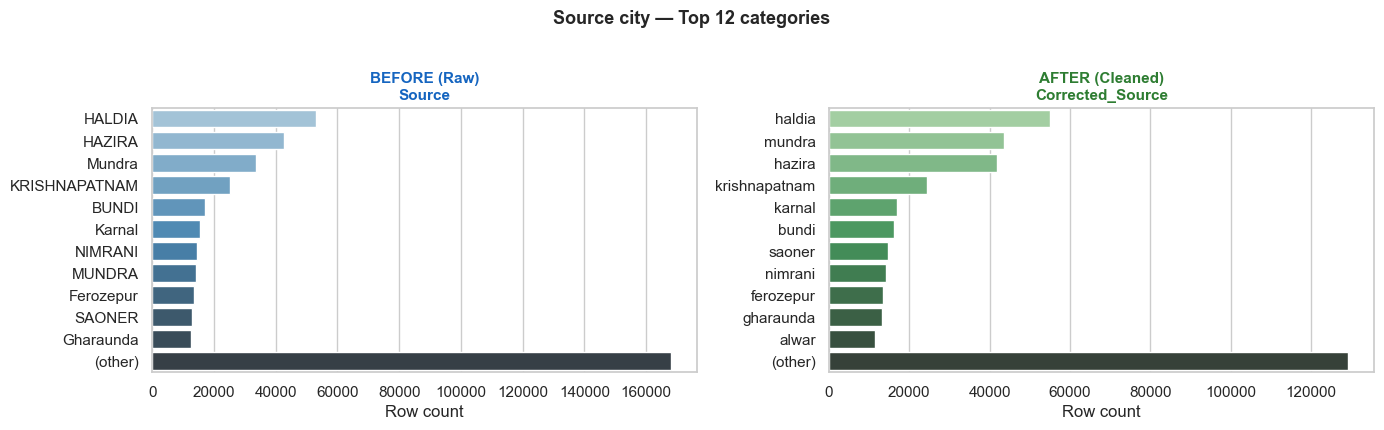

  Source city: raw unique=305 → clean unique=165


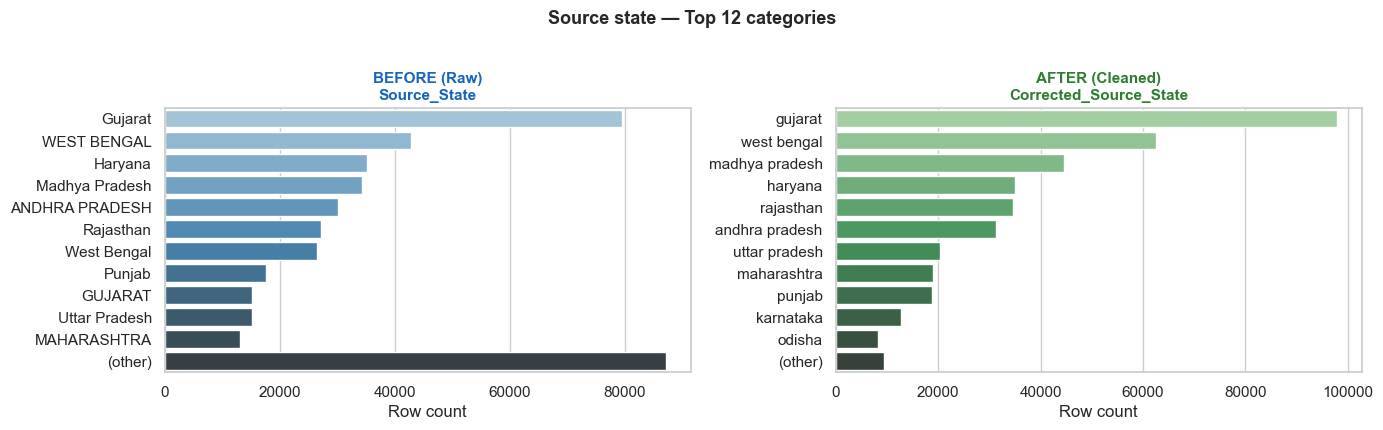

  Source state: raw unique=247 → clean unique=24


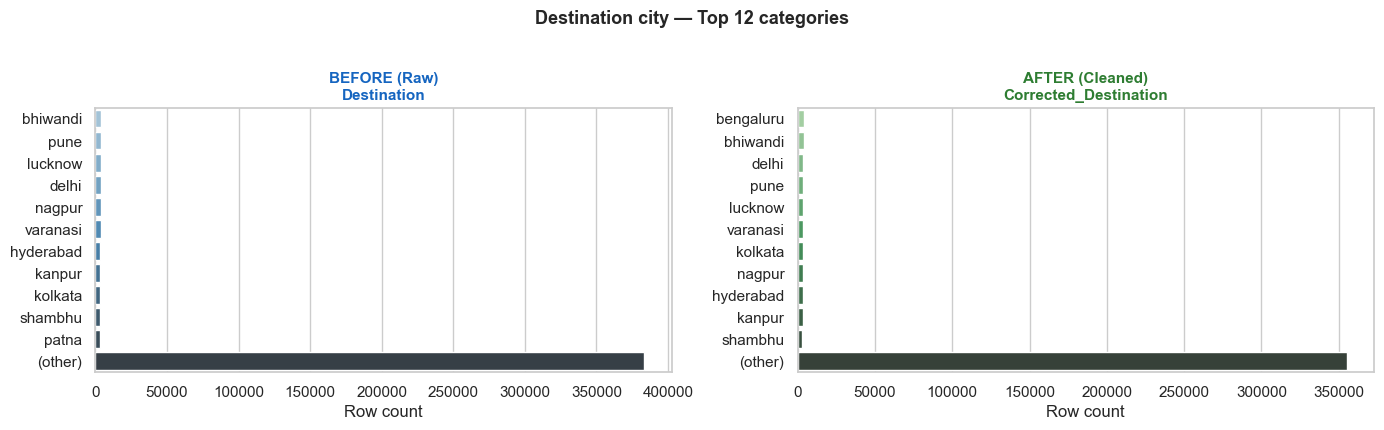

  Destination city: raw unique=3,502 → clean unique=2,780


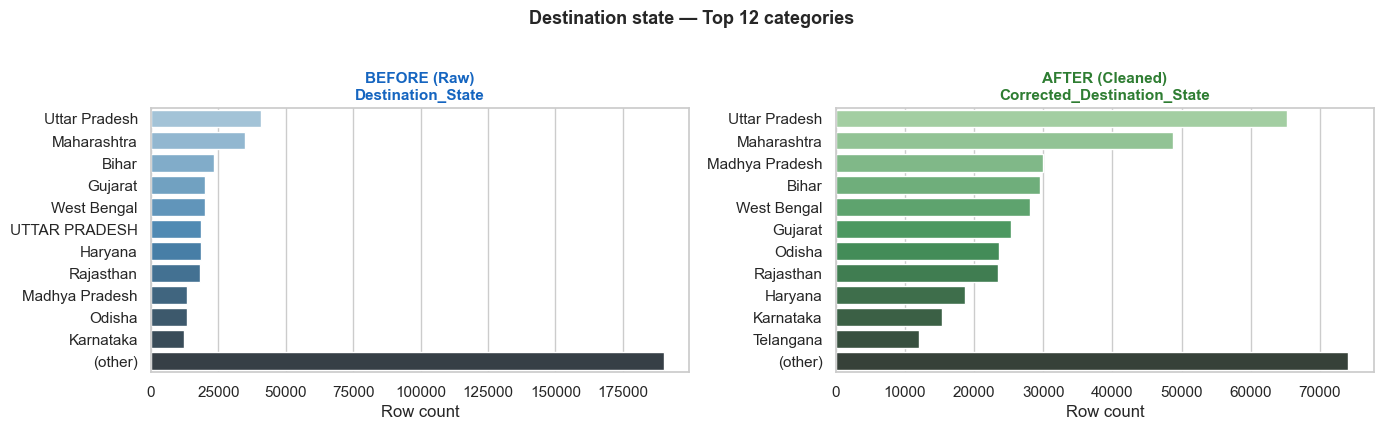

  Destination state: raw unique=1,240 → clean unique=32


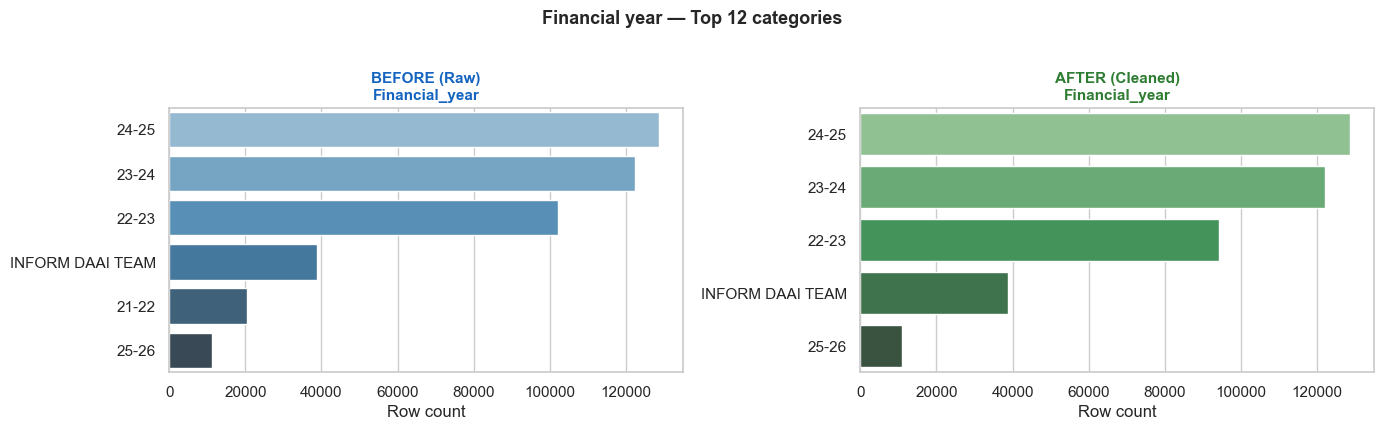

  Financial year: raw unique=6 → clean unique=5


In [198]:
# Side-by-side bar charts for categorical attributes (top N categories)
TOP_N = 12

def _top_counts(series, n=TOP_N):
    s = series.fillna("(missing)").astype(str).str.strip()
    s = s.replace({"": "(missing)", "nan": "(missing)", "None": "(missing)"})
    vc = s.value_counts()
    if len(vc) > n:
        top = vc.head(n - 1)
        other = vc.iloc[n - 1 :].sum()
        top = pd.concat([top, pd.Series({"(other)": other})])
        return top
    return vc.head(n)


for raw_col, clean_col, label, kind in COMPARE_COLUMNS:
    if kind != "categorical":
        continue
    if raw_col not in df_raw_cmp.columns or clean_col not in df_clean_cmp.columns:
        print(f"Skip {label}: column missing")
        continue

    raw_vc = _top_counts(df_raw_cmp[raw_col])
    clean_vc = _top_counts(df_clean_cmp[clean_col])

    fig, axes = plt.subplots(1, 2, figsize=(14, max(4, 0.35 * TOP_N)), sharey=False)
    colors = sns.color_palette("Blues_d", len(raw_vc))
    colors2 = sns.color_palette("Greens_d", len(clean_vc))

    sns.barplot(x=raw_vc.values, y=raw_vc.index, ax=axes[0], palette=colors, orient="h")
    axes[0].set_title(f"BEFORE (Raw)\n{raw_col}", fontsize=11, fontweight="bold", color="#1565C0")
    axes[0].set_xlabel("Row count")
    axes[0].set_ylabel("")

    sns.barplot(x=clean_vc.values, y=clean_vc.index, ax=axes[1], palette=colors2, orient="h")
    axes[1].set_title(f"AFTER (Cleaned)\n{clean_col}", fontsize=11, fontweight="bold", color="#2E7D32")
    axes[1].set_xlabel("Row count")
    axes[1].set_ylabel("")

    fig.suptitle(f"{label} — Top {TOP_N} categories", fontsize=13, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()

    print(
        f"  {label}: raw unique={df_raw_cmp[raw_col].nunique():,} → "
        f"clean unique={df_clean_cmp[clean_col].nunique():,}"
    )


### 4.8 Numeric fields — distribution comparison (histograms)


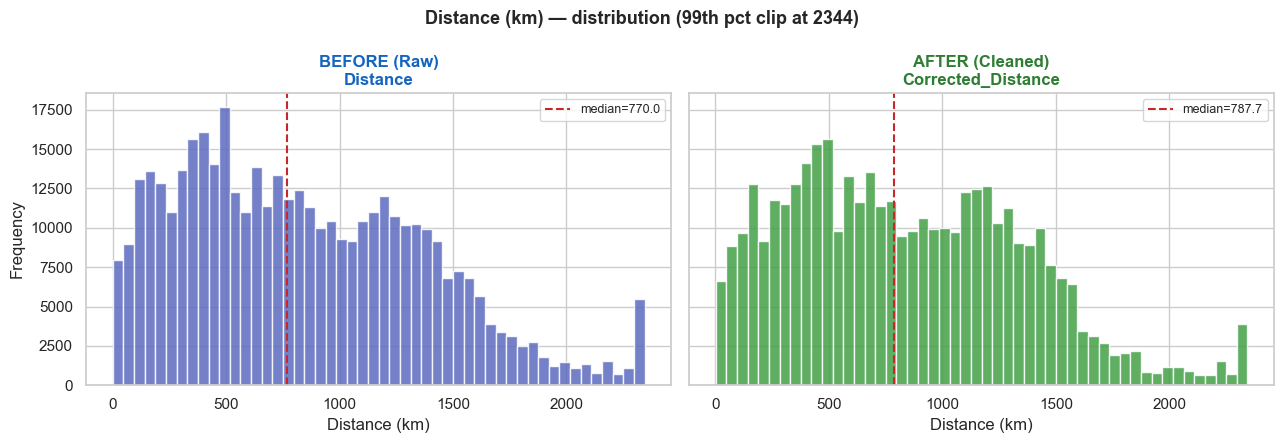

  Distance (km): raw mean=847.7, median=770.0 | clean mean=847.7, median=787.7


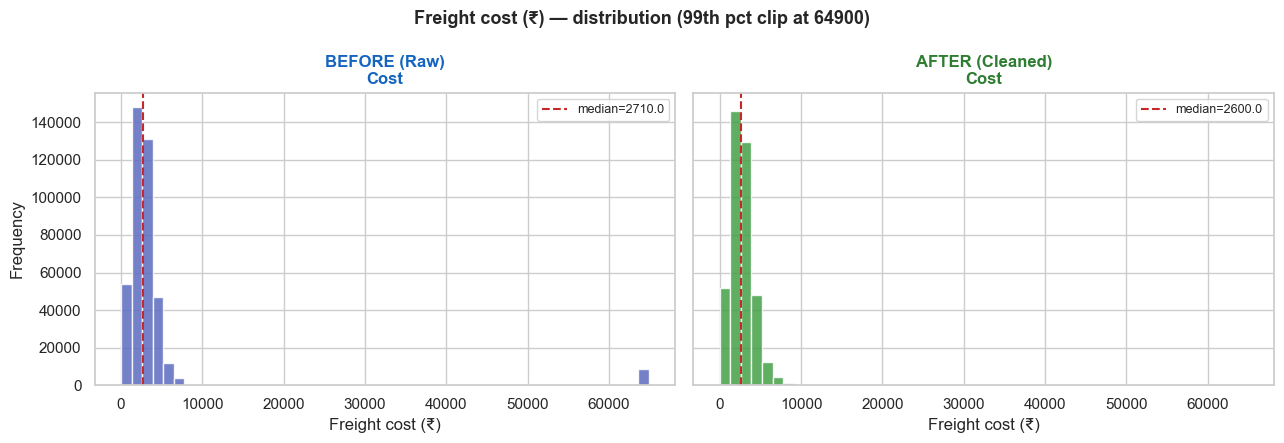

  Freight cost (₹): raw mean=5913.9, median=2710.0 | clean mean=2745.6, median=2600.0


In [199]:
# Side-by-side histograms for numeric attributes
for raw_col, clean_col, label, kind in COMPARE_COLUMNS:
    if kind != "numeric":
        continue
    if raw_col not in df_raw_cmp.columns or clean_col not in df_clean_cmp.columns:
        print(f"Skip {label}: column missing")
        continue

    raw_vals = pd.to_numeric(df_raw_cmp[raw_col], errors="coerce").dropna()
    clean_vals = pd.to_numeric(df_clean_cmp[clean_col], errors="coerce").dropna()
    if raw_vals.empty and clean_vals.empty:
        continue

    hi = np.nanpercentile(
        pd.concat([raw_vals, clean_vals]),
        99,
    )
    lo = 0
    raw_plot = raw_vals.clip(lo, hi)
    clean_plot = clean_vals.clip(lo, hi)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
    axes[0].hist(raw_plot, bins=50, color="#5C6BC0", alpha=0.85, edgecolor="white")
    axes[0].set_title(f"BEFORE (Raw)\n{raw_col}", fontweight="bold", color="#1565C0")
    axes[0].set_xlabel(label)
    axes[0].set_ylabel("Frequency")
    axes[0].axvline(raw_vals.median(), color="#C62828", ls="--", lw=1.5, label=f"median={raw_vals.median():.1f}")
    axes[0].legend(fontsize=9)

    axes[1].hist(clean_plot, bins=50, color="#43A047", alpha=0.85, edgecolor="white")
    axes[1].set_title(f"AFTER (Cleaned)\n{clean_col}", fontweight="bold", color="#2E7D32")
    axes[1].set_xlabel(label)
    axes[1].axvline(clean_vals.median(), color="#C62828", ls="--", lw=1.5, label=f"median={clean_vals.median():.1f}")
    axes[1].legend(fontsize=9)

    fig.suptitle(f"{label} — distribution (99th pct clip at {hi:.0f})", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

    print(
        f"  {label}: raw mean={raw_vals.mean():.1f}, median={raw_vals.median():.1f} | "
        f"clean mean={clean_vals.mean():.1f}, median={clean_vals.median():.1f}"
    )


### 4.9 Transformation impact — % rows changed per attribute


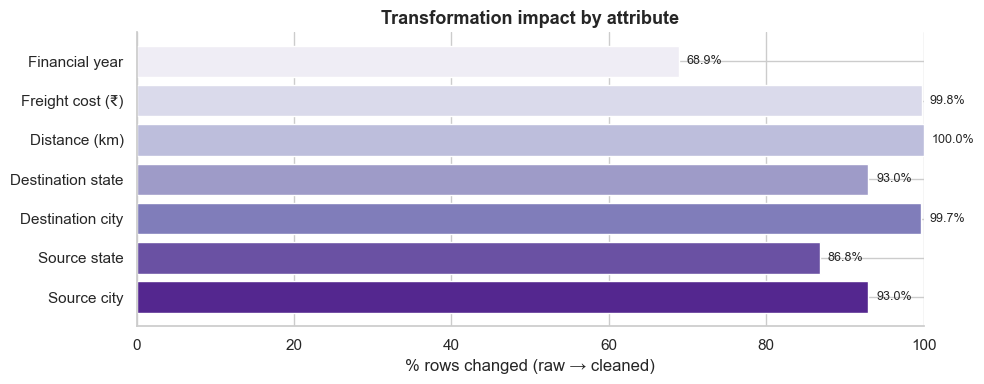

In [200]:
# Bar chart: share of rows changed (raw → cleaned) per attribute
plot_df = compare_summary.dropna(subset=["Pct changed"]).copy()
if not plot_df.empty:
    fig, ax = plt.subplots(figsize=(10, max(4, 0.45 * len(plot_df))))
    bars = ax.barh(
        plot_df["Attribute"],
        plot_df["Pct changed"],
        color=sns.color_palette("Purples_r", len(plot_df)),
    )
    ax.set_xlabel("% rows changed (raw → cleaned)")
    ax.set_title("Transformation impact by attribute", fontsize=13, fontweight="bold")
    ax.set_xlim(0, 100)
    for b, val in zip(bars, plot_df["Pct changed"]):
        ax.text(val + 1, b.get_y() + b.get_height() / 2, f"{val:.1f}%", va="center", fontsize=9)
    sns.despine()
    plt.tight_layout()
    plt.show()
else:
    print("No comparable column pairs for change-rate chart.")


In [191]:
df.columns

Index(['Unnamed: 0.1', 'Unnamed: 0', 'Date', 'Contract_type', 'Route_name',
       'Source', 'Corrected_Source', 'Source_State', 'Corrected_Source_State',
       'Destination', 'Destination_State', 'Distance', 'Vehicle_Type',
       'Vehicle_body_type', 'Pricing_Type', 'Cost', 'Price_per_KM',
       'Vehicle_Load', 'Product', 'week', 'month', 'Month', 'Year',
       'Financial_year', 'Corrected_Destination', 'Vehicle_Type_Original',
       'Corrected_vehicle_Type', 'Corrected_vehicle_body_type',
       'Corrected_Destination_State', 'Source_Latitude', 'Source_Longitude',
       'Destination_Latitude', 'Destination_Longitude', 'Corrected_Distance',
       'Distance_Difference_km', 'Distance_Difference_Pct'],
      dtype='object')

---
<a id="5-Exploratory-Data-Analysis"></a>
# <span style="color:#C62828;">5. Exploratory Data Analysis (EDA)</span>
> **CRISP-DM Phase 2/3 — Visual exploration of the enriched freight dataset**

All graphs from the team's EDA work, organized by analysis theme.

### EDA Setup

In [201]:
# Prepare clean subset (zero-cost rows removed) for EDA visualizations
df_n = df[df['Cost'] > 0].copy()
print(f"Rows after removing zero-cost entries: {len(df_n):,} (removed {len(df) - len(df_n):,})")

# Month ordering for time-axis plots
MONTH_ORDER = ['April','May','June','July','August','September',
               'October','November','December','January','February','March']
MONTH_ORDER = [m for m in MONTH_ORDER if m in df['Month'].unique()]
print("Month order:", MONTH_ORDER)

Rows after removing zero-cost entries: 394,472 (removed 0)
Month order: ['April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December', 'January', 'February', 'March']


<a id="5.1-Distance-vs-Cost-Analysis"></a>
## <span style="color:#D32F2F;">5.1 Distance vs Cost Analysis</span>

#### 5.1 Corrected Distance vs Cost (Scatter)

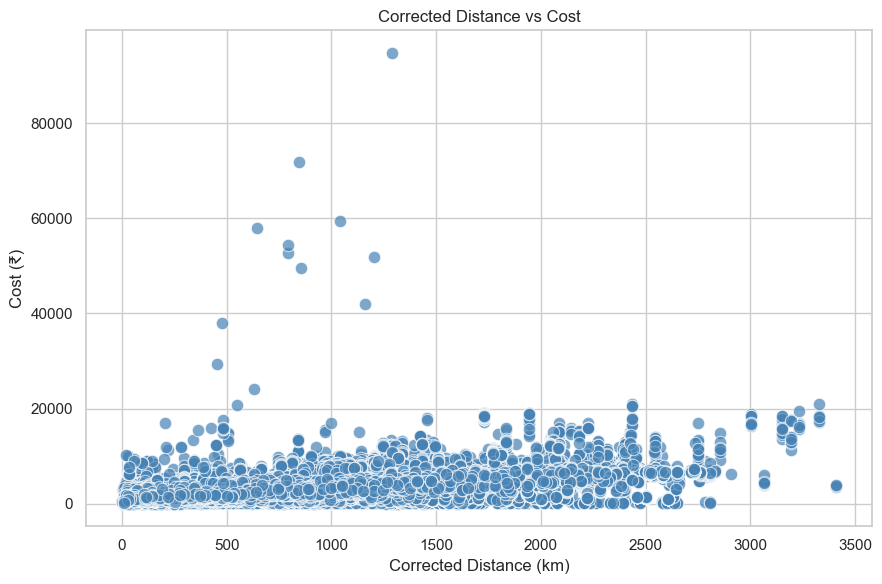

In [202]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='Corrected_Distance', y='Cost',
                alpha=0.7, color='steelblue', edgecolor='white', s=80)
plt.title('Corrected Distance vs Cost')
plt.xlabel('Corrected Distance (km)')
plt.ylabel('Cost (₹)')
plt.tight_layout()
plt.show()

#### 5.1a Removing outlier

In [203]:
# Define red line (upper boundary)
red_slope = (20000 - 8000) / (2250 - 0)
red_intercept = 8000

# Define yellow line (lower boundary)
yellow_slope = (7000 - (-500)) / (3500 - 1500)
yellow_intercept = -500 - yellow_slope * 1500

# Calculate boundary values for each row
red_boundary   = red_slope   * df['Corrected_Distance'] + red_intercept
yellow_boundary = yellow_slope * df['Corrected_Distance'] + yellow_intercept

# Keep only points BELOW the red line AND ABOVE the yellow line
df = df[
    (df['Cost'] < red_boundary) &
    (df['Cost'] > yellow_boundary)
]

print(f"Remaining rows: {len(df)}")

Remaining rows: 393762


#### 5.1b Distance vs Cost – After Removing Outlier

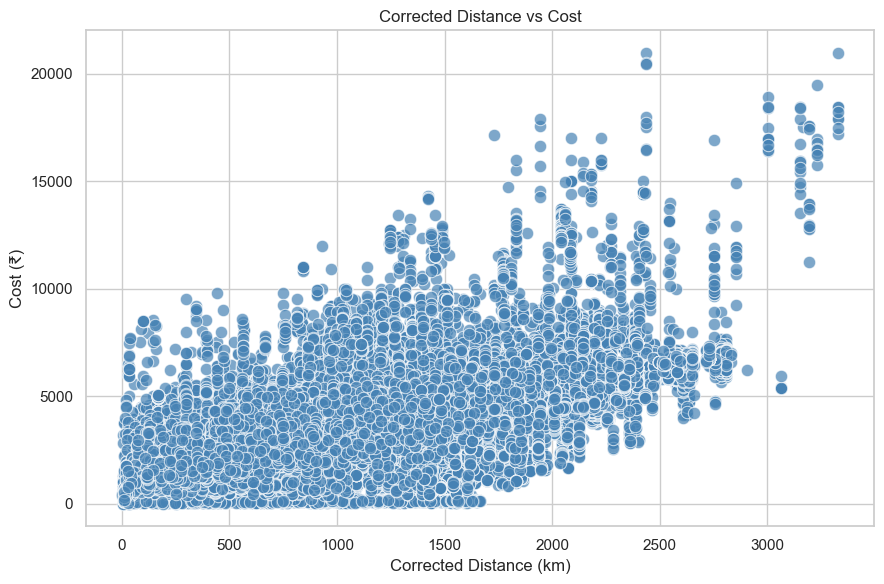

In [204]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='Corrected_Distance', y='Cost',
                alpha=0.7, color='steelblue', edgecolor='white', s=80)
plt.title('Corrected Distance vs Cost')
plt.xlabel('Corrected Distance (km)')
plt.ylabel('Cost (₹)')
plt.tight_layout()
plt.show()

## <span style="color:#D32F2F;">5.2 Contract Type Count with Year</span>

#### 5.2a Count of Shipments by Contract Type & Year

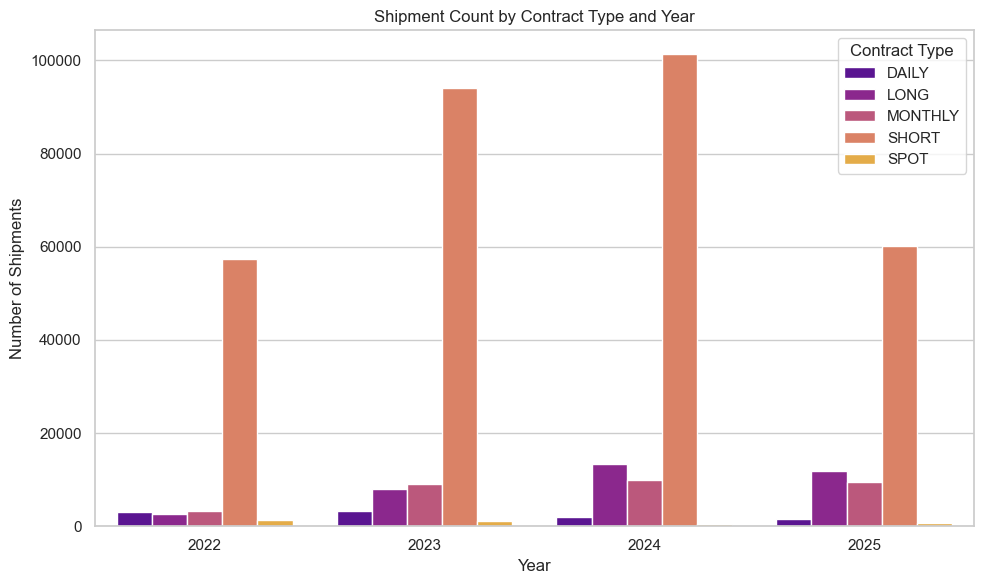

In [205]:
ct_year = df.groupby(['Year', 'Contract_type']).size().reset_index(name='Count')

plt.figure(figsize=(10, 6))
sns.barplot(data=ct_year, x='Year', y='Count',
            hue='Contract_type', palette='plasma')
plt.title('Shipment Count by Contract Type and Year')
plt.xlabel('Year')
plt.ylabel('Number of Shipments')
plt.legend(title='Contract Type')
plt.tight_layout()
plt.show()

#### 5.2b Count Heatmap – Contract Type vs Year

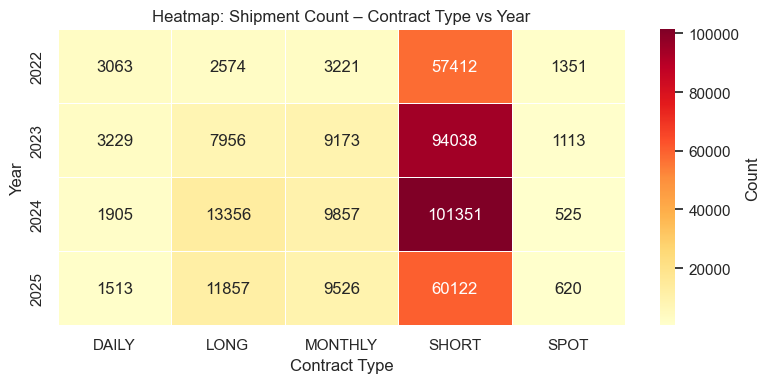

In [206]:
ct_pivot = df.groupby(['Year', 'Contract_type']).size().unstack(fill_value=0)

plt.figure(figsize=(8, 4))
sns.heatmap(ct_pivot, annot=True, fmt='d', cmap='YlOrRd',
            linewidths=0.5, cbar_kws={'label': 'Count'})
plt.title('Heatmap: Shipment Count – Contract Type vs Year')
plt.xlabel('Contract Type')
plt.ylabel('Year')
plt.tight_layout()
plt.show()

## <span style="color:#D32F2F;">5.3 Cost Analysis by Year</span>

#### 5.3a Average Cost by Year

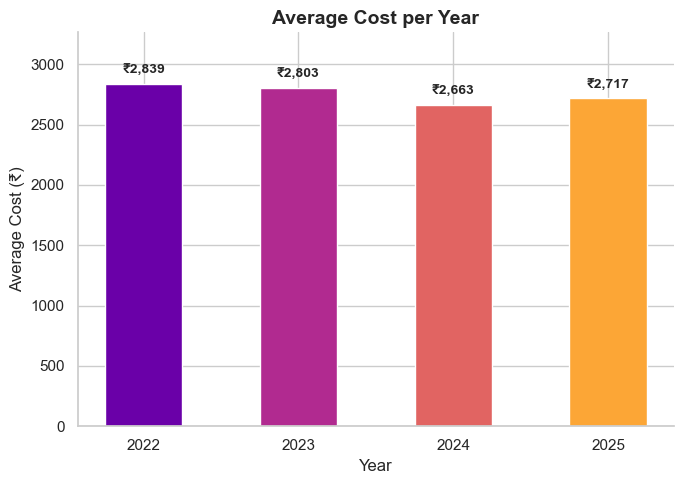

In [207]:
import matplotlib.pyplot as plt
import seaborn as sns

avg_cost_yr = df_n.groupby('Year')['Cost'].mean().reset_index()

plt.figure(figsize=(7, 5))

bars = plt.bar(
    avg_cost_yr['Year'].astype(str),
    avg_cost_yr['Cost'],
    color=sns.color_palette('plasma', len(avg_cost_yr)),
    edgecolor='white',
    width=0.5
)

# ✅ Add extra space on top so labels don't get cut
plt.ylim(0, avg_cost_yr['Cost'].max() * 1.15)

# ✅ Better label placement
for bar in bars:
    val = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        val + (avg_cost_yr['Cost'].max() * 0.02),  # dynamic spacing
        f'₹{val:,.0f}',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

plt.title('Average Cost per Year', fontsize=14, weight='bold')
plt.xlabel('Year')
plt.ylabel('Average Cost (₹)')

sns.despine()
plt.tight_layout()
plt.show()

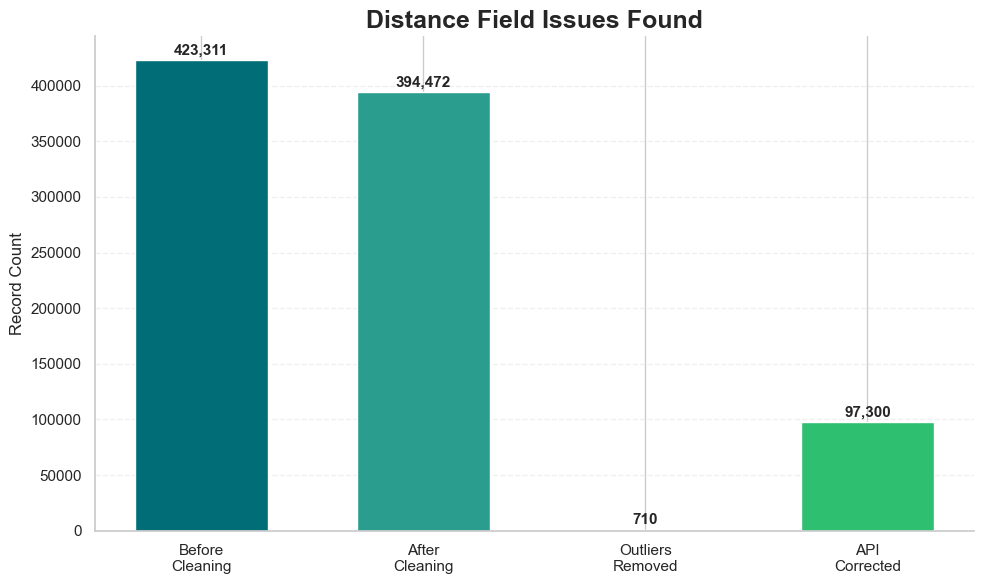

In [16]:
import matplotlib.pyplot as plt

before_cleaning = 423311
after_cleaning = 394472
after_outlier_removal = 393762
api_corrected = 97300

# Derived values
outliers_removed = after_cleaning - after_outlier_removal
categories = [
    "Before\nCleaning",
    "After\nCleaning",
    "Outliers\nRemoved",
    "API\nCorrected"
]

values = [
    before_cleaning,
    after_cleaning,
    outliers_removed,
    api_corrected
]

colors = [
    "#006d77",
    "#2a9d8f",
    "#d62828",
    "#2fbf71"
]
plt.figure(figsize=(10, 6))

bars = plt.bar(
    categories,
    values,
    color=colors,
    width=0.6
)
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 5000,
        f"{int(height):,}",
        ha='center',
        fontsize=11,
        fontweight='bold'
    )
plt.title(
    "Distance Field Issues Found",
    fontsize=18,
    fontweight='bold'
)

plt.ylabel(
    "Record Count",
    fontsize=12
)
ax = plt.gca()

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)

plt.tight_layout()
plt.savefig(
    "distance_issues_bar_chart.png",
    dpi=300,
    bbox_inches='tight'
)
plt.show()

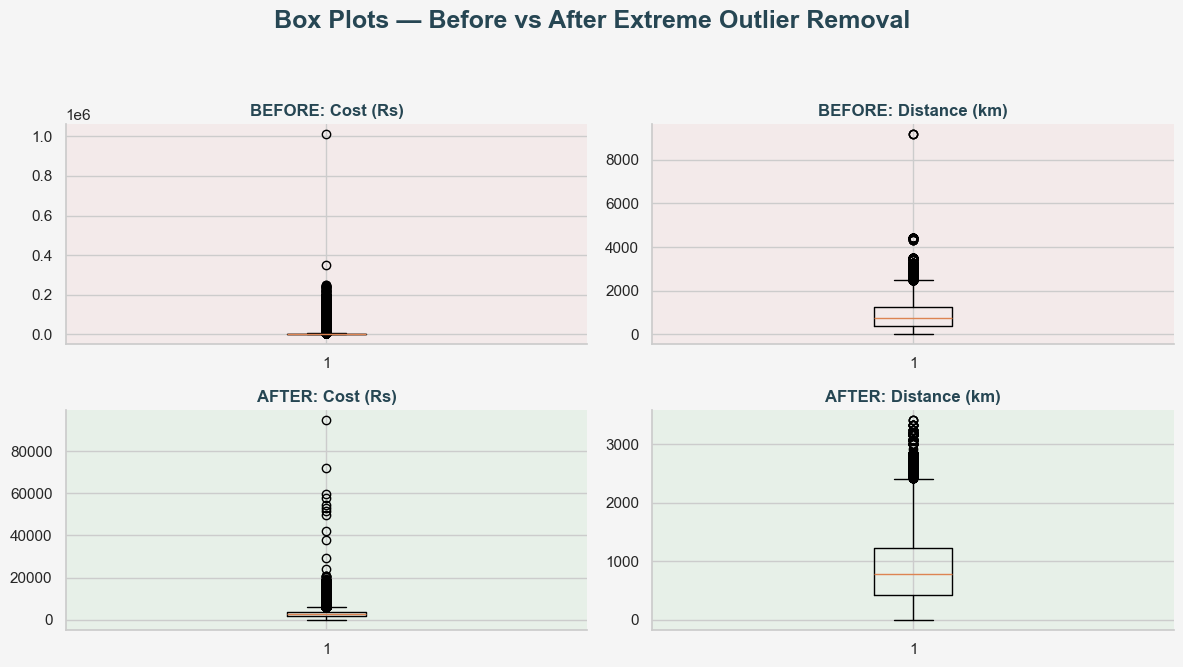

In [17]:
import matplotlib.pyplot as plt
import pandas as pd
# BEFORE cleaning
before_cost = pd.to_numeric(df_raw["Cost"], errors="coerce")
before_distance = pd.to_numeric(df_raw["Distance"], errors="coerce")

# AFTER cleaning
after_cost = pd.to_numeric(df_clean["Cost"], errors="coerce")
after_distance = pd.to_numeric(df_clean["Corrected_Distance"], errors="coerce")
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

fig.patch.set_facecolor("#f5f5f5")

fig.suptitle(
    "Box Plots — Before vs After Extreme Outlier Removal",
    fontsize=18,
    fontweight='bold',
    color='#264653'
)
axes[0, 0].boxplot(before_cost.dropna())
axes[0, 0].set_title(
    "BEFORE: Cost (Rs)",
    fontsize=12,
    fontweight='bold',
    color='#264653'
)
axes[0, 0].set_facecolor("#f3eaea")
axes[0, 1].boxplot(before_distance.dropna())
axes[0, 1].set_title(
    "BEFORE: Distance (km)",
    fontsize=12,
    fontweight='bold',
    color='#264653'
)

axes[0, 1].set_facecolor("#f3eaea")
axes[1, 0].boxplot(after_cost.dropna())

axes[1, 0].set_title(
    "AFTER: Cost (Rs)",
    fontsize=12,
    fontweight='bold',
    color='#264653'
)
axes[1, 0].set_facecolor("#e7f0e8")
axes[1, 1].boxplot(after_distance.dropna())

axes[1, 1].set_title(
    "AFTER: Distance (km)",
    fontsize=12,
    fontweight='bold',
    color='#264653'
)

axes[1, 1].set_facecolor("#e7f0e8")
for ax in axes.flat:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
plt.tight_layout(rect=[0, 0.03, 1, 0.93])
plt.savefig(
    "before_after_outlier_boxplots.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

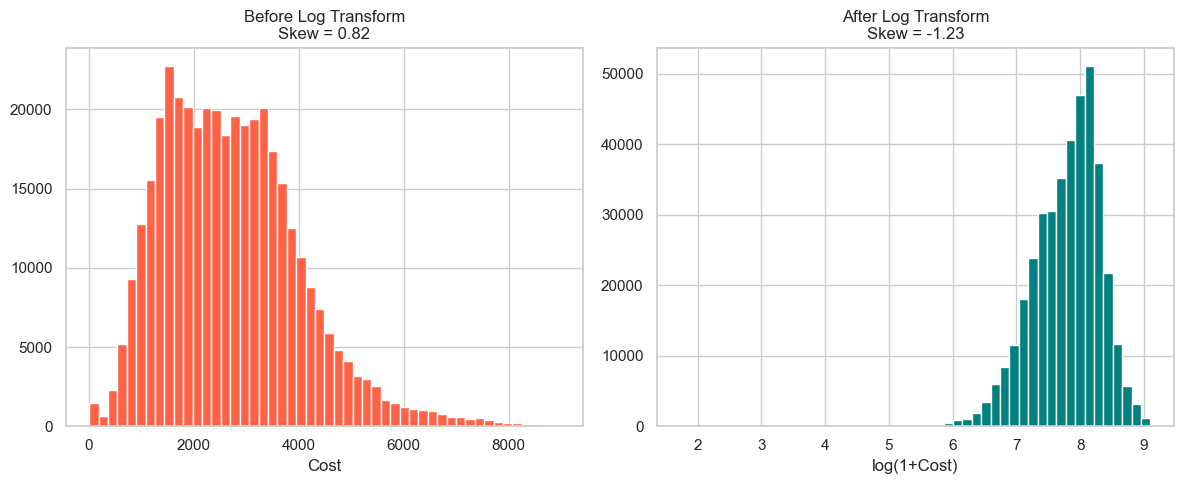

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==============================
# COST PREPARATION
# ==============================
cost = pd.to_numeric(df_clean["Cost"], errors="coerce").dropna()
# Remove extreme outliers (3xIQR)
Q1, Q3 = cost.quantile([0.25, 0.75])
IQR = Q3 - Q1
upper = Q3 + 3 * IQR

filtered_cost = cost[cost <= upper]

# Log Transform
log_cost = np.log1p(filtered_cost)

# Skewness
before_skew = round(filtered_cost.skew(), 2)
after_skew = round(log_cost.skew(), 2)

# ==============================
# DISTRIBUTION PLOTS
# ==============================

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].hist(filtered_cost, bins=50, color="tomato", edgecolor="white")
ax[0].set_title(f"Before Log Transform\nSkew = {before_skew}")
ax[0].set_xlabel("Cost")

ax[1].hist(log_cost, bins=50, color="teal", edgecolor="white")
ax[1].set_title(f"After Log Transform\nSkew = {after_skew}")
ax[1].set_xlabel("log(1+Cost)")

plt.tight_layout()
plt.show()

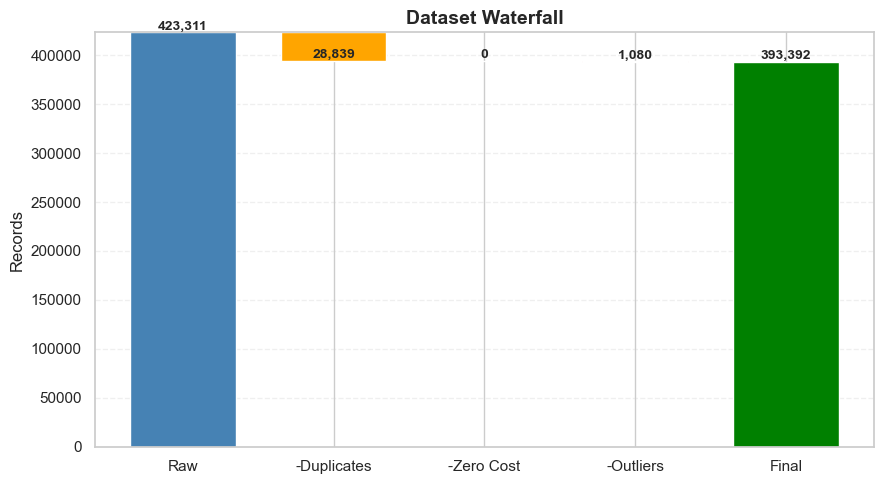

In [7]:
import matplotlib.pyplot as plt
raw = len(df_raw)
duplicates = raw - len(df_clean)
zero_cost = (df_clean["Cost"] <= 0).sum()
outliers = (cost > upper).sum()
final = len(filtered_cost)
labels = ["Raw", "-Duplicates", "-Zero Cost", "-Outliers", "Final"]
values = [raw, -duplicates, -zero_cost, -outliers, final]
bottoms = [
    0,
    raw,
    raw - duplicates,
    raw - duplicates - zero_cost,
    0
]
colors = ["steelblue", "orange", "gold", "crimson", "green"]
plt.figure(figsize=(9,5))
for i in range(len(labels)):
    plt.bar(
        labels[i],
        values[i],
        bottom=bottoms[i],
        color=colors[i],
        width=0.7
    )
    if i == 0:
        y = raw

    elif i == 4:
        y = final

    else:
        y = bottoms[i] + values[i]

    plt.text(
        i,
        y + 3000,
        f"{abs(values[i]):,}",
        ha='center',
        fontsize=10,
        fontweight='bold'
    )
plt.title("Dataset Waterfall", fontsize=14, fontweight='bold')
plt.ylabel("Records")
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
import pandas as pd

# =========================================================
# FUNCTION TO CALCULATE OUTLIER METRICS
# =========================================================

def outlier_summary(series, feature_name):

    series = pd.to_numeric(series, errors='coerce').dropna()

    # Quartiles
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    # IQR
    iqr = q3 - q1

    # Bounds
    iqr_bound = q3 + (1.5 * iqr)
    bound_3x = q3 + (3 * iqr)

    # Outliers
    iqr_outliers = (series > iqr_bound).sum()
    outliers_3x = (series > bound_3x).sum()

    # Percentages
    iqr_pct = (iqr_outliers / len(series)) * 100
    pct_3x = (outliers_3x / len(series)) * 100

    return {
        "Feature": feature_name,
        "Q1": round(q1),
        "Q3": round(q3),
        "IQR": round(iqr),
        "1.5xIQR Bound": round(iqr_bound),
        "3xIQR Bound": round(bound_3x),
        "IQR Outliers": f"{iqr_outliers:,}",
        "IQR %": f"{iqr_pct:.2f}%",
        "3xIQR Rows": f"{outliers_3x:,}",
        "3xIQR %": f"{pct_3x:.2f}%"
    }

# =========================================================
# CREATE SUMMARY TABLE
# =========================================================

distance_summary = outlier_summary(
    df_clean["Corrected_Distance"],
    "Distance"
)

cost_summary = outlier_summary(
    df_clean["Cost"],
    "Cost"
)

summary_df = pd.DataFrame([
    distance_summary,
    cost_summary
])

# =========================================================
# DISPLAY
# =========================================================

print(summary_df)

# Optional: Save table
summary_df.to_csv(
    "outlier_summary_table.csv",
    index=False
)

    Feature    Q1    Q3   IQR  1.5xIQR Bound  3xIQR Bound IQR Outliers  IQR %  \
0  Distance   427  1218   791           2405         3592        1,869  0.47%   
1      Cost  1690  3510  1820           6240         8970        7,824  1.98%   

  3xIQR Rows 3xIQR %  
0          0   0.00%  
1      1,080   0.27%  


#### 5.3b Cost Distribution by Year (Violin)

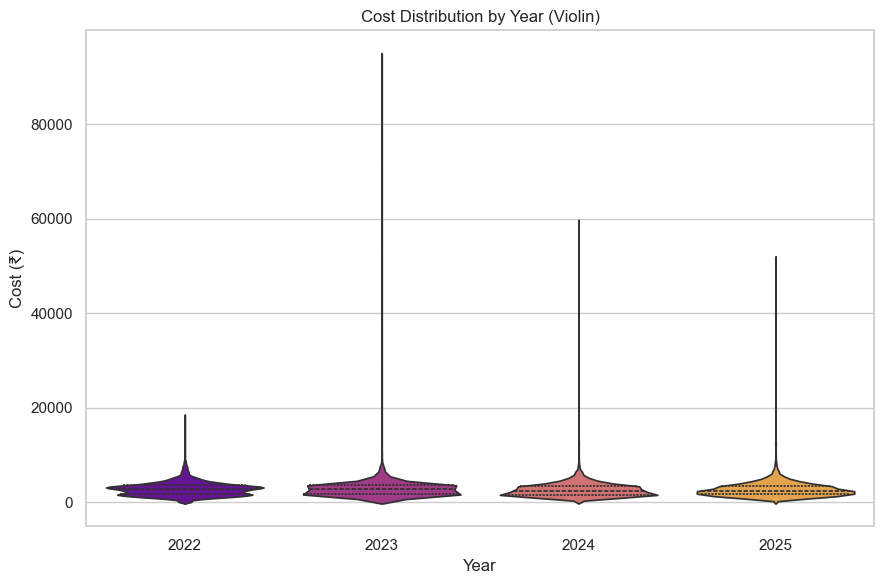

In [208]:
plt.figure(figsize=(9, 6))
sns.violinplot(x='Year', y='Cost', data=df_n,
               palette='plasma', inner='quartile')
plt.title('Cost Distribution by Year (Violin)')
plt.xlabel('Year')
plt.ylabel('Cost (₹)')
plt.tight_layout()
plt.show()

#### 5.3c Average Cost by Year & Contract Type

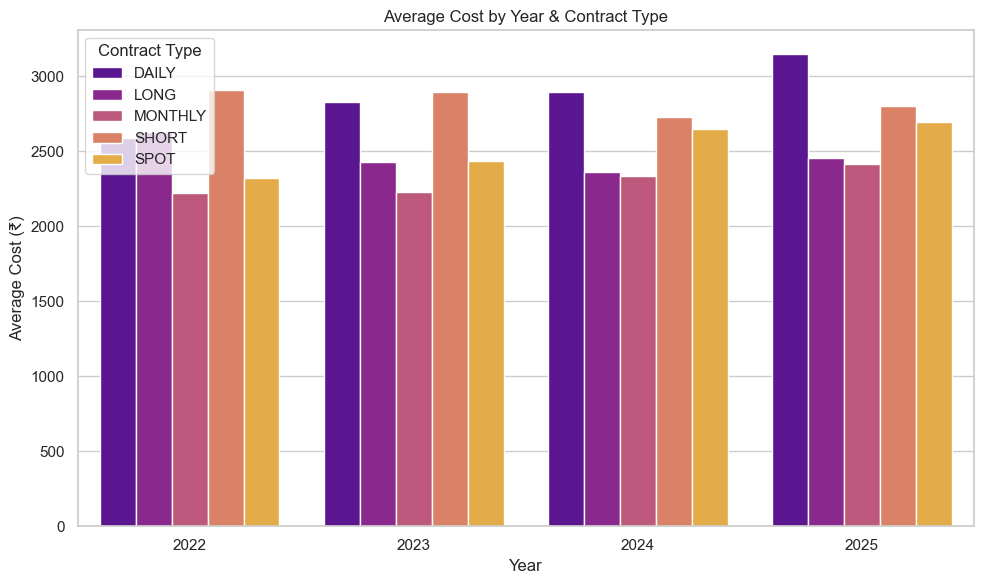

In [209]:
cost_yr_ct = df_n.groupby(['Year', 'Contract_type'])['Cost'].mean().reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(data=cost_yr_ct, x='Year', y='Cost',
            hue='Contract_type', palette='plasma')
plt.title('Average Cost by Year & Contract Type')
plt.xlabel('Year')
plt.ylabel('Average Cost (₹)')
plt.legend(title='Contract Type')
plt.tight_layout()
plt.show()

#### 5.3d Total Cost by Month & Year (Line Trend)

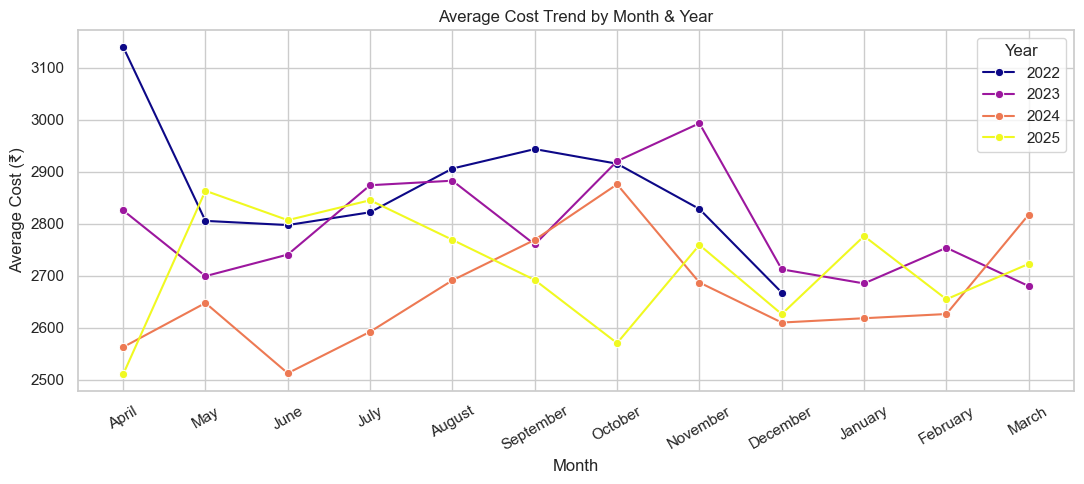

In [210]:
monthly_yr = df_n.groupby(['Year', 'Month'])['Cost'].mean().reset_index()
monthly_yr['Month'] = pd.Categorical(monthly_yr['Month'],
                                      categories=MONTH_ORDER, ordered=True)
monthly_yr = monthly_yr.sort_values(['Year', 'Month'])

plt.figure(figsize=(11, 5))
sns.lineplot(data=monthly_yr, x='Month', y='Cost',
             hue='Year', marker='o', palette='plasma')
plt.title('Average Cost Trend by Month & Year')
plt.xlabel('Month')
plt.ylabel('Average Cost (₹)')
plt.xticks(rotation=30)
plt.legend(title='Year')
plt.tight_layout()
plt.show()

#### 5.3e Monthly Average Cost by Contract Type and Year

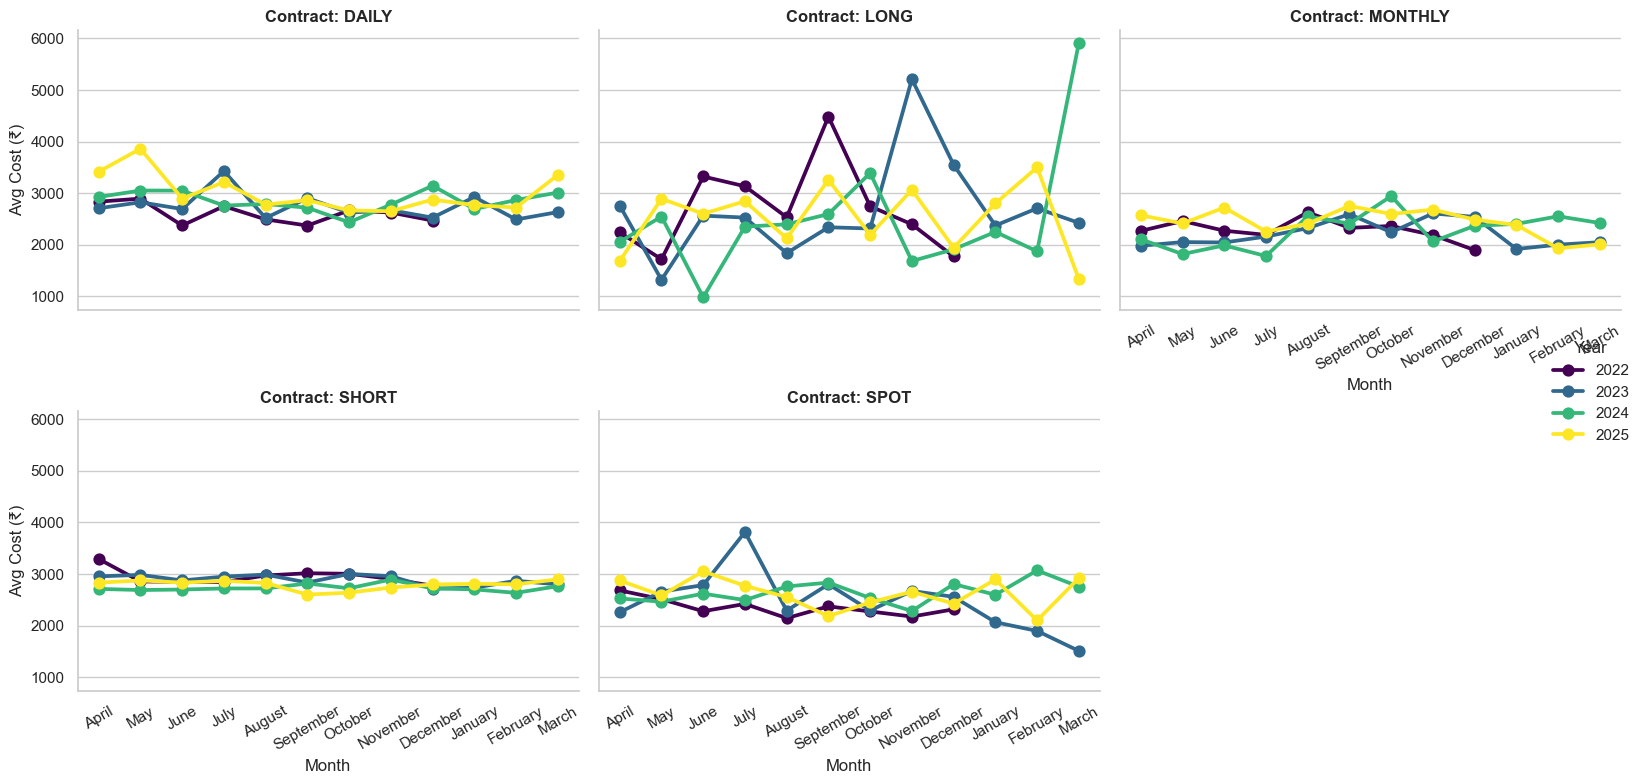

In [211]:
monthly_contract = df_n.groupby(
    ['Contract_type', 'Month', 'Year']
)['Cost'].mean().reset_index()

monthly_contract['Month'] = pd.Categorical(
    monthly_contract['Month'],
    categories=MONTH_ORDER,
    ordered=True
)

monthly_contract = monthly_contract.sort_values(['Year', 'Month'])


sns.set_theme(style="whitegrid")

g = sns.catplot(
    data=monthly_contract,
    x='Month',
    y='Cost',
    col='Contract_type',      # 🔥 each contract type separate panel
    hue='Year',               # compare years inside each
    kind='point',
    col_wrap=3,               # clean layout
    height=4,
    aspect=1.3,
    palette='viridis',
    markers='o',
    linestyles='-'
)

# Titles & labels
g.set_titles("Contract: {col_name}", size=12, weight='bold')
g.set_axis_labels("Month", "Avg Cost (₹)")

# Rotate month labels
for ax in g.axes.flat:
    ax.tick_params(axis='x', rotation=30)

# Better legend
g._legend.set_title("Year")

plt.tight_layout()
plt.show()

## <span style="color:#D32F2F;">5.4 Vehicle Body Type Analysis</span>

#### 5.4a Vehicle Body Type – Pie Chart

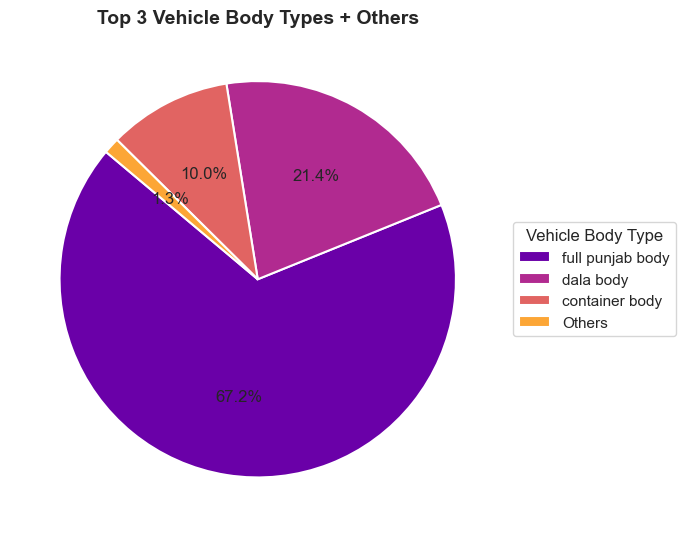

In [212]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get counts
vb_counts = df['Vehicle_body_type'].value_counts()

# Top 3
top3 = vb_counts.head(3)

# Others
others = vb_counts.iloc[3:].sum()

# Combine
final_counts = top3.copy()
final_counts['Others'] = others

# Plot
plt.figure(figsize=(7, 7))

colors = sns.color_palette('plasma', len(final_counts))

plt.pie(
    final_counts,
    labels=None,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)

plt.legend(
    final_counts.index,
    title="Vehicle Body Type",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.title('Top 3 Vehicle Body Types + Others', fontsize=14, weight='bold')

plt.tight_layout()
plt.show()

## <span style="color:#D32F2F;">5.5 Product Analysis</span>

#### 5.5a Average Cost by Product

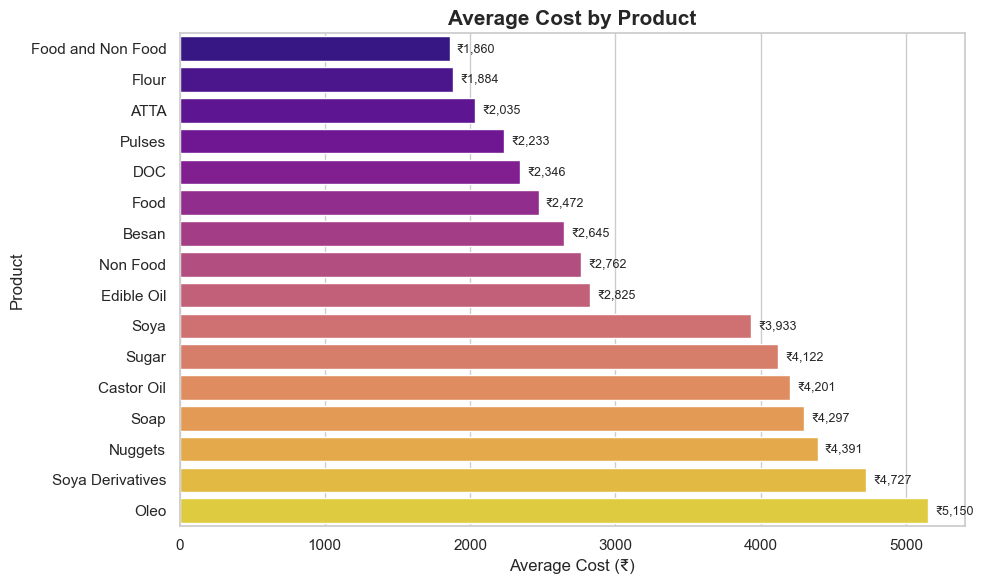

In [213]:
import matplotlib.pyplot as plt
import seaborn as sns

prod_cost = df_n.groupby('Product')['Cost'].mean().reset_index()

# Sort for better readability
prod_cost = prod_cost.sort_values('Cost')

plt.figure(figsize=(10, 6))

bars = sns.barplot(
    data=prod_cost,
    y='Product',     # 👈 switch axis
    x='Cost',
    palette='plasma'
)

# Add labels
for bar in bars.patches:
    val = bar.get_width()
    plt.text(
        val + 50,
        bar.get_y() + bar.get_height()/2,
        f'₹{val:,.0f}',
        va='center',
        fontsize=9
    )

plt.title('Average Cost by Product', fontsize=15, weight='bold')
plt.xlabel('Average Cost (₹)')
plt.ylabel('Product')

plt.tight_layout()
plt.show()

## <span style="color:#D32F2F;">5.6 Cost Trend per Month & Contract Type</span>

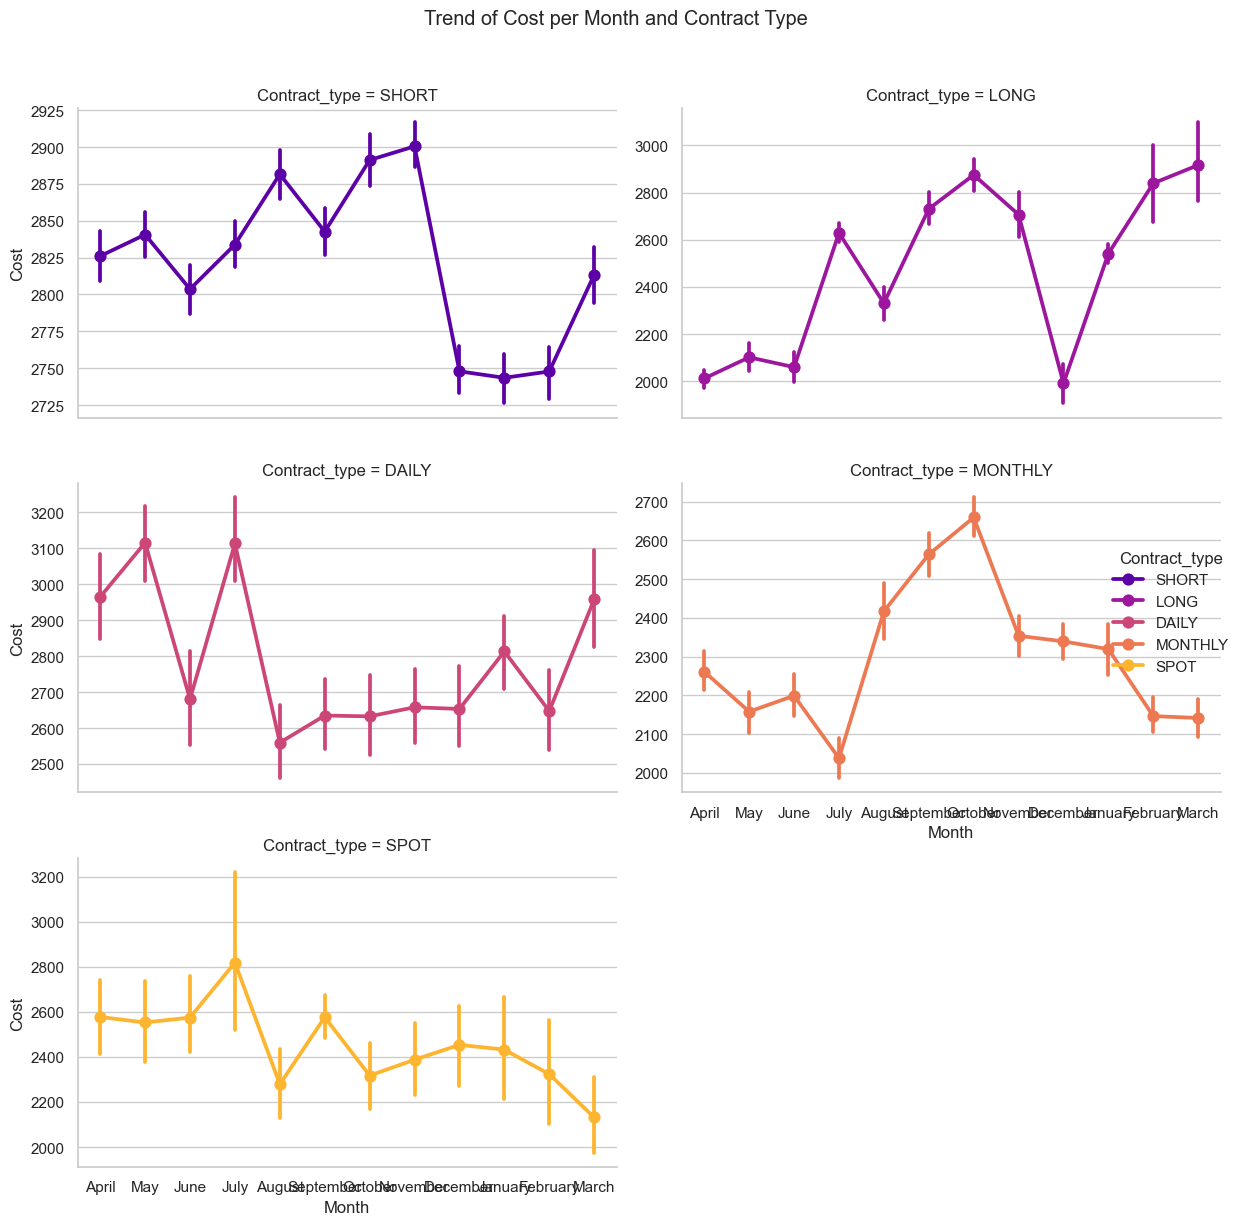

In [214]:
# Join month ordering
df_plot = df_n.copy()
df_plot['Month'] = pd.Categorical(df_plot['Month'], categories=MONTH_ORDER, ordered=True)
df_plot = df_plot.sort_values('Month')

sns.catplot(
    data=df_plot,
    x='Month',
    y='Cost',
    col='Contract_type',    # one subplot per Contract Type (horizontally)
    hue='Contract_type',
    palette='plasma',
    kind='point',
    col_wrap=2,
    height=4, aspect=1.4,
    sharey=False
)
plt.suptitle('Trend of Cost per Month and Contract Type', y=1.02)
plt.tight_layout()
plt.show()

## <span style="color:#D32F2F;">5.7 Cost Trend per Month & Vehicle Type (Top 5)</span>

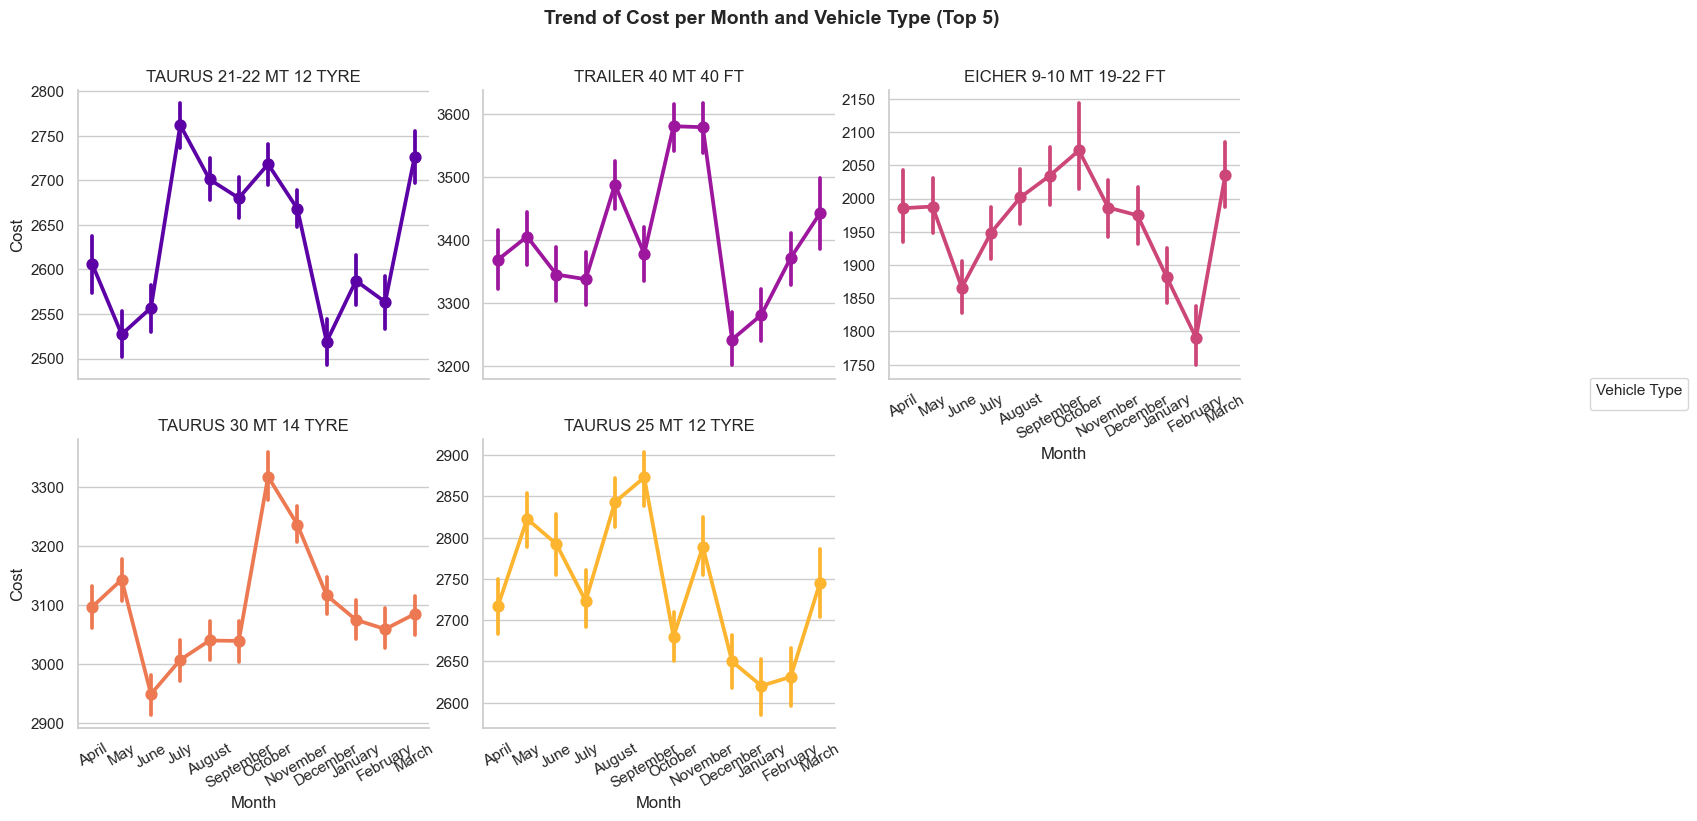

In [215]:
import seaborn as sns
import matplotlib.pyplot as plt

# Top 5 vehicle types
top5_veh = df_n['Vehicle_Type'].value_counts().head(5).index
df_veh = df_n[df_n['Vehicle_Type'].isin(top5_veh)].copy()

df_veh['Month'] = pd.Categorical(df_veh['Month'],
                                categories=MONTH_ORDER,
                                ordered=True)

df_veh = df_veh.sort_values('Month')

sns.set_theme(style="whitegrid")

g = sns.catplot(
    data=df_veh,
    x='Month',
    y='Cost',
    col='Vehicle_Type',
    hue='Vehicle_Type',
    kind='point',
    palette='plasma',
    col_wrap=3,
    height=4,
    aspect=1.3,
    sharey=False,
    legend=False   # ❗ disable default legend
)

# ✅ Add legend OUTSIDE
g.fig.legend(
    title='Vehicle Type',
    loc='center left',
    bbox_to_anchor=(1.02, 0.5),   # move to right side
    fontsize=10,
    title_fontsize=11
)

# Titles
g.set_titles("{col_name}")
g.set_axis_labels("Month", "Cost")

# Rotate x labels
for ax in g.axes.flat:
    ax.tick_params(axis='x', rotation=30)

# Adjust layout to make space for legend
plt.subplots_adjust(right=0.80, top=0.88)

plt.suptitle(
    "Trend of Cost per Month and Vehicle Type (Top 5)",
    fontsize=14,
    weight='bold'
)

plt.show()

## <span style="color:#D32F2F;">5.8 Vehicle Load Analysis</span>

#### 5.8a Vehicle Load Distribution

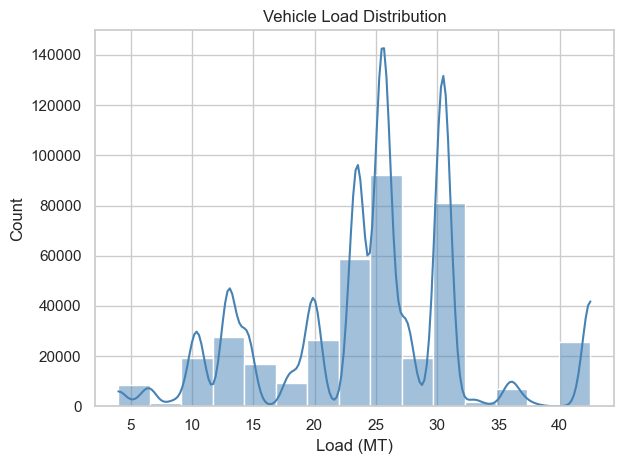

In [216]:
sns.histplot(df_n['Vehicle_Load'], bins=15, kde=True, color='steelblue')
plt.title('Vehicle Load Distribution')
plt.xlabel('Load (MT)')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

#### 5.8b Vehicle Load vs Cost

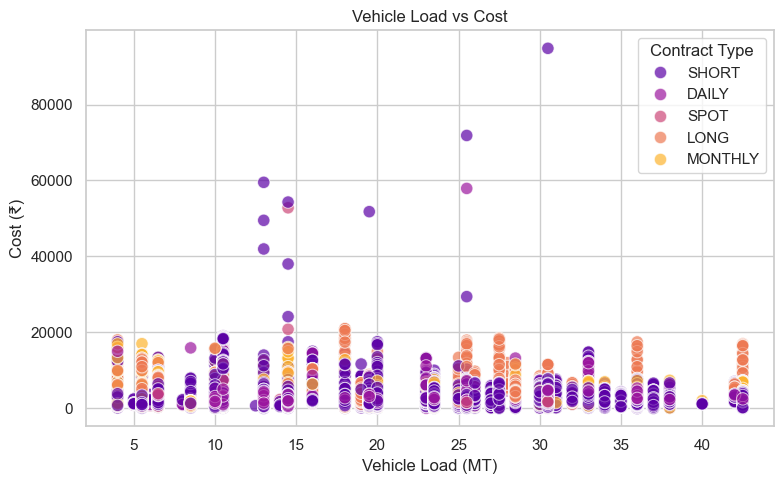

In [217]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_n, x='Vehicle_Load', y='Cost',
                hue='Contract_type', palette='plasma', alpha=0.7, s=80)
plt.title('Vehicle Load vs Cost')
plt.xlabel('Vehicle Load (MT)')
plt.ylabel('Cost (₹)')
plt.legend(title='Contract Type')
plt.tight_layout()
plt.show()

#### 5.8c Average Vehicle Load by Vehicle Type (Top 8)

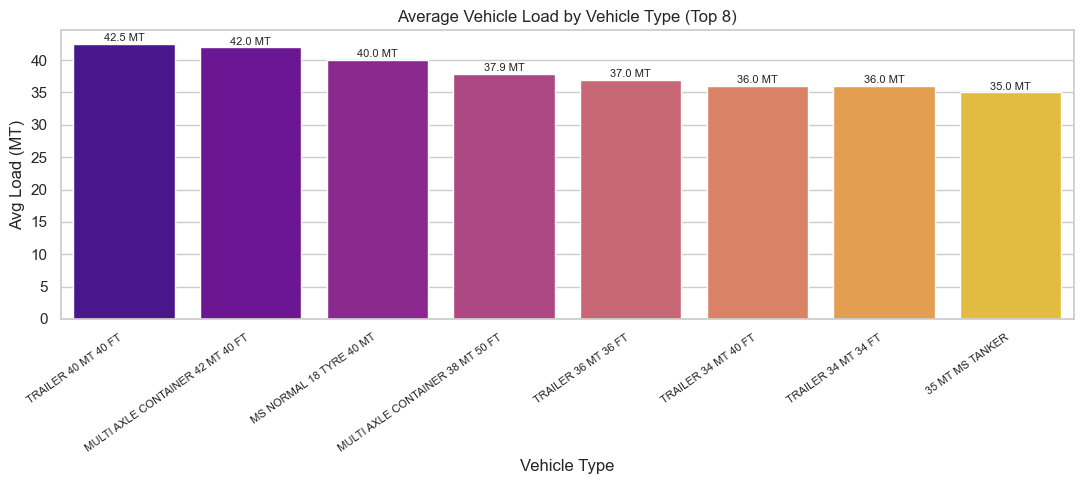

In [218]:
vl_vt = df_n.groupby('Vehicle_Type')['Vehicle_Load'].mean().sort_values(ascending=False).head(8).reset_index()

plt.figure(figsize=(11, 5))
bars = sns.barplot(data=vl_vt, x='Vehicle_Type', y='Vehicle_Load', palette='plasma')
for bar, val in zip(bars.patches, vl_vt['Vehicle_Load']):
    bars.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
              f'{val:.1f} MT', ha='center', va='bottom', fontsize=8)
plt.title('Average Vehicle Load by Vehicle Type (Top 8)')
plt.xlabel('Vehicle Type')
plt.ylabel('Avg Load (MT)')
plt.xticks(rotation=35, ha='right', fontsize=8)
plt.tight_layout()
plt.show()

## <span style="color:#D32F2F;">5.9 Price per KM by Financial Year (Violin)</span>

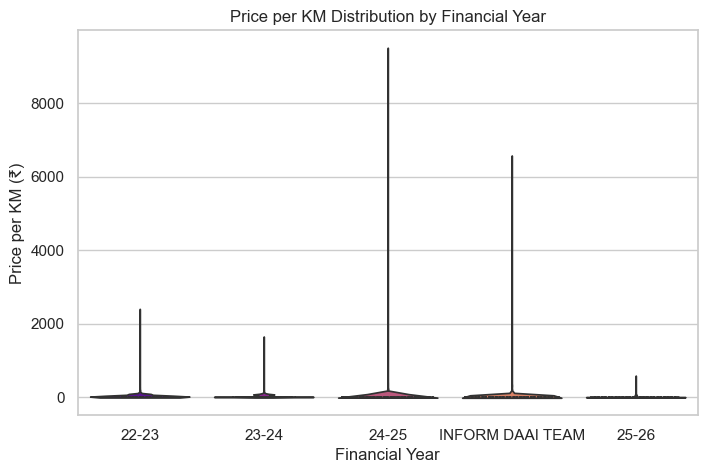

In [219]:
plt.figure(figsize=(8, 5))
sns.violinplot(x='Financial_year', y='Price_per_KM', data=df_n,
               palette='plasma', inner='quartile')
plt.title('Price per KM Distribution by Financial Year')
plt.xlabel('Financial Year')
plt.ylabel('Price per KM (₹)')
plt.show()

## <span style="color:#D32F2F;">5.10 Correlation Heatmap</span>

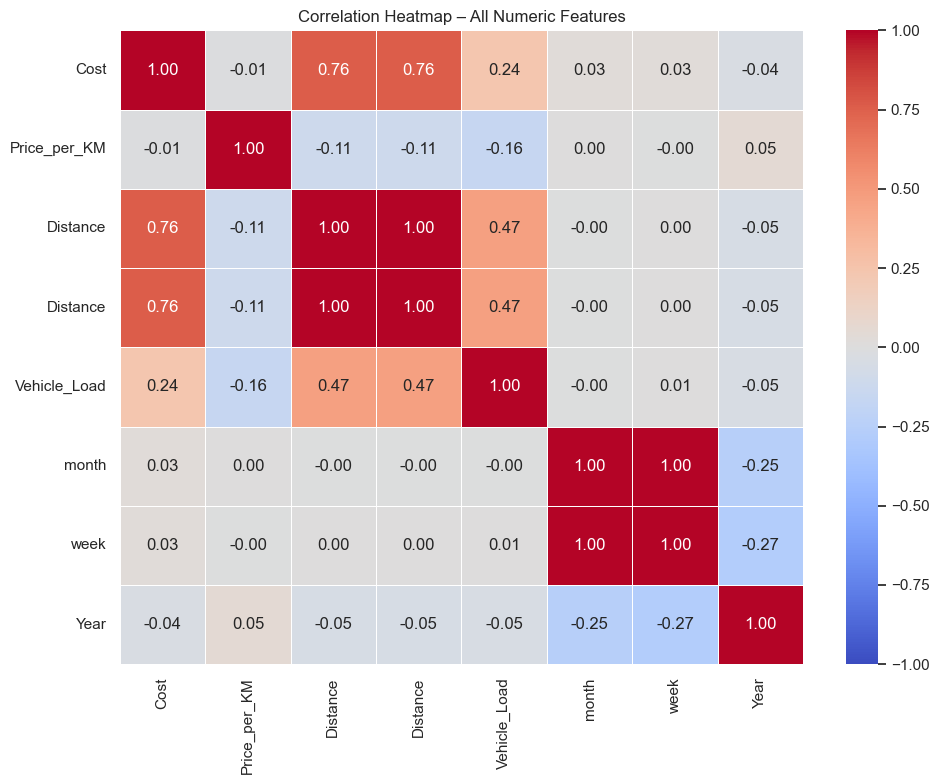

In [220]:
num_cols = ['Cost', 'Price_per_KM', 'Distance', 'Distance',
            'Vehicle_Load', 'month', 'week', 'Year']

plt.figure(figsize=(10, 8))
corr = df_n[num_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Heatmap – All Numeric Features')
plt.tight_layout()
plt.show()

---
<h2 align="center" style="color:#1E3A5F;">✅ Pipeline Complete — FreightIQ Unified Notebook</h2>
<p align="center" style="color:#78909C;">All data understanding, cleaning, enrichment, and EDA steps consolidated into a single reproducible workflow.<br><strong>No external JSON files, no scripts, no API calls needed.</strong></p>